# Riesgo de ampliación del plazo en contratos públicos (SECOP II)

**Autores:** Kevin Pabón Niño, Jose Alejandro Jimenez y Geronimo Montes Acebedo. Proyecto final de aprendizaje automático, EAFIT, 2026-2.

Modelo que, al firmar un contrato estatal, estima la probabilidad de que termine con el plazo ampliado (prórroga, suspensión o ajuste de fechas). Lo usan veedurías y oficinas de control interno para priorizar qué contratos vigilar.

**Fuente de datos:** Datos Abiertos Colombia (datos.gov.co), Agencia Nacional de Contratación Pública – Colombia Compra Eficiente. Licencia CC BY-SA 4.0. Conjuntos: Contratos Electrónicos (`jbjy-vk9h`), Procesos de Contratación (`p6dx-8zbt`) y Modificaciones a contratos (`u8cx-r425`).

## Contenido

| Sección | Qué cubre |
|---|---|
| 3.1 | Definición del problema, usuarios y qué ingresa el usuario |
| 3.2 | Preprocesamiento: faltantes, atípicos, codificación y escalado |
| 3.3 | Análisis exploratorio (EDA): calidad, deriva, censura, etiqueta, hipótesis H1-H7, privacidad y fuga |
| 3.4 y 3.5 | Paradigma, metodología y selección del modelo (entrenamiento paso a paso) |
| 3.6 | Generalización: test 2024, deriva 2025, entidades no vistas, ablación, contraste «con fuga» y SHAP |
| 3.7 | Métricas justificadas en términos de uso |
| 3.8 | Despliegue e interfaz |
| 3.9 | Estrategia de reajuste |

Cada decisión sigue el formato **Decisión / Alternativas / Por qué / Evidencia**. Las afirmaciones que no salen de un resultado de este notebook se marcan **[SUPUESTO]**, **[ESTIMADO]** o **[NO EVALUADO]**.

## Cómo ejecutarlo

- **`RECALCULAR = False` (por defecto).** El notebook lee los resultados guardados en `resultados/` (versionados) y carga el modelo de `models/`. Restart & Run All tarda alrededor de 2 minutos. Necesita la base `data/processed/v1_A/` y, solo para 3.3.8, el crudo `data/raw/f2/` (los datos no están en git; ver la siguiente sección).
- **`RECALCULAR = True`.** Vuelve a correr los seis scripts que escriben `resultados/` y tarda **unos 28 minutos**: regla por entidad (`src.medir_j1`, 1 min), búsqueda de hiperparámetros (`src.modelado`, 12 min), evaluación (`src.evaluar_j3`, 9 min), contraste con fuga (`src.evaluar_j3_extra`, 3 min), valor adjudicado (`src.evaluar_j3_valor_adjudicado`, 2 min) y monitoreo (`src.monitoreo`, 1 min).
- **El artefacto no se toca.** `models/modelo_prorroga_v1.joblib` está congelado: `RECALCULAR` no corre `src.modelo`, y la celda de entrenamiento de 3.5 entrena en memoria y compara con el artefacto sin guardar nada.
- Semilla fija en todo lo aleatorio: `42`.

## Cómo reproducir los datos

Los datos no se versionan. Desde `final-project/`, en CMD de Windows:

```
set PYTHONUTF8=1
python -m venv .venv
.venv\Scripts\activate
pip install -r requirements.txt

REM 1. Descarga de Contratos, Procesos y Modificaciones (muestra del 10 % por último dígito 4 del id_contrato).
REM    Necesita un App Token de datos.gov.co en el archivo .env:  SOCRATA_APP_TOKEN=<su token>
python -m src.descarga --corte 2026-10-26T06:38:02

REM 2. Construcción de la base v1 (sin red). Escribe data/processed/v1_A/base_contratos.parquet
python -m src.construir_v1 --modo A

REM 3. Pruebas
pytest
```

- La descarga es reanudable y tarda alrededor de 1 h 20 min a una petición por segundo [ESTIMADO con el registro de la corrida original, `data/raw/f2/_descarga.log`: Contratos unos 11 min; Procesos y Modificaciones, 1 h 5 min].
- datos.gov.co publica el estado actual de cada contrato, no una foto del pasado. Una descarga nueva da una base parecida pero no idéntica (contratos registrados después y modificaciones posteriores). `--corte` solo limita las Modificaciones a las publicadas hasta esa fecha. La base de este notebook es la del corte del 26-oct-2026; su `sha256` está en `data/processed/v1_A/base_contratos.meta.json`.


## Configuración

Imports, rutas, estilo y el indicador `RECALCULAR`. Se ejecuta una sola vez para todo el notebook.

In [1]:
%matplotlib inline
import json
import subprocess
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":      # permite correrlo tambien desde notebooks/
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import config, eda, evaluacion as E, features as F, modelo as MO, modelo_io, preprocesamiento as P

RES = RAIZ / "resultados"
BASE_V1 = config.BASE_V1
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

# True vuelve a correr los seis scripts que escriben resultados/ (unos 28 min). Nunca corre src.modelo ni toca models/.
RECALCULAR = False
SCRIPTS_RESULTADOS = ["medir_j1", "modelado", "evaluar_j3", "evaluar_j3_extra", "evaluar_j3_valor_adjudicado", "monitoreo"]
if RECALCULAR:
    for modulo in SCRIPTS_RESULTADOS:
        print(f"python -m src.{modulo}")
        subprocess.run([sys.executable, "-m", f"src.{modulo}"], cwd=RAIZ, check=True)
print("Base:", BASE_V1.relative_to(RAIZ), "| RECALCULAR =", RECALCULAR)

Base: data\processed\v1_A\base_contratos.parquet | RECALCULAR = False


# 3.1 Definición del problema

El detalle completo está en `docs/01_definicion_problema.md`.

**Pregunta.** Al firmar un contrato, ¿qué tan probable es que termine con el plazo ampliado, después de lo pactado al firmar?

| Elemento | Definición |
|---|---|
| Tipo de tarea | Clasificación binaria supervisada; la salida es una probabilidad (puntaje de riesgo). |
| Unidad de predicción | Un contrato electrónico de SECOP II. |
| Momento de la predicción | La fecha de firma. Solo información disponible hasta ese momento. |
| Etiqueta | Ampliación del plazo: días adicionados > 0 **o** una modificación publicada que extendió el plazo más de un día después de la firma. |
| Horizonte | El desenlace ocurre meses después; solo se evalúan contratos maduros (plazo ya vencido). |

**Usuarios y decisión.** Veedurías ciudadanas y oficinas de control interno. Con recursos limitados, deciden **qué contratos vigilar primero**: el modelo los ordena por riesgo. Por eso importan la precisión en los primeros *k* contratos y el PR-AUC más que la exactitud global (sección 3.7).

**Qué ingresa el usuario** (enlaza con 3.8): el usuario solo pega el número del contrato. La app consulta Contratos y Procesos en datos.gov.co, construye **solo** las variables disponibles al firmar (las mismas del entrenamiento) e ignora las columnas de la lista de fuga, aunque la API las devuelva actualizadas.

| Lo que pega el usuario | Lo que consulta la app | Variables que construye | Lo que descarta y por qué |
|---|---|---|---|
| Número del contrato (`CO1.PCCNTR.…`) o enlace de SECOP II que lo contenga | **Contratos** (`jbjy-vk9h`): 27 campos, buscados por `id_contrato` | **26**: 18 categóricas (tipo y modalidad, justificación, origen de recursos, entidad, ubicación, tipo de documento del proveedor, etc.), segmento y familia UNSPSC, mes y día de firma, firma en el último trimestre, días de firma a inicio, longitud del objeto y pago adelantado (log) | No pide `estado_contrato`, `fecha_de_fin_del_contrato`, `valor_del_contrato`, los 6 montos por fuente, pagos/saldos ni `dias_adicionados`: son posteriores a la firma (fuga). Tampoco `duraci_n_del_contrato` (sospechosa) ni datos personales. Pide `el_contrato_puede_ser_prorrogado`, pero no entra en las 39: quedó fuera de la v1 y la ablación de 3.6 confirmó que no aporta (ΔPR-AUC −0,001). `nombre_entidad` solo se muestra. |
| — (la app toma `proceso_de_compra` de la fila del contrato) | **Procesos** (`p6dx-8zbt`): 17 campos del proceso de selección | **13**: duración planeada y su unidad, si el fin planeado cruza de año, precio base (log), días de publicación a firma, número de lotes y 7 conteos de competencia (invitados, manifestaciones, respuestas, etc.) | Si el proceso tiene varias filas, conserva una: primero la adjudicada, luego la más reciente. Pide `valor_total_adjudicacion`, pero no se incluyó en la v1: con varios lotes no es el valor del contrato y el 90,4 % de los contratos trae 0; la ablación de 3.6 da ΔPR-AUC +0,0002 (no aporta; `resultados/j3_extra_valor_adjudicado.json`). No pide `estado_del_procedimiento`, `fase` ni `visualizaciones_del`, porque cambian después de la firma. Si no hay proceso, las 13 quedan como faltantes, el modelo las maneja así y la app avisa. |
| Número de un proceso (`CO1.BDOS…`, `CO1.REQ…`, `CO1.NTC…`, `CO1.PPI…`) o cualquier otro texto | Nada | Nada | Lo rechaza antes de consultar: un proceso puede tener varios contratos, y la referencia interna del contrato no es única entre entidades. |
| Número válido de un contrato que no existe | Contratos, sin resultado | Nada | Avisa que no lo encontró en datos.gov.co; no usa el respaldo local. |
| Número válido cuando datos.gov.co no responde | Respaldo local (base v1), solo para contratos de la muestra | Las mismas 39 | Avisa que el puntaje viene del respaldo y no de la consulta en vivo. |

Detalle línea por línea: [`docs/tabla_entrada_usuario.md`](docs/tabla_entrada_usuario.md).

**Consistencia entre entrenamiento y uso.** El entrenamiento usa `F.construir_features` (`modelado.cargar` y `modelo.entrenar_v1`); la app llama la misma función (`api_secop.consulta_desde_filas` y `api_secop._consulta_de_fila`) y la base v1 se valida con ella (etapa `features` de `construir_v1.py`). `modelo_io.cargar_modelo` rechaza el artefacto si la lista de 39 features o su versión no coinciden. **Duplicados:** la app conserva la primera fila y avisa (`api_secop.consulta_desde_filas`); la v1 elimina solo copias exactas y exige un `id_contrato` único (etapa `carga_contratos` de `construir_v1.py`), así que en la muestra no cambia ningún valor. La consulta por entidad de la definición del problema (`docs/01_definicion_problema.md`, sección 6) queda como trabajo futuro.

**Ética y alcance.** El modelo estima riesgo de ampliación del plazo, no detecta corrupción. Es una herramienta de priorización; la decisión de actuar siempre es de una persona.

---

# 3.2 Preprocesamiento


**Qué pide el enunciado:** limpieza, faltantes, atípicos, codificación y escalado, todo justificado.

**Cómo está repartido:** lo determinista y fila a fila (fechas, UNSPSC, logaritmos de los montos) está en `src/features.py`. Todo lo que se **aprende de los datos** (cuantiles, medianas, codificación, escalado, *target encoding*) está en el `Pipeline` de `src/preprocesamiento.py`, que se ajusta solo con el train y se guarda dentro del modelo. Así no hay fuga y la app aplica exactamente la misma transformación.

Las cifras de calidad de datos que respaldan estas decisiones (faltantes, valores imposibles, atípicos, cardinalidad y correlación) se detallan en 3.3.2 y 3.3.3; aquí se muestran las que determinan cada decisión.


In [2]:
base = pd.read_parquet(BASE_V1)
X = F.construir_features(base)
idx_tr, idx_te = E.split_temporal(base, config.ANIO_TEST)
Xtr, ytr = X.loc[idx_tr], base.loc[idx_tr, "y"]
print(f"Base v1: {len(base):,} contratos | train 2019-2023 maduros: {len(idx_tr):,} | test 2024 maduros: {len(idx_te):,}")
print(f"{len(F.FEATURES)} features: {len(F.FEATURES_CAT)} categóricas y {len(F.FEATURES_NUM)} numéricas")

Base v1: 452,494 contratos | train 2019-2023 maduros: 261,249 | test 2024 maduros: 88,088
39 features: 21 categóricas y 18 numéricas


## Faltantes

Se miden en el train. Ninguna fila se borra: los bloques son pequeños y quitarlos sesgaría la muestra.

In [3]:
falt = (Xtr.isna().mean() * 100).round(2)
falt = falt[falt > 0].sort_values(ascending=False).rename("% faltante (train)")
tasa = pd.Series({c: ytr[Xtr[c].isna()].mean() for c in falt.index}, name="tasa de y con faltante")
display(pd.concat([falt, tasa], axis=1))
print(f"Tasa de y en el train: {ytr.mean():.3f}")

,% faltante (train),tasa de y con faltante
dias_firma_a_inicio,1.020,0.000
unspsc_segmento,0.720,0.285
unspsc_familia,0.720,0.285
fin_planeado_cruza_anio,0.110,0.113
p_dur_dias,0.110,0.113


Tasa de y en el train: 0.289


**Decisión:** en los modelos de árboles los faltantes quedan como `NaN` (el HGB los maneja de forma nativa y aprende hacia dónde mandarlos); en kNN y SVM se imputan con la mediana del train y se agrega una columna `<feature>_faltante`. En las categóricas, el faltante es su propia categoría (`SIN_DATO`) en el one-hot o un `NaN` en los códigos ordinales.
- **Alternativas:** borrar filas; imputar 0.
- **Por qué:** imputar 0 confundiría el faltante con "cero respuestas" o "sin lotes", que son valores reales. El indicador conserva la información de que el dato faltaba.
- **Evidencia:** tabla de arriba; todos los faltantes están por debajo del 1,1 % del train. Los contratos sin fecha de inicio no tienen ningún positivo en el train (tasa 0,000): el indicador de faltante es señal, no ruido. [VERIFICADO; causa NO EVALUADA]

## Atípicos: la duración planeada (`p_dur_dias`)

La v1 trae duraciones imposibles (una de 4.078 millones de días) y un 5,2 % de los contratos del train con duración 0.

Máximo en toda la base: 4,078,903,500 días
Duración 0 en el train: 5.2%  |  faltante: 0.11%
Cuantiles de las duraciones > 0 en el train: {0.5: 143.0, 0.9: 330.0, 0.99: 420.0, 0.999: 1259.0}
Tasa de y: duración 0 = 0.253 | duración > 0 = 0.291


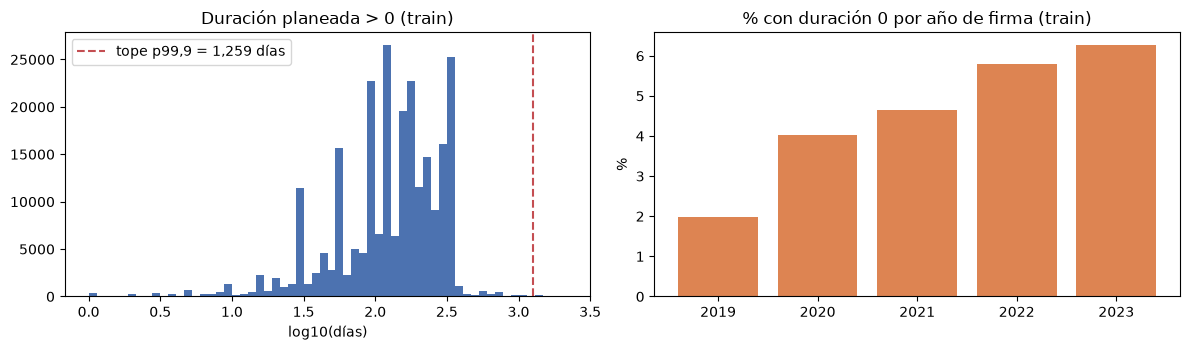

In [4]:
d = X.loc[idx_tr, "p_dur_dias"]
print(f"Máximo en toda la base: {X['p_dur_dias'].max():,.0f} días")
print(f"Duración 0 en el train: {(d == 0).mean():.1%}  |  faltante: {d.isna().mean():.2%}")
print("Cuantiles de las duraciones > 0 en el train:", d[d > 0].quantile([.5, .9, .99, .999]).round(0).to_dict())
y_tr = base.loc[idx_tr, "y"]
print(f"Tasa de y: duración 0 = {y_tr[d == 0].mean():.3f} | duración > 0 = {y_tr[d > 0].mean():.3f}")

prep = P.construir_preprocesador("arbol").fit(Xtr, ytr)
tope = prep.named_transformers_["dur"].tope_[0]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(np.log10(d[d > 0]), bins=60, color="#4C72B0")
ax[0].axvline(np.log10(tope), color="#C44E52", ls="--", label=f"tope p99,9 = {tope:,.0f} días")
ax[0].set_xlabel("log10(días)"); ax[0].set_title("Duración planeada > 0 (train)"); ax[0].legend()
t = base.loc[idx_tr].assign(cero=d.eq(0)).groupby("anio_firma")["cero"].mean() * 100
ax[1].bar(t.index, t.values, color="#DD8452"); ax[1].set_title("% con duración 0 por año de firma (train)"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

**Decisión:** `p_dur_dias = 0` pasa a faltante con el indicador `p_dur_dias_cero`, y las duraciones se recortan por arriba al percentil 99,9 del train.
- **Alternativas:** borrar los contratos; recortar a un tope fijo de 3.650 días (la sugerencia inicial del EDA, 3.3.2.2); dejar los valores crudos.
- **Por qué:** una duración 0 no es un contrato instantáneo, es un dato sin diligenciar, y se comporta distinto (en el train, tasa de y 0,253 frente a 0,291), así que el indicador le permite al modelo usar esa señal. El tope sale del train, así que es parte del `Pipeline` y no un número escrito a mano. Para el HGB el recorte casi no cambia nada (los árboles cortan por rangos), pero en kNN y SVM un valor de 4.078 millones dominaría la distancia.
- **Evidencia:** gráfica y cifras de arriba.

## Codificación y escalado: un preprocesador por familia de modelo

| | Árboles (HGB, árbol, RF) | Distancia (kNN, SVM) |
|---|---|---|
| Categóricas | códigos ordinales (200 más frecuentes; nuevas y faltantes → `NaN`) | one-hot; categorías con < 1 % del train agrupadas |
| `nit_entidad` (2.330 entidades) | `TargetEncoder` con validación cruzada interna | igual |
| Conteos de competencia | crudos | `log1p` + `RobustScaler` |
| Mes y día de la semana | crudos | seno y coseno |
| Otras numéricas | crudas | mediana + indicador + `RobustScaler` |
| Redundantes (Spearman ≥ 0,995) | se mantienen | se deja una de cada par |
| `p_proveedores_que_manifestaron` | se quita (constante 0) | se quita |

In [5]:
for fam in ("arbol", "distancia"):
    ct = P.construir_preprocesador(fam).fit(Xtr, ytr)
    Z = ct.transform(X.loc[idx_te])
    print(f"{fam:10s}: {Z.shape[1]:3d} columnas de salida | columnas con NaN en 2024: {int(Z.isna().any().sum())}")
te = prep.named_transformers_["entidad"]
print(f"TargetEncoder: {len(te.categories_[0]):,} entidades; las no vistas reciben la media del train ({te.target_mean_:.3f})")

arbol     :  39 columnas de salida | columnas con NaN en 2024: 18


distancia : 158 columnas de salida | columnas con NaN en 2024: 0
TargetEncoder: 2,330 entidades; las no vistas reciben la media del train (0.289)


**Decisión: `TargetEncoder` para la entidad.**
- **Alternativas:** one-hot (2.330 columnas, la mayoría con muy pocos contratos); códigos ordinales (un número arbitrario por entidad).
- **Por qué:** la entidad es la señal más fuerte (H6), pero con muchas categorías. El `TargetEncoder` la resume en la tasa histórica suavizada de la entidad. Dentro del train usa validación cruzada (cada fila se codifica con los otros pliegues), así que el modelo no ve su propia etiqueta; en la búsqueda se vuelve a ajustar en cada fold temporal.
- **Evidencia:** en el SHAP global de la sección 3.6, `nit_entidad` es la feature más importante.

**Decisión: códigos ordinales y no categorías nativas en el HGB.**
- **Alternativas:** categorías nativas del HGB.
- **Por qué:** con categorías nativas `TreeExplainer` da atribuciones incorrectas sin avisar (`docs/PLAN.md`, sección 0, punto 7) y la app se niega a explicar. Con los mismos hiperparámetros las nativas solo ganan +0,003 de PR-AUC en los folds temporales (sección 3.5), menos que la variación entre folds.
- **Evidencia:** sección 3.5, tabla "nativas frente a códigos".

**Decisión: one-hot + escalado robusto solo para kNN y SVM.**
- **Por qué:** los árboles no dependen de la escala ni de transformaciones monótonas; las distancias sí. `RobustScaler` usa mediana y rango intercuartílico, así que los atípicos que quedan no dominan. Los meses son cíclicos: diciembre debe quedar cerca de enero.

## Sin fuga en el preprocesamiento

Lo aprendido (tope de duración, medianas, categorías, codificación de la entidad) depende solo de las filas con las que se ajusta. La prueba `tests/test_preprocesamiento.py::test_ajuste_solo_con_train` lo verifica: cambiar el test no mueve nada de lo aprendido.

In [6]:
otro = X.copy()
otro.loc[idx_te, "p_dur_dias"] = 99999.0
a = P.construir_preprocesador("arbol").fit(X.loc[idx_tr], ytr).named_transformers_["dur"].tope_
b = P.construir_preprocesador("arbol").fit(otro.loc[idx_tr], ytr).named_transformers_["dur"].tope_
print("El tope aprendido no cambia al alterar el test:", np.array_equal(a, b))

El tope aprendido no cambia al alterar el test: True


# 3.3 Análisis exploratorio (EDA)

**Base v1_A** (corte 26-oct-2026): 452.494 contratos firmados entre 2019 y 2025, muestra del 10 % por dígito 4 del `id_contrato`, autoponderada. Fuente: SECOP II, datos.gov.co (`jbjy-vk9h`, `p6dx-8zbt`), licencia CC BY-SA 4.0.

**Etiqueta v1:** `y` es la etiqueta de ampliación del plazo (tasa 27,6 %); `y_dias` y `y_modif` se usan solo para comparar. Cada sección que depende de `y` cierra con su interpretación (Decisión / Alternativas / Por qué / Evidencia).

**Tablas.** Cada tabla lleva el ID con que la citan las interpretaciones (por ejemplo, «Tabla 6.1.1»). Las que terminan en `.b` repiten la tabla sobre el train 2019-2023, que es con lo que se entrena el modelo. El mismo conjunto de tablas, con el código que las genera, está en `docs/eda_tablas.md`.

**Alcance:** 3.3.2 calidad, 3.3.3 distribuciones, deriva y correlación, 3.3.4 duración y madurez, 3.3.5 etiqueta, 3.3.6 H1-H7, 3.3.7 privacidad y tipo de documento, 3.3.8 fuga descriptiva y 3.3.9 decisiones. 3.3.4.3, 3.3.5, 3.3.6, 3.3.7.2 y 3.3.8 traen su interpretación después de la tabla o la gráfica.

**«Train» en el EDA.** Aquí «train 2019-2023» son los 261.831 contratos firmados en esos años, incluidos los 582 aún no maduros. El modelo (3.2 en adelante) se entrena solo con los maduros: 261.249.

In [7]:
from src.base import validar_esquema

# Estilo del EDA; al final de 3.3 se restauran los valores de antes para no cambiar las demás secciones.
CLAVES_RC = ("figure.figsize", "axes.grid", "grid.alpha", "axes.spines.top", "axes.spines.right",
             "font.size", "axes.titlesize", "axes.labelsize", "legend.fontsize")
RC_PREVIO = {k: plt.rcParams[k] for k in CLAVES_RC}
eda.config_graficas()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


def mostrar_tabla(id_tabla, titulo, tabla):
    """Muestra una tabla con el ID con que la citan las interpretaciones."""
    display(Markdown(f"**Tabla {id_tabla}.** {titulo}"))
    display(tabla)


meta_base = json.loads(BASE_V1.with_suffix(".meta.json").read_text(encoding="utf-8"))
validar_esquema(base)

print("base:", base.shape, "| features:", X.shape)
print("version:", meta_base["version"], "| corte:", meta_base["fechas_de_corte"]["fecha_de_corte_de_la_censura"])
print("anios:", sorted(base["anio_firma"].unique().tolist()))
print("entidades:", base["nit_entidad"].nunique(), "| maduros:", round(100 * base["eval_madura"].mean(), 1), "%")

base: (452494, 50) | features: (452494, 39)
version: v1 | corte: 2026-10-26
anios: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
entidades: 3034 | maduros: 99.2 %


## 3.3.1 Carga y mapa de hipótesis

La base cumple el esquema de la base procesada (`docs/PLAN.md`, 2a) y `construir_features` devuelve las 39 features. El EDA separa lo que no depende de la etiqueta (calidad, distribución, deriva, duración, privacidad) de lo que sí (H1–H7 y etiqueta).

| Hipótesis | Señal al firmar | Feature(s) | Sección |
|---|---|---|---|
| H1. Procesos apresurados | Días entre publicación y firma | `dias_publicacion_a_firma` | H1 en 3.3.6 |
| H2. Poca competencia | Respuestas, oferentes, invitados | `p_respuestas_al_procedimiento`, `p_conteo_de_respuestas_a_ofertas`, `p_proveedores_invitados` | H2 en 3.3.6 |
| H3. Modalidad | Directa frente a competitivas | `modalidad_de_contratacion`, `justificacion_modalidad_de` | H3 en 3.3.6 |
| H4. Anualidad | Firma en el último trimestre | `mes_firma`, `firma_ultimo_trimestre`, `fin_planeado_cruza_anio` | H4 en 3.3.6 |
| H5. Plazos subestimados | Duración planeada | `p_dur_dias`, `p_unidad_de_duracion` | H5 en 3.3.6 |
| H6. Hábitos de la entidad | Tasa histórica de la entidad | `nit_entidad` (TargetEncoder) | H6 en 3.3.6 |
| H7. Tipo de objeto | UNSPSC y tipo de contrato | `unspsc_segmento`, `unspsc_familia`, `tipo_de_contrato`, `len_objeto` | H7 en 3.3.6 |

`y` no se usa en 3.3.2 a 3.3.4; solo en 3.3.4.3, 3.3.5, 3.3.6 y 3.3.7.2, que quedan marcadas.

## 3.3.2 Calidad de datos

No depende de la etiqueta.

### 3.3.2.1 Faltantes

**Qué se observa.** Los faltantes son bajos y vienen en bloques: 349 contratos (0,08 %) no tienen fila de Procesos (todas las `p_*` faltan), `fecha_de_inicio_del_contrato` falta en 4.059 (0,90 %), la duración planeada en 799 (0,18 %) y `unspsc_familia`/`unspsc_segmento` en 3.806 (0,84 %), todos sin UNSPSC. `y_modif` no falta (0 %) porque la v1 trae Modificaciones; es esperado.

**Decisión.** Imputar dentro del `Pipeline`, con la mediana/moda aprendida solo en train, y usar indicadores de bloque (`sin_proceso`, `sin_inicio`, `sin_duracion`). No borrar filas: los faltantes son pocos y borrarlas sesgaría la muestra.

**En v1.** Solo en la familia de distancia (kNN y SVM) se imputa con la mediana del train y se agrega el indicador `<feature>_faltante`; el HGB deja los `NaN` y los maneja de forma nativa (3.2).

Columnas de la base con faltantes:


,columna,tipo,n,faltantes,pct_faltantes,n_unicos
0,N_mes,float64,452494,452494,100.00,0
1,fecha_de_inicio_del_contrato,datetime64[us],452494,4059,0.90,2803
2,eval_dur_planeada_dias,float32,452494,799,0.18,935
3,eval_fin_planeado,datetime64[us],452494,799,0.18,3976
4,p_fecha_de_publicacion_del,datetime64[us],452494,380,0.08,2708
5,p_conteo_de_respuestas_a_ofertas,float64,452494,349,0.08,43
6,p_duracion,float64,452494,349,0.08,847
7,p_numero_de_lotes,float64,452494,349,0.08,136
8,p_precio_base,float64,452494,349,0.08,146892
9,p_proveedores_con_invitacion,float64,452494,349,0.08,162


Features con faltantes:


,columna,tipo,n,faltantes,pct_faltantes,n_unicos
0,dias_firma_a_inicio,float64,452494,4059,0.90,634
1,unspsc_familia,object,452494,3806,0.84,376
2,unspsc_segmento,object,452494,3806,0.84,56
3,fin_planeado_cruza_anio,float64,452494,799,0.18,2
4,p_dur_dias,float64,452494,799,0.18,935
5,dias_publicacion_a_firma,float64,452494,380,0.08,569
6,log_precio_base,float64,452494,349,0.08,146885
7,p_conteo_de_respuestas_a_ofertas,float64,452494,349,0.08,43
8,p_numero_de_lotes,float64,452494,349,0.08,136
9,p_proveedores_con_invitacion,float64,452494,349,0.08,162


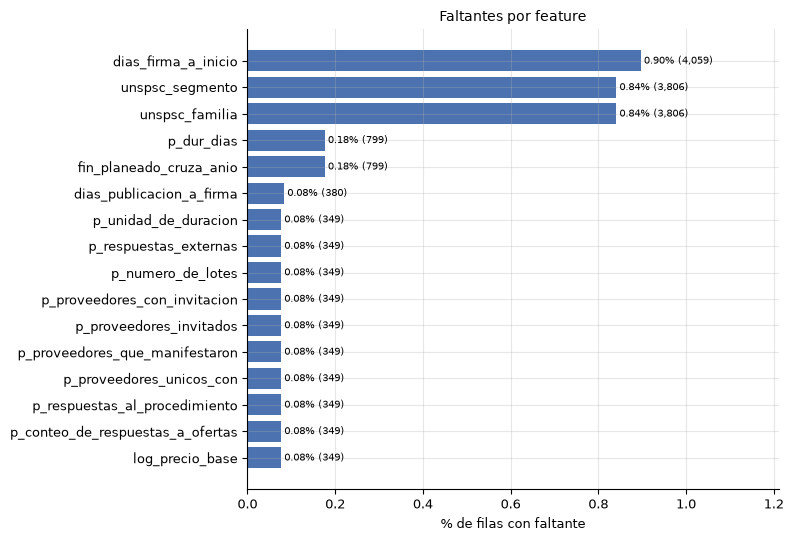

In [8]:
cols_base = [c for c in base.columns if c not in ["id_contrato", "proceso_de_compra"]]
faltantes_base = eda.resumen_faltantes(base, cols_base)
faltantes_x = eda.resumen_faltantes(X, F.FEATURES)

print("Columnas de la base con faltantes:")
display(faltantes_base[faltantes_base["faltantes"] > 0])
print("Features con faltantes:")
display(faltantes_x[faltantes_x["faltantes"] > 0])
eda.graficar_faltantes(faltantes_x, titulo="Faltantes por feature")
plt.show()

### 3.3.2.2 Valores imposibles

**Qué se observa.** No hay `id_contrato` duplicados, fechas basura, PII ni columnas de fuga. Los problemas están en duración y montos: 24.566 contratos (5,43 %) tienen duración planeada ≤ 0, 125 (0,03 %) pasan de 3.650 días y el máximo es 4.078,9 millones de días; 10 precios base son negativos, 3.497 son cero y el máximo es 2,5 billones. Además, 1.291 contratos (0,29 %) tienen fin planeado anterior a la firma: en todos el inicio es anterior a la firma y la duración no alcanza a cubrir ese retroceso (289 tienen duración ≤ 0).

**Decisión.** Tratar duración ≤ 0 como faltante y recortar a [1, 3.650] días; no eliminar contratos. `construir_features` ya recorta `dias_firma_a_inicio` y `dias_publicacion_a_firma`, pero no `p_dur_dias`. Los precios negativos quedan en 0 después de `clip(lower=0)` en `log_precio_base`, así que no se pueden separar de los ceros reales; en v1 no se crea ningún indicador y la limitación queda documentada.

**En v1.** La duración ≤ 0 pasa a `NaN` con el indicador `p_dur_dias_cero` y se recorta por arriba al percentil 99,9 del train (1.259 días), no a 3.650 (3.2). El precio negativo se recorta a 0 con `clip(lower=0)`, sin indicador.

In [9]:
imposibles = eda.revisar_valores_imposibles(base)
display(imposibles[imposibles["n"] > 0].reset_index(drop=True))
print("Los chequeos que no aparecen dieron 0.")

,chequeo,n,pct,detalle
0,fecha_de_inicio nula,4059,0.90,
1,inicio mas de 365 dias antes de la firma,256,0.06,
2,inicio mas de 365 dias despues de la firma,102,0.02,
3,p_fecha_de_publicacion nula,380,0.08,
4,p_duracion nula,349,0.08,
5,p_duracion <= 0,24586,5.43,
6,duracion planeada nula,799,0.18,
7,duracion planeada <= 0,24566,5.43,
8,duracion planeada > 3650 dias,125,0.03,
9,p_precio_base nulo,349,0.08,


Los chequeos que no aparecen dieron 0.


### 3.3.2.3 Atípicos

**Qué se observa.** Las colas largas están en duración, precio, pago adelantado y competencia. La duración planeada (`eval_dur_planeada_dias`) tiene 5,44 % en cero (sobre los contratos con duración) y 0,98 % fuera de 1,5 IQR, con máximo de 4.078,9 millones de días; `p_duracion` tiene 8,04 % fuera de 1,5 IQR; `p_precio_base` tiene 13,75 % fuera de 1,5 IQR y máximo de 2,5 billones; `p_proveedores_invitados` llega a 7.229 y `p_respuestas_al_procedimiento` a 254. `len_objeto` está truncado en 500 caracteres.

**Decisión.** No eliminar outliers: son pocos y pueden ser señal. Para kNN/SVM, `log1p` + `RobustScaler`; para HGB, dejar los valores crudos y usar el recorte de 3.3.2.2. Recortar `p_proveedores_invitados` en el percentil 99,9 solo para modelos de distancia.

**En v1.** Los árboles reciben los valores crudos, salvo `p_dur_dias`, que se recorta al percentil 99,9 del train (3.3.2.2). En kNN y SVM los conteos de competencia pasan por `log1p` y `RobustScaler`; el recorte de `p_proveedores_invitados` al percentil 99,9 no se aplicó (3.2).

,columna,n,n_cero,pct_cero,n_neg,min,p1,p50,p99,max,n_iqr_alto,pct_iqr_alto
0,p_precio_base,452145,3497,0.77,10,"-34,693,400,216.00","810,960.00","19,600,000.00","3,529,646,400.00","2,500,616,113,000.00",62166,13.75
1,p_respuestas_al_procedimiento,452145,408894,90.43,0,0.00,0.00,0.00,9.00,254.00,43251,9.57
2,p_numero_de_lotes,452145,414147,91.60,0,0.00,0.00,0.00,37.00,216.00,37998,8.40
3,p_duracion,452145,24586,5.44,0,0.00,0.00,15.00,350.00,"135,963,450.00",36371,8.04
4,p_proveedores_invitados,452145,442688,97.91,0,0.00,0.00,0.00,4.00,"7,229.00",9457,2.09
5,eval_dur_planeada_dias,451695,24566,5.44,0,0.00,0.00,120.00,420.00,"4,078,903,552.00",4427,0.98
6,valor_de_pago_adelantado,452494,451976,99.89,0,0.00,0.00,0.00,0.00,"25,178,078,596.00",518,0.11
7,len_objeto,452494,0,0.00,0,1.00,40.00,234.00,500.00,500.00,0,0.00


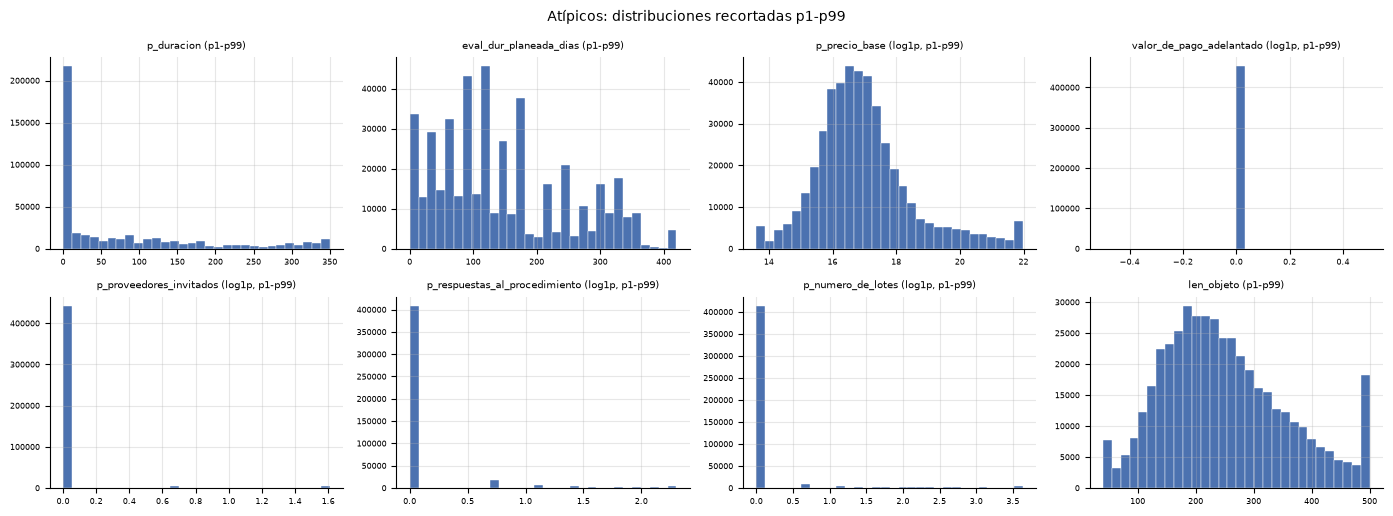

In [10]:
base_atipicos = base.assign(len_objeto=X["len_objeto"])
cols_atipicos = ["p_duracion", "eval_dur_planeada_dias", "p_precio_base", "valor_de_pago_adelantado",
                 "p_proveedores_invitados", "p_respuestas_al_procedimiento", "p_numero_de_lotes", "len_objeto"]
atipicos = eda.resumen_atipicos(base_atipicos, cols_atipicos)
display(atipicos.round(3))
eda.graficar_histogramas(
    base_atipicos, cols_atipicos, ncols=4,
    escala_log=("p_precio_base", "valor_de_pago_adelantado", "p_proveedores_invitados",
                "p_respuestas_al_procedimiento", "p_numero_de_lotes"),
    titulo="Atípicos: distribuciones recortadas p1-p99",
)
plt.show()

### 3.3.2.4 Cardinalidad de las categóricas

**Qué se observa.** `nit_entidad` (3.034), `ciudad` (735), `unspsc_familia` (376) y `unspsc_segmento` (56) concentran la cardinalidad alta. En el resto, las categorías raras (<1 %) son pocas: `justificacion_modalidad_de` 36 categorías/5,76 % de filas, `departamento` 13/5,18 %, `sector` 8/2,73 %, `tipo_de_contrato` 19/2,64 %, `modalidad_de_contratacion` 10/2,46 %, `tipodocproveedor` 8/0,53 %. `ciudad` tiene 718 categorías raras y 26,26 % de las filas; `nit_entidad` tiene 3.024 categorías con <1 % y 76,59 % de las filas, pero es la señal de H6 y va con TargetEncoder, no con one-hot.

**Decisión.** Para one-hot/kNN/SVM: agrupar categorías <1 % en `OTROS` y mantener `No Definido` como categoría o faltante explícito. Para HGB: categorías nativas con tope (200) o códigos ordinales; `nit_entidad` solo con `TargetEncoder` dentro del `Pipeline`.

**En v1.** `nit_entidad` va con `TargetEncoder`; las demás categóricas, con `OrdinalEncoder` (las 200 más frecuentes) en los árboles. En la familia de distancia las categorías con menos de 1 % del train se agrupan (3.2).

,columna,n_unicos,nulos,top,top_pct,n_categorias_lt_1pct,pct_filas_lt_1pct
0,nit_entidad,3034,0,899999034,5.62,3024,76.59
1,ciudad,735,0,No Definido,21.37,718,26.26
2,unspsc_familia,376,3806,8011,63.52,364,14.94
3,unspsc_segmento,56,3806,80,72.00,50,10.90
4,justificacion_modalidad_de,41,0,Servicios profesionales y apoyo a la gestión,73.36,36,5.76
5,departamento,34,0,Distrito Capital de Bogotá,33.50,13,5.18
6,sector,26,0,Servicio Público,24.91,8,2.73
7,tipo_de_contrato,24,0,Prestación de servicios,85.75,19,2.64
8,modalidad_de_contratacion,15,0,Contratación directa,76.75,10,2.46
9,tipodocproveedor,10,0,Cédula de Ciudadanía,84.25,8,0.53


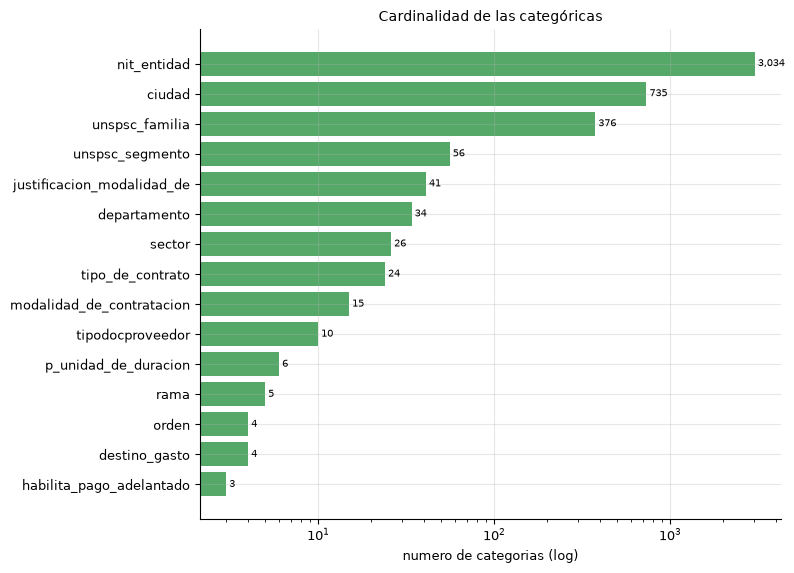

In [11]:
card = eda.cardinalidad_categoricas(X, F.FEATURES_CAT)
display(card.round(2))
eda.graficar_cardinalidad(card, top=15, titulo="Cardinalidad de las categóricas")
plt.show()

## 3.3.3 Distribución de features y deriva por año

No depende de la etiqueta. Se revisan las 18 numéricas y las 21 categóricas, y se comparan 2019–2025 para detectar deriva.

### 3.3.3.1 Distribución de las numéricas

**Qué se observa.** La mayoría son cero-infladas: `log_pago_adelantado` 99,89 % en cero, `p_proveedores_invitados` 97,91 %, `p_numero_de_lotes` 91,60 %, `p_respuestas_al_procedimiento` 90,43 %. `p_dur_dias` tiene mediana 120 días y p95 337; `log_precio_base` mediana 16,79 (unos 19,6 millones) y p99 21,98 (unos 3,5 mil millones). El calendario está repartido; `firma_ultimo_trimestre` es 20 %.

**Decisión.** Para kNN/SVM: usar tal cual `log_precio_base` y `log_pago_adelantado` (ya vienen en `log1p`), aplicar `log1p` a los conteos crudos y `RobustScaler` después; para HGB: valores crudos y flags de cero. No imputar los ceros de competencia: son "sin respuesta", no faltantes.

,columna,n,media,std,min,p1,p5,p50,p95,p99,max,pct_cero
0,log_pago_adelantado,452494,0.02,0.62,0.00,0.00,0.00,0.00,0.00,0.00,23.95,99.89
1,len_objeto,452494,248.78,106.88,1.00,40.00,99.00,234.00,466.00,500.00,500.00,0.00
2,dias_firma_a_inicio,448435,2.88,17.27,-365.00,-8.00,0.00,1.00,13.00,37.00,365.00,32.91
3,mes_firma,452494,5.55,3.68,1.00,1.00,1.00,5.00,12.00,12.00,12.00,0.00
4,dia_semana,452494,2.29,1.53,0.00,0.00,0.00,2.00,5.00,6.00,6.00,15.56
5,firma_ultimo_trimestre,452494,0.20,0.40,0.00,0.00,0.00,0.00,1.00,1.00,1.00,80.13
6,fin_planeado_cruza_anio,451695,0.24,0.43,0.00,0.00,0.00,0.00,1.00,1.00,1.00,76.26
7,log_precio_base,452145,16.89,2.16,0.00,13.61,14.91,16.79,20.22,21.98,28.55,0.78
8,p_dur_dias,451695,"12,066.52","6,298,973.53",0.00,0.00,0.00,120.00,337.00,420.00,"4,078,903,500.00",5.44
9,dias_publicacion_a_firma,452114,5.88,26.67,0.00,0.00,0.00,1.00,23.00,70.00,"1,000.00",36.63


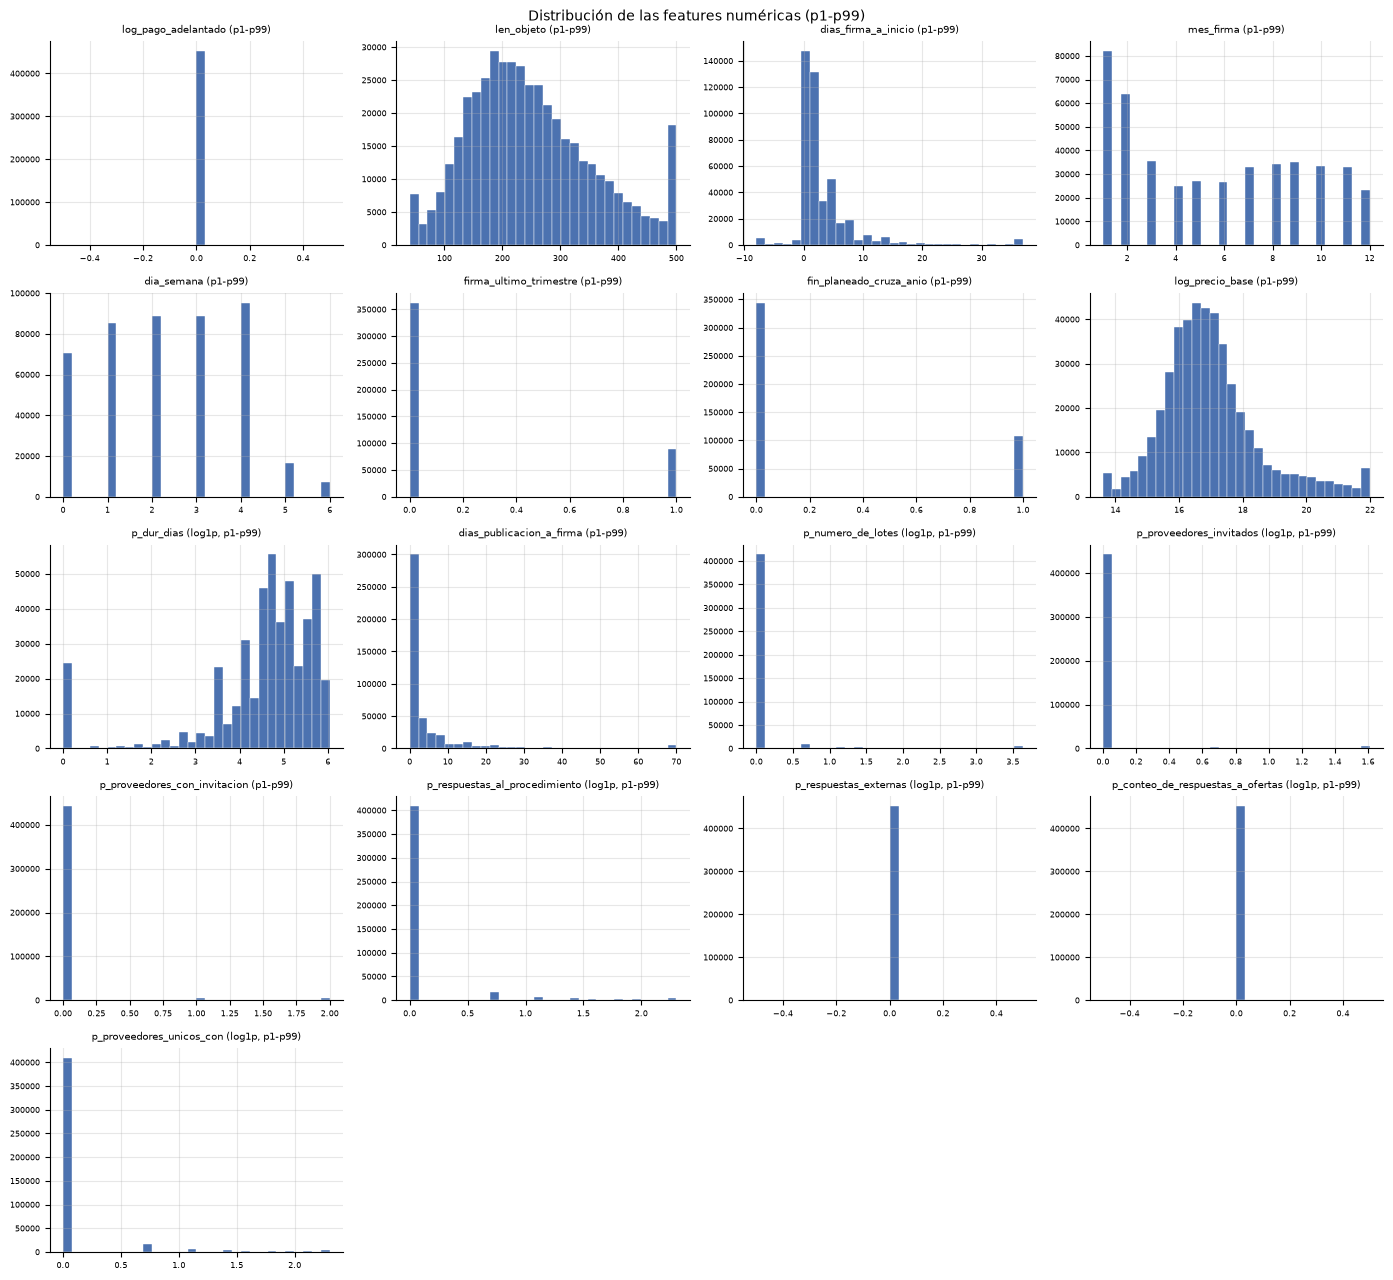

In [12]:
num_plot = [c for c in F.FEATURES_NUM if X[c].nunique() > 1]
display(eda.distribucion_numericas(X, F.FEATURES_NUM).round(2))
eda.graficar_histogramas(
    X, num_plot, ncols=4,
    escala_log=("p_dur_dias", "p_numero_de_lotes", "p_proveedores_invitados",
                "p_respuestas_al_procedimiento", "p_respuestas_externas",
                "p_conteo_de_respuestas_a_ofertas", "p_proveedores_unicos_con"),
    titulo="Distribución de las features numéricas (p1-p99)",
)
plt.show()

### 3.3.3.2 Composición de las categóricas

**Qué se observa.** El contrato típico es prestación de servicios (85,75 %), contratación directa (76,75 %), proveedor con cédula (84,25 %), en Bogotá/Valle/Antioquia. `No Definido` aparece en `ciudad` 21,37 %, `departamento` 1,79 %, `destino_gasto` 0,28 % y `tipodocproveedor` 0,16 %. `documentos_tipo` usa "No" y "No definido" como categorías distintas; `destino_gasto` usa "No Definido" y "No aplica".

**Decisión.** Normalizar texto (minúsculas, sin espacios) y unificar "No definido"/"No Definido" en una sola categoría; `No Definido` en `ciudad` se trata como categoría (no como faltante) porque puede informar la calidad del registro. Las categorías raras se agrupan como en 3.3.2.4.

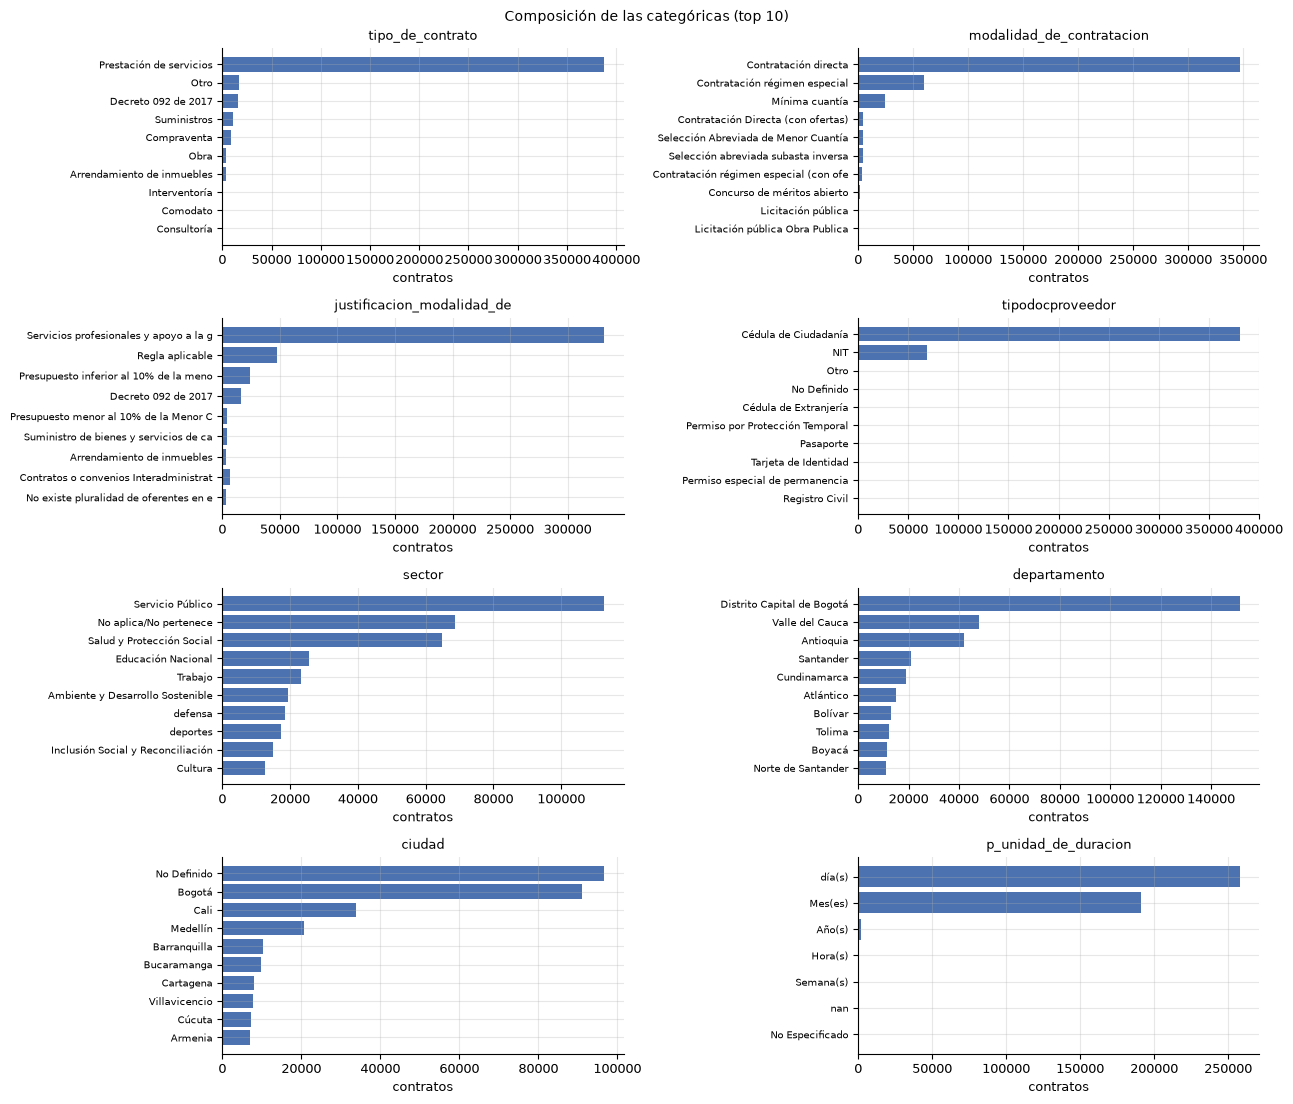

In [13]:
cats_plot = ["tipo_de_contrato", "modalidad_de_contratacion", "justificacion_modalidad_de",
             "tipodocproveedor", "sector", "departamento", "ciudad", "p_unidad_de_duracion"]
eda.graficar_barras_categoricas(X, cats_plot, top=10, ncols=2,
                                titulo="Composición de las categóricas (top 10)")
plt.show()

### 3.3.3.3 Deriva numérica por año

**Qué se observa.** 2019 es atípico: duración mediana de 180 días y precio base mediano de 17,37 (en logaritmo), frente a 116–150 días y 16,71–16,87 desde 2020. La competencia tiene ceros altos en todos los años (entre 75,8 % y 99,9 % según la variable y el año). El cambio más fuerte está en las categóricas (3.3.3.4), no en las numéricas.

**Decisión.** No usar `anio_firma` como feature. Ajustar imputación/escalado solo con train y validar temporalmente. Excluir 2019 del train como prueba de sensibilidad queda como mejora posible [NO EVALUADO]; el train se mantiene en 2019–2023 por diseño.

,mediana_inicio,mediana_fin,cambio_abs,z_max,cambio_2023_2024
dias_publicacion_a_firma,4.00,1.00,-3.00,2.45,0.00
log_precio_base,17.37,16.87,-0.50,2.36,-0.01
mes_firma,2.00,5.00,3.00,2.16,1.00
p_dur_dias,180.00,120.00,-60.00,2.06,-4.00
dias_firma_a_inicio,0.00,1.00,1.00,1.87,0.00
len_objeto,227.00,236.00,9.00,1.79,3.00
log_pago_adelantado,0.00,0.00,0.00,0.00,0.00
fin_planeado_cruza_anio,0.00,0.00,0.00,0.00,0.00
dia_semana,2.00,2.00,0.00,0.00,0.00
firma_ultimo_trimestre,0.00,0.00,0.00,0.00,0.00


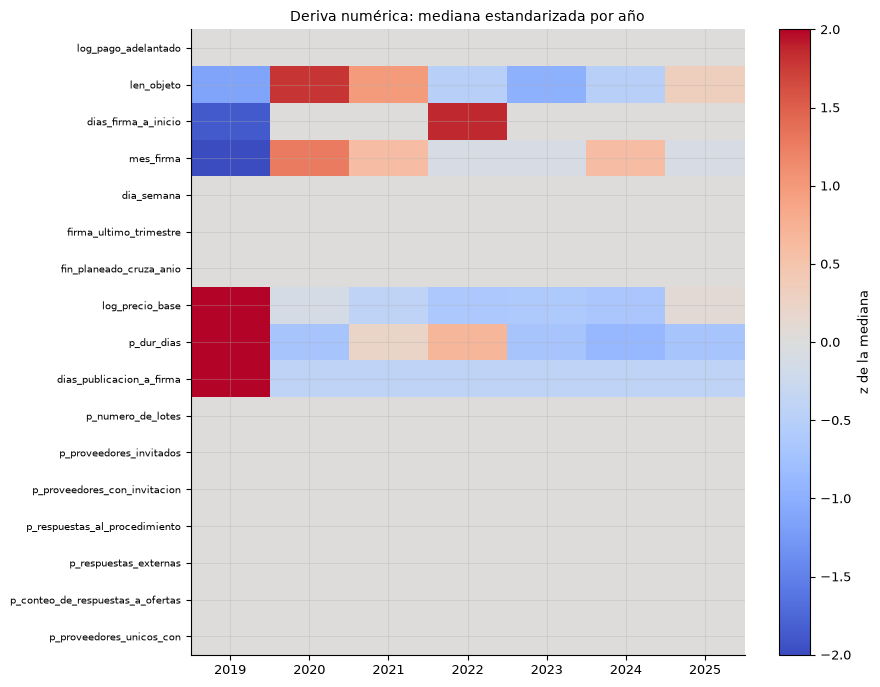

In [14]:
X_anio = X.assign(anio_firma=base["anio_firma"])
medianas, z, cambios = eda.deriva_numericas(X_anio, num_plot)
display(cambios.round(2))
eda.graficar_deriva_numericas(z, titulo="Deriva numérica: mediana estandarizada por año")
plt.show()

### 3.3.3.4 Deriva categórica por año

**Qué se observa.** Entre 2019 y 2025: cédula 75,55 %→84,85 %, NIT 23,61 %→14,68 %, contratación directa 59,57 %→75,59 %, prestación de servicios 79,59 %→85,60 %, UNSPSC 80 62,57 %→72,29 % (sobre los contratos con UNSPSC) y mínima cuantía 15,08 %→4,83 %. El salto ocurre entre 2019 y 2020 (contratación directa +17,0 puntos, mínima cuantía −8,6); 2021 completa el ajuste (+3,8 puntos en contratación directa) y desde 2022 ninguna de estas categorías se mueve más de 2,5 puntos de un año a otro.

**Decisión.** Misma que 3.3.3.3: no usar el año como feature; el preprocesamiento se ajusta con train. Reportar la deriva en el monitoreo (3.9) y no comparar composiciones de 2019 con 2024 sin tenerla en cuenta.

,columna,top_inicio,pct_inicio,top_fin,pct_fin,cambio_max_pp,categoria_cambio
0,modalidad_de_contratacion,Contratación directa,59.57,Contratación directa,75.59,16.02,Contratación directa
1,unspsc_segmento,80,62.57,80,72.29,9.72,80
2,tipodocproveedor,Cédula de Ciudadanía,75.55,Cédula de Ciudadanía,84.85,9.29,Cédula de Ciudadanía
3,tipo_de_contrato,Prestación de servicios,79.59,Prestación de servicios,85.60,6.02,Prestación de servicios


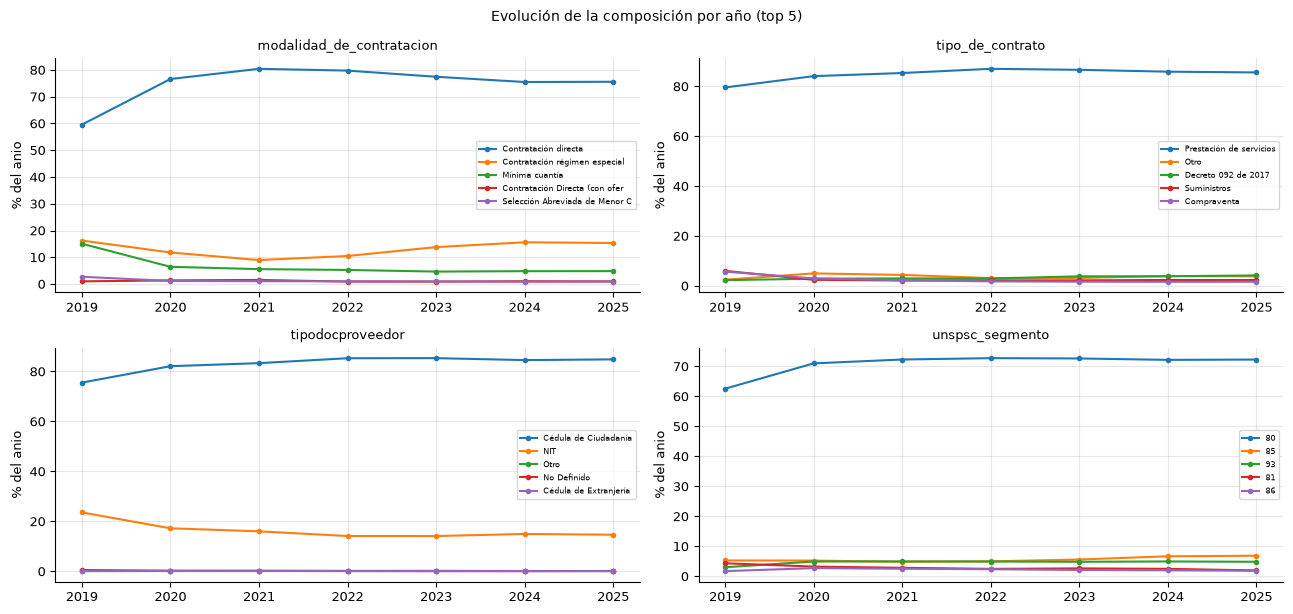

In [15]:
cats_deriva = ["modalidad_de_contratacion", "tipo_de_contrato", "tipodocproveedor", "unspsc_segmento"]
display(eda.resumen_deriva_categoricas(X_anio, cats_deriva).round(2))
eda.graficar_evolucion_categorias(X_anio, cats_deriva, top=5, ncols=2,
                                  titulo="Evolución de la composición por año (top 5)")
plt.show()

### 3.3.3.5 Matriz de correlación de las numéricas

**Qué se observa.** Se excluye `p_proveedores_que_manifestaron` porque es constante 0. Con Spearman, hay dos pares casi duplicados: `p_proveedores_invitados` y `p_proveedores_con_invitacion` (r = 0,994; el segundo nunca es mayor y es igual en 99,74 % de las filas con proceso) y `p_respuestas_al_procedimiento` y `p_proveedores_unicos_con` (r = 0,992; iguales en 99,56 %). `mes_firma` y `firma_ultimo_trimestre` correlacionan 0,695 (Spearman) y 0,722 (Pearson) porque el flag es una transformación del mes. Con Pearson, `dias_firma_a_inicio` y `dias_publicacion_a_firma` dan −0,458, pero con Spearman solo 0,066: la correlación la producen los valores extremos, no el grueso de los datos. En Pearson, `p_respuestas_al_procedimiento` y `p_proveedores_unicos_con` siguen en 0,983, mientras que `p_proveedores_invitados` y `p_proveedores_con_invitacion` caen a 0,055 porque casi siempre valen 0 y su relación es de orden, no lineal.

**Qué implica para kNN y SVM.** La colinealidad no rompe el modelo, pero duplica el peso de la misma señal en la distancia y en el kernel. Para kNN/SVM: dejar un representante de cada par redundante (`p_proveedores_invitados` y `p_respuestas_al_procedimiento`), y para el calendario quedarse con `firma_ultimo_trimestre` o codificar el mes de forma cíclica. Para HGB, que parte el espacio por variable, la colinealidad importa menos: se pueden mantener las dos y la ablación de 3.6 decide.

**Decisión.** Para kNN/SVM: eliminar `p_proveedores_que_manifestaron` (constante 0), `p_proveedores_con_invitacion` y `p_proveedores_unicos_con`, y no usar `mes_firma` junto con `firma_ultimo_trimestre`. Para HGB: mantener todas y medir en 3.6. Evidencia: correlaciones y duplicación de filas.

Spearman |r| >= 0,7:


,feature_1,feature_2,r,abs_r
0,p_proveedores_invitados,p_proveedores_con_invitacion,0.994,0.994
1,p_respuestas_al_procedimiento,p_proveedores_unicos_con,0.992,0.992


Pearson |r| >= 0,7:


,feature_1,feature_2,r,abs_r
0,p_respuestas_al_procedimiento,p_proveedores_unicos_con,0.983,0.983
1,mes_firma,firma_ultimo_trimestre,0.722,0.722


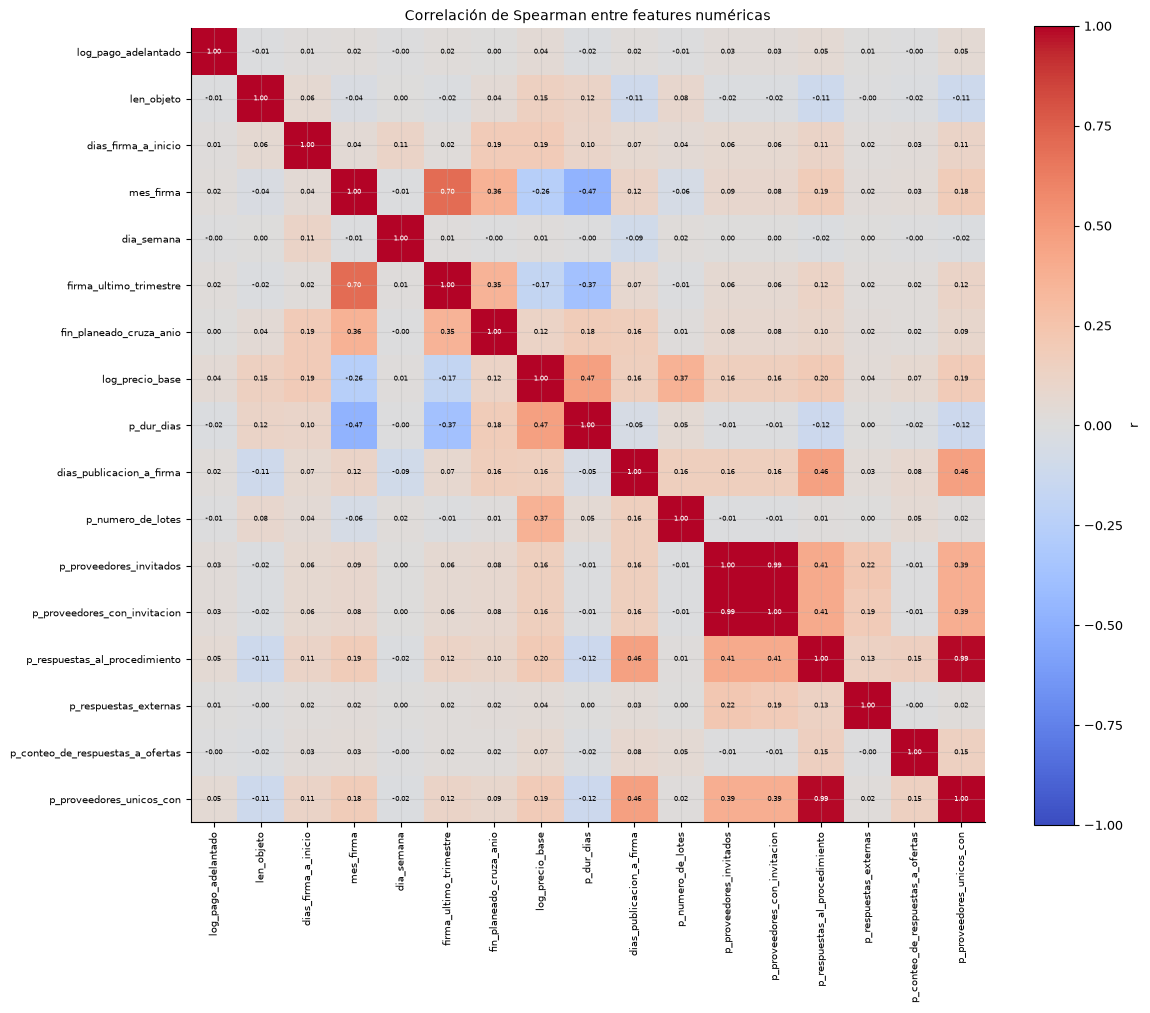

In [16]:
num_corr = [c for c in F.FEATURES_NUM if X[c].nunique() > 1]
corr_s = eda.matriz_correlacion(X, num_corr, metodo="spearman")
pares_s = eda.pares_correlacionados(corr_s, umbral=0.7)
corr_p = X[num_corr].corr(method="pearson")
pares_p = eda.pares_correlacionados(corr_p, umbral=0.7)

print("Spearman |r| >= 0,7:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pares_s)
print("Pearson |r| >= 0,7:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pares_p)
eda.graficar_matriz_correlacion(corr_s, titulo="Correlación de Spearman entre features numéricas")
plt.show()

## 3.3.4 Duración planeada y madurez (censura)

La madurez es mecánica: `eval_madura = fin planeado + 60 días <= fecha de corte`, con `fin planeado = inicio (o firma) + duración del proceso`. No depende de la etiqueta; la relación entre madurez y `y` se ve en 3.3.4.3.

**Qué se observa.** La duración mediana es 116–180 días; el 5,43 % tiene duración ≤ 0 y el 0,18 % no tiene duración. La fracción madura va de 99,99 % (2019) a 97,64 % (2025); en total 99,2 %. Los 3.455 inmaduros son 11 sin duración, 867 con duración 0 y 2.577 con fin planeado + 60 días después del corte.

**Decisión.** Entrenar y evaluar solo con `eval_madura = True`; imputar `p_dur_dias` para las features, pero no usar `eval_*` como features. Reportar métricas por tramo de duración (≤ 3, 3–6, 6–12, > 12 meses) en la evaluación (3.7, «Desempeño por tramo de duración planeada»).

,n,dur_mediana,dur_p95,pct_sin_duracion,pct_duracion_le0,pct_duracion_gt3650,pct_madura
anio_firma,,,,,,,
2019,14407,180.00,352.00,0.10,1.97,0.01,99.99
2020,36107,120.00,346.00,0.06,4.02,0.06,99.91
2021,56469,140.00,344.00,0.12,4.65,0.03,99.82
2022,71091,150.00,345.00,0.11,5.79,0.04,99.73
2023,83757,120.00,330.00,0.12,6.25,0.02,99.69
2024,88546,116.00,330.00,0.47,5.84,0.01,99.48
2025,102117,120.00,330.00,0.10,5.56,0.03,97.64


,n,pct,pct_madura
tramo,,,
<=30,42517,9.40,100.00
31-90,108000,23.87,100.00
91-180,144602,31.96,99.99
181-365,126781,28.02,99.35
366-3650,5104,1.13,68.53
>3650,125,0.03,0.00
Sin duracion / <=0,25365,5.61,96.54


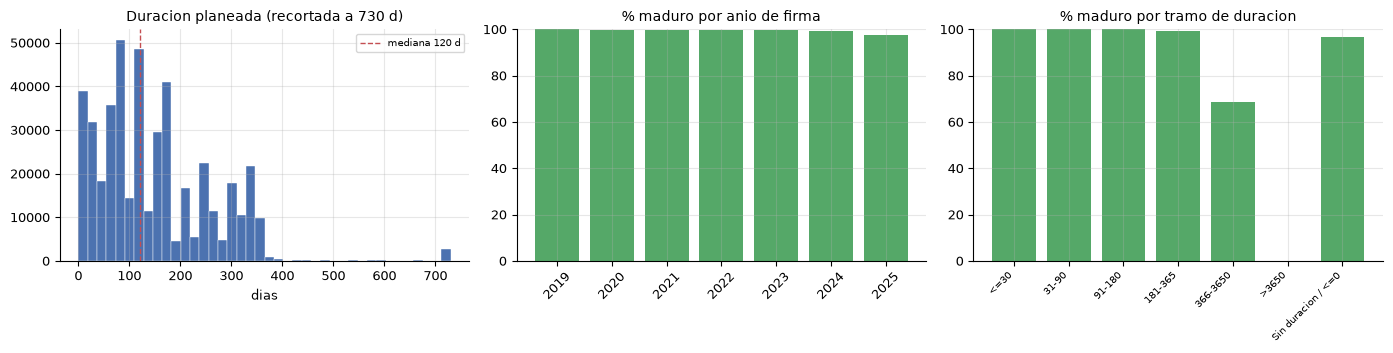

In [17]:
por_anio, por_tramo = eda.resumen_duracion_madurez(base)
display(por_anio)
display(por_tramo)
eda.graficar_duracion_madurez(base, por_anio, por_tramo)
plt.show()

### 3.3.4.3 Madurez y etiqueta

Se calcula la fracción madura por año y la tasa de `y` en maduros frente a no maduros, y por tramo de `eval_dur_planeada_dias` (duración 0 y sin dato separados). `eval_*` se usa solo para analizar; nunca entra como feature.


In [18]:
# 3.3.4.3: madurez y etiqueta. eval_* solo se usa para analizar; nunca como feature.
madurez_anio = (
    base.groupby("anio_firma")["eval_madura"]
    .agg(n="size", maduros="sum")
    .assign(pct_madura=lambda d: 100 * d["maduros"] / d["n"])
)
madurez_anio[["ic_inf_pct", "ic_sup_pct"]] = [
    [100 * x for x in eda.intervalo_wilson(r.maduros, r.n)]
    for r in madurez_anio.itertuples()
]
mostrar_tabla("4.3.1", "Fracción madura por año", madurez_anio.round(2))

base_madurez = base.assign(
    madurez=pd.Categorical(
        base["eval_madura"].map({True: "Maduro", False: "No maduro"}),
        categories=["Maduro", "No maduro"],
        ordered=True,
    )
)
tabla_madurez_y = eda.tasas_en_pct(eda.tasa_por_grupo(base_madurez, "madurez")).round(2)
mostrar_tabla("4.3.2", "Tasa de y por madurez", tabla_madurez_y)

dur = base["eval_dur_planeada_dias"]
tramo = pd.cut(
    dur.where(dur > 0),
    bins=[0, 30, 90, 180, 365, 3650, np.inf],
    labels=["1-30", "31-90", "91-180", "181-365", "366-3650", ">3650"],
    include_lowest=True,
)
tramo = tramo.cat.add_categories(["Duración 0", "Sin dato"])
tramo = tramo.mask(dur.eq(0), "Duración 0").fillna("Sin dato")
tramo = pd.Categorical(
    tramo,
    categories=["Duración 0", "1-30", "31-90", "91-180", "181-365", "366-3650", ">3650", "Sin dato"],
    ordered=True,
)
tabla_dur_y = eda.tasas_en_pct(
    eda.tasa_por_grupo(base.assign(tramo_dur=tramo), "tramo_dur")
).round(2)
mostrar_tabla("4.3.3", "Tasa de y por tramo de duración planeada", tabla_dur_y.sort_values("tramo_dur").reset_index(drop=True))


**Tabla 4.3.1.** Fracción madura por año

,n,maduros,pct_madura,ic_inf_pct,ic_sup_pct
anio_firma,,,,,
2019,14407,14406,99.99,99.96,100.00
2020,36107,36076,99.91,99.88,99.94
2021,56469,56370,99.82,99.79,99.86
2022,71091,70899,99.73,99.69,99.77
2023,83757,83498,99.69,99.65,99.73
2024,88546,88088,99.48,99.43,99.53
2025,102117,99702,97.64,97.54,97.73


**Tabla 4.3.2.** Tasa de y por madurez

,madurez,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Maduro,449039,124272,27.68,27.54,27.81
1,No maduro,3455,776,22.46,21.10,23.88


**Tabla 4.3.3.** Tasa de y por tramo de duración planeada

,tramo_dur,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Duración 0,24566,6077,24.74,24.20,25.28
1,1-30,42517,8711,20.49,20.11,20.87
2,31-90,108000,24899,23.05,22.80,23.31
3,91-180,144602,40288,27.86,27.63,28.09
4,181-365,126781,42764,33.73,33.47,33.99
5,366-3650,5104,2155,42.22,40.87,43.58
6,>3650,125,34,27.20,20.17,35.59
7,Sin dato,799,120,15.02,12.71,17.66


In [19]:
def fila_madurez(df, etiqueta):
    mad, no_mad = df[df["eval_madura"]], df[~df["eval_madura"]]
    tasa_mad = 100 * mad["y"].mean()
    tasa_no = 100 * no_mad["y"].mean() if len(no_mad) else np.nan
    return {"año": etiqueta, "n": len(df), "n maduros": len(mad), "% y maduros": tasa_mad,
            "n no maduros": len(no_mad), "% y no maduros": tasa_no, "dif. no maduro - maduro (pp)": tasa_no - tasa_mad}


filas = [fila_madurez(base[base["anio_firma"] == a], str(a)) for a in sorted(base["anio_firma"].unique())]
filas += [fila_madurez(base[base["anio_firma"] <= 2024], "Subtotal 2019-2024"), fila_madurez(base, "Total")]
mostrar_tabla("4.3.4", "Madurez y tasa de y por año", pd.DataFrame(filas).round(2))

viejo = base[(~base["eval_madura"]) & (base["anio_firma"] <= 2024)].copy()
viejo["grupo"] = viejo["tipo_de_contrato"].where(viejo["tipo_de_contrato"].isin(["Comodato", "Otro"]), "Resto de tipos")
res = (viejo.groupby("grupo")
       .agg(n=("y", "size"), tasa_y_pct=("y", "mean"), mediana_duracion_dias=("eval_dur_planeada_dias", "median"))
       .reindex(["Comodato", "Otro", "Resto de tipos"]))
res["tasa_y_pct"] = 100 * res["tasa_y_pct"]
res.insert(1, "% de no maduros 2019-2024", 100 * res["n"] / len(viejo))
res.loc["Total"] = [len(viejo), 100.0, 100 * viejo["y"].mean(), viejo["eval_dur_planeada_dias"].median()]
res = res.astype({"n": int, "mediana_duracion_dias": int})
mostrar_tabla("4.3.5", "No maduros de 2019-2024 por tipo de contrato", res.round(2))
print("Con duración > 3.650 días:", int((viejo["eval_dur_planeada_dias"] > 3650).sum()),
      "| > 100.000 días:", int((viejo["eval_dur_planeada_dias"] > 100000).sum()),
      "| máximo:", f"{viejo['eval_dur_planeada_dias'].max():,.0f}", "(errores de captura, no plazos)")

**Tabla 4.3.4.** Madurez y tasa de y por año

,año,n,n maduros,% y maduros,n no maduros,% y no maduros,dif. no maduro - maduro (pp)
0,2019,14407,14406,22.16,1,0.00,-22.16
1,2020,36107,36076,29.32,31,48.39,19.07
2,2021,56469,56370,27.83,99,10.10,-17.73
3,2022,71091,70899,29.46,192,10.42,-19.04
4,2023,83757,83498,30.05,259,11.97,-18.08
5,2024,88546,88088,24.72,458,11.57,-13.15
6,2025,102117,99702,27.14,2415,26.79,-0.35
7,Subtotal 2019-2024,350377,349337,27.83,1040,12.40,-15.42
8,Total,452494,449039,27.68,3455,22.46,-5.21


**Tabla 4.3.5.** No maduros de 2019-2024 por tipo de contrato

,n,% de no maduros 2019-2024,tasa_y_pct,mediana_duracion_dias
grupo,,,,
Comodato,305,29.33,1.64,1825
Otro,398,38.27,7.04,1460
Resto de tipos,337,32.40,28.49,1825
Total,1040,100.00,12.40,1825


Con duración > 3.650 días: 97 | > 100.000 días: 6 | máximo: 4,078,903,552 (errores de captura, no plazos)


**Decisión:** Usar `y` (ampliación del plazo; incluye suspensiones y ajustes de fecha, `docs/01_definicion_problema.md`, sección 2) como etiqueta y filtrar `eval_madura = True` en entrenamiento y evaluación. El filtro está en `evaluacion.split_temporal`: ambos índices exigen `base["eval_madura"]`; el modelo se ajusta con esos índices y con `base["y"]` (`modelo.entrenar_v1`). Los no maduros no se usan como negativos ni se imputan, y `eval_madura` no entra como feature (no está en `FEATURES`, `features.FEATURES`). La etiqueta es `y = y_dias | y_modif` (`etiqueta.etiquetar`; metadatos en `modelo.metadatos`).

**Alternativas:**
- Incluir todos los contratos y usar `eval_madura` como feature o peso.
- Imputar `y = 0` a los no maduros.
- Modelo de supervivencia que use la censura (fuera de alcance): requeriría modelar el tiempo hasta la ampliación y los contratos que aún no la han tenido; el alcance v1 es clasificación binaria con contratos maduros (`docs/01_definicion_problema.md`, sección 2).

**Por qué:** Un contrato no maduro no ha tenido tiempo de que se observe una ampliación; tratarlo como negativo confunde censura con ausencia de evento. La pérdida de muestra es pequeña: en train 2019–2023 solo 582 de 261.831 contratos (0,22 %) no son maduros (suma de `n no maduros` de la Tabla 4.3.4). La etiqueta aprobada ya incorpora las ampliaciones publicadas en Modificaciones (`etiqueta.etiquetar`).

**Evidencia:** Tabla 4.3.2: 3.455 no maduros (0,8 % del total de 2019–2025), con `y` 22,5 % frente a 27,7 % en maduros. Tabla 4.3.4: en 2019–2024 (n=1.040 no maduros), 12,4 % en no maduros frente a 27,8 % en maduros; en 2025 (n=2.415), 26,8 % frente a 27,1 %. Tabla 4.3.5: los no maduros de 2019–2024 se reparten entre comodato (305; `y` 1,6 %), Otro (398; `y` 7,0 %) y el resto de tipos (337; `y` 28,5 %).

**Cautela:** La comparación de 2025 no controla por duración; no se afirma que la censura no influya. La exclusión se sostiene por el diseño —tiempo de observación insuficiente—, no por esa comparación.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 4.3

## 3.3.5 Etiqueta `y` frente a `y_dias` por año

`y` es la etiqueta de ampliación del plazo; `y_dias` y `y_modif` se comparan por año. La tabla muestra las tasas y las discrepancias entre `y` y `y_dias`.

> **Nota.** `y`, `y_dias` y `y_modif` son etiquetas; no entran como features.


In [20]:
comp = eda.comparar_etiquetas(base, etiquetas=("y", "y_dias", "y_modif"))
mostrar_tabla("5.1", "Tasa de cada etiqueta por año", eda.tasas_en_pct(comp).round(2))
mostrar_tabla("5.2", "Discrepancias entre y e y_dias por año", eda.discrepancias_etiquetas(base))
print("Contratos con y_modif no nula:", int(base["y_modif"].notna().sum()))
print("Total 2019-2025: " + ", ".join(f"{e} {100 * base[e].mean():.1f} %" for e in ("y", "y_dias", "y_modif")))

**Tabla 5.1.** Tasa de cada etiqueta por año

,anio_firma,etiqueta,n,n_validos,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,2019,y,14407,14407,3192,22.16,21.49,22.84
1,2019,y_dias,14407,14407,1623,11.27,10.76,11.79
2,2019,y_modif,14407,14407,3188,22.13,21.46,22.81
3,2020,y,36107,36107,10592,29.34,28.87,29.81
4,2020,y_dias,36107,36107,4708,13.04,12.70,13.39
5,2020,y_modif,36107,36107,10581,29.30,28.84,29.78
6,2021,y,56469,56469,15698,27.80,27.43,28.17
7,2021,y_dias,56469,56469,5528,9.79,9.55,10.04
8,2021,y_modif,56469,56469,15693,27.79,27.42,28.16
9,2022,y,71091,71091,20907,29.41,29.07,29.74


**Tabla 5.2.** Discrepancias entre y e y_dias por año

,anio_firma,n,comparables,a_1_b_0,a_0_b_1,iguales
0,2019,14407,14407,1569,0,12838
1,2020,36107,36107,5884,0,30223
2,2021,56469,56469,10170,0,46299
3,2022,71091,71091,14194,0,56897
4,2023,83757,83757,14565,0,69192
5,2024,88546,88546,11136,0,77410
6,2025,102117,102117,7241,0,94876


Contratos con y_modif no nula: 452494
Total 2019-2025: y 27.6 %, y_dias 13.3 %, y_modif 27.6 %


In [21]:
ct = pd.crosstab(base["y"], base["y_modif"])
t53 = ct.stack().rename("n").reset_index()
t53["% del total"] = 100 * t53["n"] / len(base)
mostrar_tabla("5.3", "Tabla 2x2 de y y y_modif", t53.round(2))

ct2 = pd.crosstab(base["y"], base["y_dias"])
t54 = pd.DataFrame({"n": ct2.sum(axis=1), "y_dias=0": ct2[0], "y_dias=1": ct2[1]})
t54["% y_dias=1"] = 100 * t54["y_dias=1"] / t54["n"]
t54.loc["Total"] = [t54["n"].sum(), t54["y_dias=0"].sum(), t54["y_dias=1"].sum(), 100 * t54["y_dias=1"].sum() / t54["n"].sum()]
t54 = t54.astype({"n": int, "y_dias=0": int, "y_dias=1": int})
mostrar_tabla("5.4", "Distribución de y_dias dentro de cada valor de y", t54.round(2))

**Tabla 5.3.** Tabla 2x2 de y y y_modif

,y,y_modif,n,% del total
0,0,0,327446,72.36
1,0,1,0,0.00
2,1,0,150,0.03
3,1,1,124898,27.60


**Tabla 5.4.** Distribución de y_dias dentro de cada valor de y

,n,y_dias=0,y_dias=1,% y_dias=1
y,,,,
0,327446,327446,0,0.00
1,125048,64759,60289,48.21
Total,452494,392205,60289,13.32


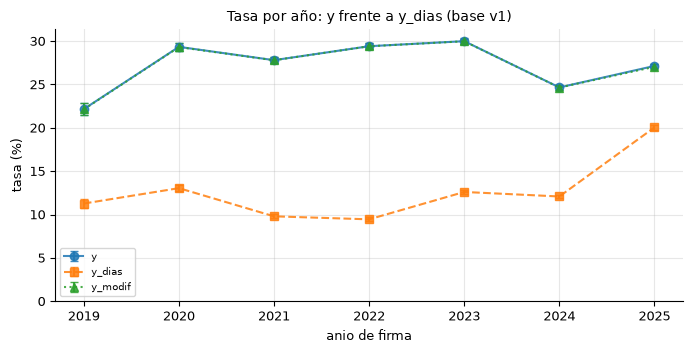

In [22]:
eda.graficar_comparacion_etiquetas(
    comp, titulo="Tasa por año: y frente a y_dias (base v1)"
)
plt.show()


**Decisión:** Usar `y` como objetivo (`etiqueta.etiquetar`; `modelo.metadatos`, `modelo.entrenar_v1`). `y_dias` y `y_modif` no entran como features: no están en `FEATURES` (`features.FEATURES`) y se conservan solo para análisis de sensibilidad. La etiqueta v1 es la unión `y = y_dias | y_modif`.

**Alternativas:**
- Usar `y_dias` sola.
- Usar `y_modif` sola.
- Entrenar dos modelos separados o un modelo multi-etiqueta.

**Por qué:** `y_dias` capta solo el 48,2 % de los positivos (Tabla 5.4): deja fuera 64.759 contratos con `y=1` que solo aparecen en Modificaciones. `y_modif` coincide con `y` salvo 150 contratos (Tabla 5.3), así que la etiqueta descansa casi entera en Modificaciones; usar solo `y_dias` perdería más de la mitad de los positivos, y usar solo `y_modif` perdería los 150 que solo tienen días adicionados. La unión conserva los dos mecanismos.

**Evidencia:** Tabla 5.1: `y` 27,6 %, `y_dias` 13,3 % y `y_modif` 27,6 %; diferencia `y − y_dias` +14,3 pp. Tabla 5.2: 64.759 contratos con `y=1, y_dias=0` y 0 con `y=0, y_dias=1`. Tabla 5.3: 150 contratos con `y=1, y_modif=0`; ninguno con `y=0, y_modif=1`. Tabla 5.4: dentro de `y=1`, 48,2 % tiene `y_dias=1` (60.289 de 125.048).

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 5

## 3.3.6 Hipótesis H1–H7

Tasa de `y` por grupo con intervalo de Wilson del 95 %. Cada subsección deja la tabla y la gráfica; la interpretación y la decisión van al final. La base v1_A es autoponderada; las tasas agrupadas describen la muestra.


In [23]:
Xy = X.assign(y=base["y"], anio_firma=base["anio_firma"])

### H1. Procesos apresurados

Tasa de `y` por tramos de `dias_publicacion_a_firma` (días entre la publicación del proceso y la firma). `Sin dato` agrupa los 380 contratos sin fecha de publicación.

**Tabla 6.1.1.** Tasa de y por días entre publicación y firma

,dias_publicacion_a_firma,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,165613,42237,25.50,25.29,25.71
1,1-7,216256,61277,28.34,28.15,28.53
2,8-15,33810,9410,27.83,27.36,28.31
3,16-30,21228,6629,31.23,30.61,31.85
4,31-60,9738,3898,40.03,39.06,41.01
5,61-120,3259,1193,36.61,34.97,38.28
6,>120,2210,328,14.84,13.42,16.38
7,Sin dato,380,76,20.00,16.29,24.31


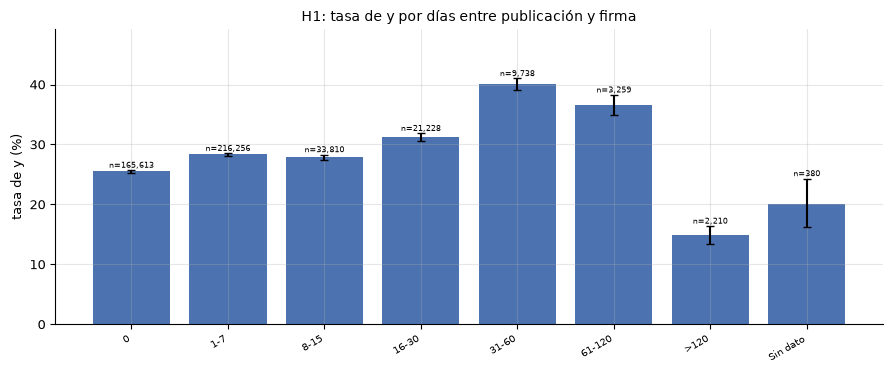

In [24]:
tabla_h1 = eda.tasa_por_tramos(
    Xy, "dias_publicacion_a_firma",
    bins=[-np.inf, 0, 7, 15, 30, 60, 120, np.inf],
    labels=["0", "1-7", "8-15", "16-30", "31-60", "61-120", ">120"],
)
mostrar_tabla("6.1.1", "Tasa de y por días entre publicación y firma", eda.tasas_en_pct(tabla_h1).round(2))
eda.graficar_tasa_por_grupo(
    tabla_h1, col_grupo="dias_publicacion_a_firma",
    titulo="H1: tasa de y por días entre publicación y firma",
)
plt.show()

In [25]:
Xy_tr = Xy[Xy["anio_firma"] <= 2023]
tabla_h1_tr = eda.tasa_por_tramos(
    Xy_tr, "dias_publicacion_a_firma",
    bins=[-np.inf, 0, 7, 15, 30, 60, 120, np.inf],
    labels=["0", "1-7", "8-15", "16-30", "31-60", "61-120", ">120"],
)
mostrar_tabla("6.1.1.b", "Tasa de y por días entre publicación y firma (train 2019-2023)",
              eda.tasas_en_pct(tabla_h1_tr).round(2))

**Tabla 6.1.1.b.** Tasa de y por días entre publicación y firma (train 2019-2023)

,dias_publicacion_a_firma,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,91896,24420,26.57,26.29,26.86
1,1-7,124781,36725,29.43,29.18,29.69
2,8-15,20628,6268,30.39,29.76,31.02
3,16-30,13541,4258,31.45,30.67,32.23
4,31-60,6772,2717,40.12,38.96,41.29
5,61-120,2449,875,35.73,33.85,37.65
6,>120,1753,243,13.86,12.32,15.56
7,Sin dato,11,2,18.18,5.14,47.70


**Resultado: parcial** frente a H1 (`docs/01_definicion_problema.md`, sección 3). La hipótesis espera que los procesos más apresurados (menos días entre publicación y firma) terminen más con el plazo ampliado. En train, el tramo de 0 días queda por debajo de la base (26,6 % frente a 28,8 %) y el máximo está en 31–60 días (40,1 %); la asociación existe, pero no es monótona ni en la dirección de “más apresurado, más ampliación”.

**Decisión:** `dias_publicacion_a_firma` entra como numérica (`features.FEATURES_NUM`); se calcula como `(firma - publicación).dt.days.clip(-30, 1000)` (`features.construir_features`). En la familia `arbol` del pipeline v1 (`modelo.FAMILIA`, `modelo.construir_pipeline`) las numéricas pasan crudas (`preprocesamiento.construir_preprocesador`) y el HGB maneja los NaN de forma nativa (`preprocesamiento.__doc__`). No hay imputación por mediana ni indicador `sin_publicacion` en v1; esos pasos solo existen en la familia `distancia` (`preprocesamiento.construir_preprocesador`), que no es el artefacto.

**Alternativas:**
- Imputar la mediana y agregar un indicador de faltante (el EDA lo llama `sin_publicacion`; en `distancia` se implementa como `dias_publicacion_a_firma_faltante`, `preprocesamiento.ImputarConIndicador`): descartada en v1 porque el HGB maneja NaN de forma nativa (`preprocesamiento.__doc__`) y el faltante es 0,08 % en 2019–2025 (380 de 452.494) y 11 contratos en train.
- Excluirla y dejar que el calendario capture el proceso.
- Usar solo tramos (0, 1–7, 8–15, …): el EDA lo recomendaba para modelos lineales o kNN por la relación no monótona; en v1 entra la numérica cruda.
- Familia `distancia` (kNN/SVM) con imputación, indicador y escalado: existe en `modelado.MODELOS` (3.5), pero no es el artefacto v1.

**Por qué:** La asociación no es lineal: se concentra en 31–120 días y cae en los extremos. El dato está disponible al firmar y el faltante es mínimo.

**Evidencia principal (train 2019–2023):** Tabla 6.1.1.b (n = 261.831; y = 28,8 %): 0 días 26,6 % (n=91.896; -2,3 pp), 31–60 días 40,1 % (n=6.772; +11,3 pp), 61–120 35,7 % (n=2.449; +6,9 pp), >120 13,9 % (n=1.753; -15,0 pp); `Sin dato` 11.

**Contraste 2019–2025:** Tabla 6.1.1: 0 días 25,5 %, 31–60 40,0 %, >120 14,8 %; `Sin dato` 380 (20,0 %). La dirección se mantiene: el máximo sigue en 31–60 días y el tramo 0 sigue por debajo de la base.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.1

### H2. Poca competencia

Tasa de `y` por tramos de respuestas al procedimiento y de proveedores invitados. Los conteos son cero-inflados: la mayoría de los procesos no registra respuestas ni invitados.

**Tabla 6.2.1.** Tasa de y por respuestas al procedimiento

,p_respuestas_al_procedimiento,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,408894,112539,27.52,27.39,27.66
1,1,18009,4530,25.15,24.53,25.79
2,2-3,11449,2924,25.54,24.75,26.35
3,4-9,9530,2900,30.43,29.51,31.36
4,10+,4263,2087,48.96,47.46,50.46
5,Sin dato,349,68,19.48,15.67,23.96


**Tabla 6.2.2.** Tasa de y por proveedores invitados

,p_proveedores_invitados,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,442688,121527,27.45,27.32,27.58
1,1-4,4996,1602,32.07,30.79,33.37
2,5-9,1079,442,40.96,38.07,43.93
3,10+,3382,1409,41.66,40.01,43.33
4,Sin dato,349,68,19.48,15.67,23.96


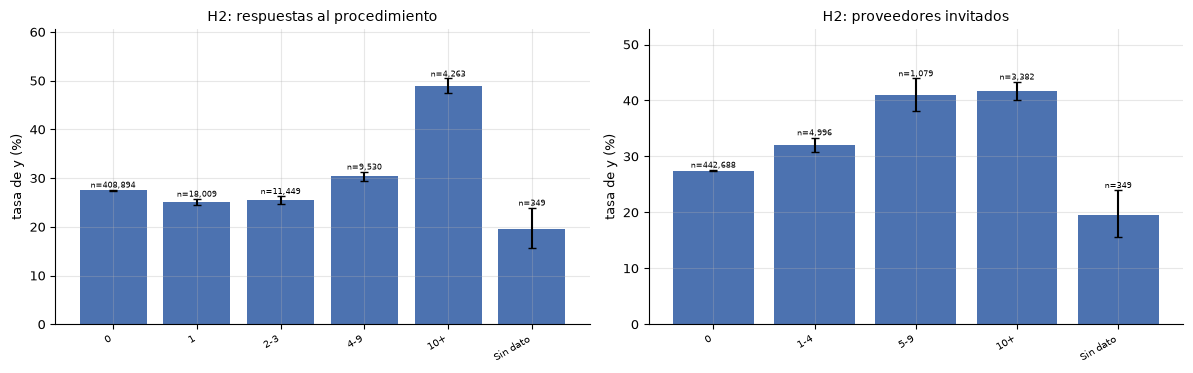

In [26]:
tabla_h2_resp = eda.tasa_por_tramos(
    Xy, "p_respuestas_al_procedimiento",
    bins=[-np.inf, 0, 1, 3, 9, np.inf],
    labels=["0", "1", "2-3", "4-9", "10+"],
)
tabla_h2_inv = eda.tasa_por_tramos(
    Xy, "p_proveedores_invitados",
    bins=[-np.inf, 0, 4, 9, np.inf],
    labels=["0", "1-4", "5-9", "10+"],
)
mostrar_tabla("6.2.1", "Tasa de y por respuestas al procedimiento", eda.tasas_en_pct(tabla_h2_resp).round(2))
mostrar_tabla("6.2.2", "Tasa de y por proveedores invitados", eda.tasas_en_pct(tabla_h2_inv).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
eda.graficar_tasa_por_grupo(
    tabla_h2_resp, col_grupo="p_respuestas_al_procedimiento",
    titulo="H2: respuestas al procedimiento", ax=axes[0],
)
eda.graficar_tasa_por_grupo(
    tabla_h2_inv, col_grupo="p_proveedores_invitados",
    titulo="H2: proveedores invitados", ax=axes[1],
)
plt.show()

In [27]:
Xy_tr = Xy[Xy["anio_firma"] <= 2023]
tabla_h2_resp_tr = eda.tasa_por_tramos(
    Xy_tr, "p_respuestas_al_procedimiento",
    bins=[-np.inf, 0, 1, 3, 9, np.inf],
    labels=["0", "1", "2-3", "4-9", "10+"],
)
tabla_h2_inv_tr = eda.tasa_por_tramos(
    Xy_tr, "p_proveedores_invitados",
    bins=[-np.inf, 0, 4, 9, np.inf],
    labels=["0", "1-4", "5-9", "10+"],
)
mostrar_tabla("6.2.1.b", "Tasa de y por respuestas al procedimiento (train 2019-2023)",
              eda.tasas_en_pct(tabla_h2_resp_tr).round(2))
mostrar_tabla("6.2.2.b", "Tasa de y por proveedores invitados (train 2019-2023)",
              eda.tasas_en_pct(tabla_h2_inv_tr).round(2))

**Tabla 6.2.1.b.** Tasa de y por respuestas al procedimiento (train 2019-2023)

,p_respuestas_al_procedimiento,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,235700,68044,28.87,28.69,29.05
1,1,10079,2489,24.69,23.86,25.55
2,2-3,7220,1782,24.68,23.70,25.69
3,4-9,6163,1854,30.08,28.95,31.24
4,10+,2663,1338,50.24,48.35,52.14
5,Sin dato,6,1,16.67,3.01,56.35


**Tabla 6.2.2.b.** Tasa de y por proveedores invitados (train 2019-2023)

,p_proveedores_invitados,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,255976,73413,28.68,28.50,28.86
1,1-4,3040,948,31.18,29.56,32.85
2,5-9,722,288,39.89,36.38,43.51
3,10+,2087,858,41.11,39.02,43.24
4,Sin dato,6,1,16.67,3.01,56.35


**Resultado: contraria a la hipótesis** H2 (`docs/01_definicion_problema.md`, sección 3). La hipótesis espera más ampliaciones cuando hay poca competencia; los datos muestran lo contrario en el número de respuestas: 0 respuestas queda en la base (28,9 %) y 10+ sube a 50,2 %, mientras que 1–3 respuestas queda por debajo (24,7 %).

**Decisión:** De las siete features de competencia marcadas `por verificar` (`features.FEATURES_POR_VERIFICAR`), seis entran como numéricas crudas (`p_respuestas_al_procedimiento` y `p_proveedores_invitados` son las principales, `features.FEATURES_POR_VERIFICAR`; cálculo en `features.construir_features`); `p_proveedores_que_manifestaron` se descarta por ser constante 0 en el train (`preprocesamiento.CONSTANTES`). En la familia `arbol` no se imputan los ceros, no se aplica `log1p` y no se dicotomizan (`preprocesamiento.construir_preprocesador`); el HGB maneja los NaN (`preprocesamiento.__doc__`). la ablación de 3.6 mantuvo las ocho `FEATURES_POR_VERIFICAR` en la lista (las siete de competencia y `log_pago_adelantado`, `features.FEATURES_NUM`); la ablación de quitarlas no cambió el PR-AUC 0,584 (`resultados/j3_decisiones.md`).

**Alternativas:**
- Excluirlas por la alta proporción de ceros.
- Usar solo una de las dos.
- Dicotomizar en “cero” frente a “alguna”, o en “10+” frente al resto.
- `log1p` + `RobustScaler` para kNN/SVM: existe en la familia `distancia` (`preprocesamiento.construir_preprocesador`) y en los modelos de `modelado.MODELOS`, pero no en v1.

**Por qué:** La mayoría de los contratos no registra competencia, pero la cola se asocia con más ampliaciones; la relación no es lineal y los árboles pueden capturarla. La ablación de 3.6 muestra que el aporte no cambia el PR-AUC al quitarlas, así que se mantienen en `FEATURES` por ser información disponible al firmar y sin costo de imputación.

**Evidencia principal (train 2019–2023):** Tabla 6.2.1.b (n = 261.831; y = 28,8 %): 0 respuestas 28,9 % (n=235.700; +0,0 pp), 1 24,7 % (n=10.079; -4,1 pp), 2–3 24,7 % (n=7.220; -4,2 pp), 4–9 30,1 % (n=6.163; +1,2 pp), 10+ 50,2 % (n=2.663; +21,4 pp). Tabla 6.2.2.b: 0 invitados 28,7 % (n=255.976; -0,2 pp), 1–4 31,2 % (n=3.040; +2,3 pp), 5–9 39,9 % (n=722; +11,1 pp), 10+ 41,1 % (n=2.087; +12,3 pp).

**Contraste 2019–2025:** Tabla 6.2.1: 0 respuestas 27,5 %, 10+ 49,0 %; Tabla 6.2.2: 0 invitados 27,5 %, 10+ 41,7 %. La dirección se mantiene.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.2

### H3. Modalidad de contratación

Tasa de `y` por modalidad. Se muestran las 12 modalidades más frecuentes; el resto queda en `OTROS`.

**Tabla 6.3.1.** Tasa de y por modalidad de contratación

,modalidad_de_contratacion,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Contratación directa,347300,87635,25.23,25.09,25.38
1,Contratación régimen especial,60145,24479,40.70,40.31,41.09
2,Mínima cuantía,24468,4407,18.01,17.53,18.50
3,Contratación Directa (con ofertas),4833,1533,31.72,30.42,33.05
4,Selección Abreviada de Menor Cuantía,4623,1920,41.53,40.12,42.96
5,Selección abreviada subasta inversa,4141,1512,36.51,35.06,37.99
6,Contratación régimen especial (con ofertas),3463,1250,36.10,34.51,37.71
7,Concurso de méritos abierto,1284,846,65.89,63.25,68.43
8,Licitación pública,1184,699,59.04,56.21,61.80
9,Licitación pública Obra Publica,810,642,79.26,76.33,81.91


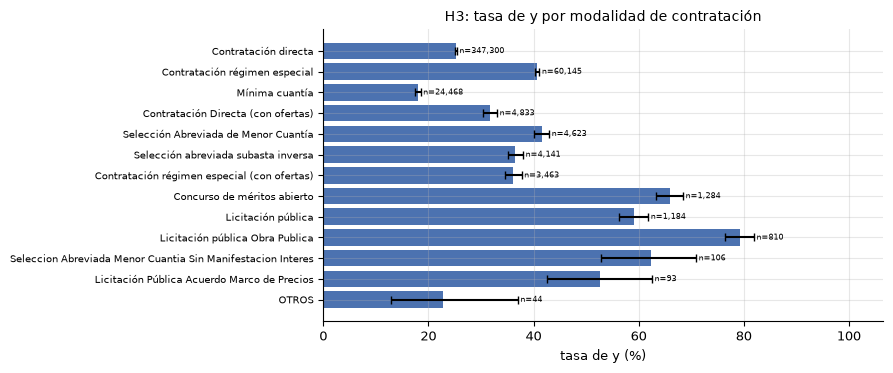

In [28]:
tabla_h3 = eda.tasa_top_categorias(Xy, "modalidad_de_contratacion", top=12)
mostrar_tabla("6.3.1", "Tasa de y por modalidad de contratación", eda.tasas_en_pct(tabla_h3).round(2))
eda.graficar_tasa_por_grupo(
    tabla_h3, col_grupo="modalidad_de_contratacion",
    titulo="H3: tasa de y por modalidad de contratación", horizontal=True,
)
plt.show()

In [29]:
Xy_tr = Xy[Xy["anio_firma"] <= 2023]
tabla_h3_tr = eda.tasa_top_categorias(Xy_tr, "modalidad_de_contratacion", top=12)
mostrar_tabla("6.3.1.b", "Tasa de y por modalidad de contratación (train 2019-2023)",
              eda.tasas_en_pct(tabla_h3_tr).round(2))

**Tabla 6.3.1.b.** Tasa de y por modalidad de contratación (train 2019-2023)

,modalidad_de_contratacion,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Contratación directa,203256,53149,26.15,25.96,26.34
1,Contratación régimen especial,30663,14408,46.99,46.43,47.55
2,Mínima cuantía,15280,2634,17.24,16.65,17.85
3,Selección Abreviada de Menor Cuantía,2951,1186,40.19,38.43,41.97
4,Contratación Directa (con ofertas),2897,908,31.34,29.68,33.06
5,Selección abreviada subasta inversa,2523,881,34.92,33.08,36.80
6,Contratación régimen especial (con ofertas),1908,752,39.41,37.24,41.62
7,Concurso de méritos abierto,869,587,67.55,64.36,70.58
8,Licitación pública,749,447,59.68,56.13,63.13
9,Licitación pública Obra Publica,561,456,81.28,77.85,84.29


**Resultado: confirmada** para H3 (`docs/01_definicion_problema.md`, sección 3). La modalidad separa tasas muy distintas, desde 81,3 % en licitación pública de obra hasta 17,2 % en mínima cuantía; la hipótesis no fija una dirección, solo que la modalidad influye, y eso se observa.

**Decisión:** `modalidad_de_contratacion` y `justificacion_modalidad_de` entran como categóricas (`features.FEATURES_CAT`). En la familia `arbol` se codifican con `OrdinalEncoder(max_categories=200)`, que agrupa las categorías infrecuentes en un solo código (`preprocesamiento.construir_preprocesador`); no hay one-hot ni una dicotomía directa/competitiva construida a mano. Las categorías nativas se descartaron porque la app explica con SHAP TreeExplainer (`resultados/j3_decisiones.md`).

**Alternativas:**
- Excluirla y dejar solo tipo de contrato o UNSPSC.
- Dicotomizar en contratación directa frente a competitiva.
- One-hot completo sin agrupar.
- Categorías nativas de HGB: +0,003 de PR-AUC cv, dentro del ruido, pero la app no puede explicarlas (`resultados/j3_decisiones.md`).

**Por qué:** La modalidad separa tasas muy distintas, pero puede estar confundida con el tipo de objeto y con el peso de la contratación directa. La codificación ordinal con tope de 200 deja que el HGB parta el espacio y evita estimaciones inestables de categorías con pocos casos.

**Evidencia principal (train 2019–2023):** Tabla 6.3.1.b (n = 261.831; y = 28,8 %): licitación pública de obra 81,3 % (n=561), concurso de méritos abierto 67,5 % (n=869), licitación pública 59,7 % (n=749), régimen especial 47,0 % (n=30.663), selección abreviada de menor cuantía 40,2 % (n=2.951), contratación directa 26,1 % (n=203.256), mínima cuantía 17,2 % (n=15.280).

**Contraste 2019–2025:** Tabla 6.3.1: licitación pública de obra 79,3 %, concurso de méritos 65,9 %, régimen especial 40,7 %, selección abreviada de menor cuantía 41,5 %, contratación directa 25,2 %, mínima cuantía 18,0 %. La dirección general se mantiene; **cambia el orden** entre régimen especial (47,0 %) y selección abreviada (40,2 %) en train, que en 2019–2025 aparecen como 40,7 % y 41,5 %.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.3

### H4. Anualidad presupuestal

Tasa de `y` por mes de firma y por el indicador `firma_ultimo_trimestre` (1 = octubre–diciembre).

**Tabla 6.4.1.** Tasa de y por mes de firma

,mes_firma,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,1,82120,27817,33.87,33.55,34.20
1,2,63897,22069,34.54,34.17,34.91
2,3,35669,11456,32.12,31.63,32.60
3,4,24962,7020,28.12,27.57,28.68
4,5,26881,7850,29.20,28.66,29.75
5,6,26565,7860,29.59,29.04,30.14
6,7,33062,8323,25.17,24.71,25.64
7,8,34231,8433,24.64,24.18,25.09
8,9,35200,6839,19.43,19.02,19.85
9,10,33551,6084,18.13,17.72,18.55


**Tabla 6.4.2.** Tasa de y por último trimestre

,firma_ultimo_trimestre,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,362587,107667,29.69,29.55,29.84
1,1,89907,17381,19.33,19.08,19.59


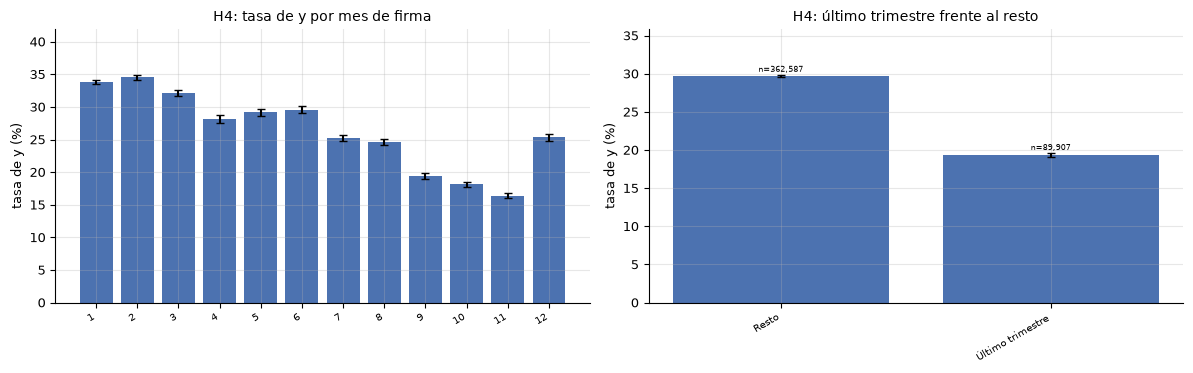

In [30]:
tabla_h4_mes = eda.tasa_por_grupo(Xy, "mes_firma")
tabla_h4_mes["mes_firma"] = tabla_h4_mes["mes_firma"].astype(int)
tabla_h4_flag = eda.tasa_por_grupo(Xy, "firma_ultimo_trimestre")
tabla_h4_flag["firma_ultimo_trimestre"] = tabla_h4_flag["firma_ultimo_trimestre"].astype(int)
tabla_h4_flag_plot = tabla_h4_flag.assign(
    firma_ultimo_trimestre=tabla_h4_flag["firma_ultimo_trimestre"].map({0: "Resto", 1: "Último trimestre"})
)
mostrar_tabla("6.4.1", "Tasa de y por mes de firma", eda.tasas_en_pct(tabla_h4_mes).round(2))
mostrar_tabla("6.4.2", "Tasa de y por último trimestre", eda.tasas_en_pct(tabla_h4_flag).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
eda.graficar_tasa_por_grupo(
    tabla_h4_mes, col_grupo="mes_firma",
    titulo="H4: tasa de y por mes de firma", ax=axes[0], mostrar_n=False,
)
eda.graficar_tasa_por_grupo(
    tabla_h4_flag_plot, col_grupo="firma_ultimo_trimestre",
    titulo="H4: último trimestre frente al resto", ax=axes[1],
)
plt.show()

In [31]:
Xy_tr = Xy[Xy["anio_firma"] <= 2023]
tabla_h4_mes_tr = eda.tasa_por_grupo(Xy_tr, "mes_firma")
tabla_h4_mes_tr["mes_firma"] = tabla_h4_mes_tr["mes_firma"].astype(int)
tabla_h4_flag_tr = eda.tasa_por_grupo(Xy_tr, "firma_ultimo_trimestre")
tabla_h4_flag_tr["firma_ultimo_trimestre"] = tabla_h4_flag_tr["firma_ultimo_trimestre"].astype(int)
mostrar_tabla("6.4.1.b", "Tasa de y por mes de firma (train 2019-2023)", eda.tasas_en_pct(tabla_h4_mes_tr).round(2))
mostrar_tabla("6.4.2.b", "Tasa de y por último trimestre (train 2019-2023)", eda.tasas_en_pct(tabla_h4_flag_tr).round(2))

**Tabla 6.4.1.b.** Tasa de y por mes de firma (train 2019-2023)

,mes_firma,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,1,57494,19421,33.78,33.39,34.17
1,2,36205,13169,36.37,35.88,36.87
2,3,18677,6610,35.39,34.71,36.08
3,4,11369,3435,30.21,29.38,31.06
4,5,13635,4459,32.70,31.92,33.49
5,6,16701,5487,32.85,32.15,33.57
6,7,19044,5171,27.15,26.53,27.79
7,8,19979,4975,24.90,24.31,25.51
8,9,18541,3394,18.31,17.76,18.87
9,10,16814,2706,16.09,15.55,16.66


**Tabla 6.4.2.b.** Tasa de y por último trimestre (train 2019-2023)

,firma_ultimo_trimestre,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,211645,66121,31.24,31.04,31.44
1,1,50186,9387,18.70,18.37,19.05


**Resultado: contraria a la hipótesis** H4 (`docs/01_definicion_problema.md`, sección 3). La hipótesis espera más ampliaciones en el último trimestre; la tabla muestra lo contrario: 18,7 % en el último trimestre frente a 31,2 % en el resto en train (19,3 % frente a 29,7 % en 2019–2025).

**Decisión:** `mes_firma`, `firma_ultimo_trimestre`, `fin_planeado_cruza_anio` y `dias_firma_a_inicio` entran como numéricas (`features.FEATURES_NUM`). `mes_firma` se calcula como `firma.dt.month`, entero 1–12 (`features.construir_features`), y en la familia `arbol` pasa crudo (`preprocesamiento.construir_preprocesador`); no se trata como cíclica ni como one-hot. La versión cíclica (seno/coseno) existe solo en la familia `distancia` (`preprocesamiento.CICLICAS`, `preprocesamiento.construir_preprocesador`). `anio_firma` no está en `FEATURES` (`features.FEATURES`).

**Alternativas:**
- Excluir el calendario.
- Usar solo el último trimestre.
- Incluir el año de firma (descartado por deriva).
- `mes_firma` cíclica u one-hot, como recomendaba el EDA: descartada en v1; la versión cíclica solo se usa en `distancia` (`preprocesamiento.CICLICAS`, `preprocesamiento.construir_preprocesador`) y el HGB puede aislar cualquier mes con cortes sobre el entero.

**Por qué:** El patrón estacional es marcado y está disponible al firmar. La hipótesis sobre el último trimestre no se cumple en la dirección esperada, pero el mes sigue separando tasas y entra al modelo. No se incluye el año para no introducir deriva.

**Evidencia principal (train 2019–2023):** Tabla 6.4.2.b (n = 261.831; y = 28,8 %): último trimestre 18,7 % (n=50.186; -10,1 pp) y resto 31,2 % (n=211.645; +2,4 pp). Tabla 6.4.1.b: máximo en febrero 36,4 % (n=36.205), mínimo en octubre 16,1 % (n=16.814); enero 33,8 %, noviembre 16,2 %.

**Contraste 2019–2025:** Tabla 6.4.2: último trimestre 19,3 % frente a resto 29,7 %; Tabla 6.4.1: febrero 34,5 %, enero 33,9 %, noviembre 16,4 %. La dirección se mantiene y se acentúa.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.4

### H5. Plazos subestimados

Tasa de `y` por la duración planeada relativa a la mediana de su familia UNSPSC (`p_dur_dias / mediana de la familia`) y por la duración absoluta en días. La mediana de referencia se calcula con 2019–2023 y duración > 0.

**Tabla 6.5.1.** Tasa de y por duración relativa a la mediana de la familia

,duracion_relativa,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=0,24099,5908,24.52,23.98,25.06
1,"(0, 0.5]",94724,18872,19.92,19.67,20.18
2,"(0.5, 1]",132540,36113,27.25,27.01,27.49
3,"(1, 1.5]",84427,25470,30.17,29.86,30.48
4,"(1.5, 2]",55873,22617,40.48,40.07,40.89
5,"(2, 3]",47255,12410,26.26,25.87,26.66
6,>3,8951,2200,24.58,23.70,25.48
7,Sin dato,4625,1458,31.52,30.20,32.88


**Tabla 6.5.2.** Tasa de y por duración planeada absoluta

,p_dur_dias,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=0,24566,6077,24.74,24.20,25.28
1,1-30,42517,8711,20.49,20.11,20.87
2,31-90,108000,24899,23.05,22.80,23.31
3,91-180,144602,40288,27.86,27.63,28.09
4,181-365,126781,42764,33.73,33.47,33.99
5,366-730,2951,1685,57.10,55.31,58.87
6,>730,2278,504,22.12,20.47,23.88
7,Sin dato,799,120,15.02,12.71,17.66


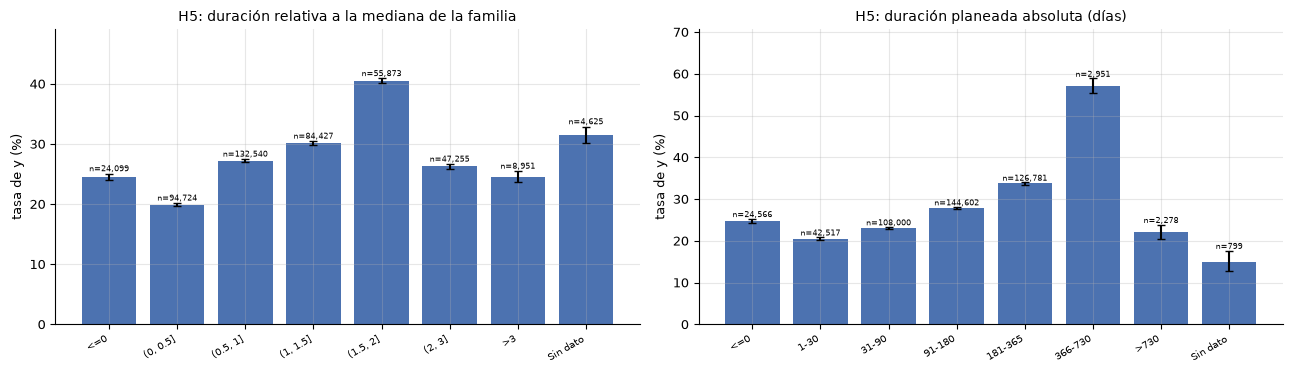

In [32]:
dur_h5 = eda.duracion_relativa_objeto(Xy, anio_referencia=2023)
Xy = Xy.assign(duracion_relativa=dur_h5["duracion_relativa"])
tabla_h5_rel = eda.tasa_por_tramos(
    Xy, "duracion_relativa",
    bins=[-np.inf, 0, 0.5, 1, 1.5, 2, 3, np.inf],
    labels=["<=0", "(0, 0.5]", "(0.5, 1]", "(1, 1.5]", "(1.5, 2]", "(2, 3]", ">3"],
)
tabla_h5_abs = eda.tasa_por_tramos(
    Xy, "p_dur_dias",
    bins=[-np.inf, 0, 30, 90, 180, 365, 730, np.inf],
    labels=["<=0", "1-30", "31-90", "91-180", "181-365", "366-730", ">730"],
)
mostrar_tabla("6.5.1", "Tasa de y por duración relativa a la mediana de la familia", eda.tasas_en_pct(tabla_h5_rel).round(2))
mostrar_tabla("6.5.2", "Tasa de y por duración planeada absoluta", eda.tasas_en_pct(tabla_h5_abs).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
eda.graficar_tasa_por_grupo(
    tabla_h5_rel, col_grupo="duracion_relativa",
    titulo="H5: duración relativa a la mediana de la familia", ax=axes[0],
)
eda.graficar_tasa_por_grupo(
    tabla_h5_abs, col_grupo="p_dur_dias",
    titulo="H5: duración planeada absoluta (días)", ax=axes[1],
)
plt.show()

In [33]:
Xy_tr = Xy[Xy["anio_firma"] <= 2023]
dur_h5_tr = eda.duracion_relativa_objeto(Xy_tr, anio_referencia=2023)
Xy_tr = Xy_tr.assign(duracion_relativa=dur_h5_tr["duracion_relativa"])
tabla_h5_rel_tr = eda.tasa_por_tramos(
    Xy_tr, "duracion_relativa",
    bins=[-np.inf, 0, 0.5, 1, 1.5, 2, 3, np.inf],
    labels=["<=0", "(0, 0.5]", "(0.5, 1]", "(1, 1.5]", "(1.5, 2]", "(2, 3]", ">3"],
)
tabla_h5_abs_tr = eda.tasa_por_tramos(
    Xy_tr, "p_dur_dias",
    bins=[-np.inf, 0, 30, 90, 180, 365, 730, np.inf],
    labels=["<=0", "1-30", "31-90", "91-180", "181-365", "366-730", ">730"],
)
mostrar_tabla("6.5.1.b", "Tasa de y por duración relativa a la mediana de la familia (train 2019-2023)",
              eda.tasas_en_pct(tabla_h5_rel_tr).round(2))
mostrar_tabla("6.5.2.b", "Tasa de y por duración planeada absoluta (train 2019-2023)",
              eda.tasas_en_pct(tabla_h5_abs_tr).round(2))

**Tabla 6.5.1.b.** Tasa de y por duración relativa a la mediana de la familia (train 2019-2023)

,duracion_relativa,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=0,13517,3411,25.23,24.51,25.97
1,"(0, 0.5]",51465,10537,20.47,20.13,20.82
2,"(0.5, 1]",74858,21267,28.41,28.09,28.73
3,"(1, 1.5]",50688,16039,31.64,31.24,32.05
4,"(1.5, 2]",33771,13873,41.08,40.56,41.61
5,"(2, 3]",29503,8196,27.78,27.27,28.29
6,>3,5836,1614,27.66,26.52,28.82
7,Sin dato,2193,571,26.04,24.24,27.91


**Tabla 6.5.2.b.** Tasa de y por duración planeada absoluta (train 2019-2023)

,p_dur_dias,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=0,13712,3471,25.31,24.59,26.05
1,1-30,23487,5353,22.79,22.26,23.33
2,31-90,58498,13497,23.07,22.73,23.42
3,91-180,83890,24272,28.93,28.63,29.24
4,181-365,78359,27164,34.67,34.33,35.00
5,366-730,2222,1325,59.63,57.58,61.65
6,>730,1381,394,28.53,26.21,30.97
7,Sin dato,282,32,11.35,8.15,15.58


**Resultado: contraria a la hipótesis** H5 (`docs/01_definicion_problema.md`, sección 3). La hipótesis espera que los plazos más subestimados se amplíen más; la tabla muestra lo contrario: (0, 0,5] de la duración típica tiene 20,5 % y (1,5, 2] tiene 41,1 % en train (19,9 % frente a 40,5 % en 2019–2025).

**Decisión:** `p_dur_dias` entra como numérica (`features.FEATURES_NUM`, `features.construir_features`) y pasa por `DuracionLimpia` dentro del Pipeline (`preprocesamiento.DuracionLimpia`, `preprocesamiento.construir_preprocesador`): los valores 0 o negativos se vuelven NaN y generan el indicador `p_dur_dias_cero`, y el resto se recorta al cuantil 99,9 % aprendido del train (`preprocesamiento.CUANTIL_DURACION`, `preprocesamiento.DuracionLimpia`); en el ajuste v1 (train maduro 2019–2023) ese tope es 1.259 días. `p_unidad_de_duracion` entra como categórica (`features.FEATURES_CAT`) y se codifica con el mismo `OrdinalEncoder`. No hay recorte fijo a 3.650 días: 3.650 es solo un corte descriptivo de la Tabla 4.3.3. La duración relativa a la mediana de la familia no está en `FEATURES`; solo existe para el EDA (`eda.duracion_relativa_objeto`).

**Alternativas:**
- Excluir la duración y usar solo el calendario.
- Usar tramos en vez de la numérica.
- Incluir solo la duración relativa: queda como alternativa opcional, fuera del pipeline v1; no está en `FEATURES` y solo se calcula en `eda.duracion_relativa_objeto`.
- Recorte fijo a 3.650 días, como recomendaba el EDA: descartado; el Pipeline usa el p99,9 aprendido del train (`preprocesamiento.DuracionLimpia`, `preprocesamiento.CUANTIL_DURACION`), que se adapta a la distribución y no fija un corte arbitrario.
- `log1p` + `RobustScaler` para kNN/SVM: solo en la familia `distancia` (`preprocesamiento.construir_preprocesador`), no en v1.

**Por qué:** La relación no es monótona: sube hasta 366–730 días y cae en >730; la relativa muestra un máximo en (1,5, 2]. La duración 0 no es un plazo real y se trata como faltante, no como cero, con su indicador.

**Evidencia principal (train 2019–2023):** Tabla 6.5.1.b (n = 261.831): (0, 0,5] 20,5 % (n=51.465; -8,4 pp), (0,5, 1] 28,4 %, (1, 1,5] 31,6 %, (1,5, 2] 41,1 % (n=33.771; +12,2 pp), (2, 3] 27,8 %, >3 27,7 %, <=0 25,2 %. Tabla 6.5.2.b: <=0 25,3 % (n=13.712), 1–30 22,8 %, 31–90 23,1 %, 91–180 28,9 %, 181–365 34,7 %, 366–730 59,6 % (n=2.222), >730 28,5 % (n=1.381), sin dato 11,3 %.

**Contraste 2019–2025:** Tabla 6.5.1: (0, 0,5] 19,9 %, (1,5, 2] 40,5 %; Tabla 6.5.2: 366–730 57,1 %, >730 22,1 %, <=0 24,7 %. La dirección se mantiene.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.5

### H6. Hábitos de la entidad

Tasa de `y` en 2024 por grupo de la tasa histórica de la entidad (2019–2023): `Sin historia`, `Tasa 0` y terciles `T1`–`T3` de las entidades con tasa > 0. `T1` es el tercil de menor tasa histórica y `T3` el de mayor; `Sin historia` agrupa las entidades que no aparecen antes de 2024. Los terciles se arman sobre el rank de la tasa para que los empates no los colapsen. La tabla principal agrega mínimo, mediana y máximo de la tasa histórica por grupo; el resumen por entidad muestra cómo los empates se reparten entre grupos.

**Tabla 6.6.1.** Tasa de y en 2024 por grupo de tasa histórica de la entidad

,grupo_hist,n,positivos,n_entidades,tasa_pct,ic_inf_pct,ic_sup_pct,tasa_hist_min_pct,tasa_hist_mediana_pct,tasa_hist_max_pct
0,Sin historia,1833,211,317,11.51,10.13,13.05,NaN,NaN,NaN
1,Tasa 0,6460,735,553,11.38,10.63,12.18,0.00,0.00,0.00
2,T1,21231,3030,416,14.27,13.81,14.75,0.40,10.34,16.42
3,T2,31741,6513,423,20.52,20.08,20.97,16.48,22.56,30.59
4,T3,27281,11342,377,41.57,40.99,42.16,30.71,42.86,100.00


**Tabla 6.6.2.** Resumen por entidad de la tasa histórica

,grupo,entidades,tasa_min_pct,tasa_mediana_pct,tasa_max_pct
0,T1,439,0.40,10.34,16.42
1,T2,439,16.48,22.56,30.59
2,T3,439,30.71,42.86,100.00
3,Tasa 0,1017,0.00,0.00,0.00


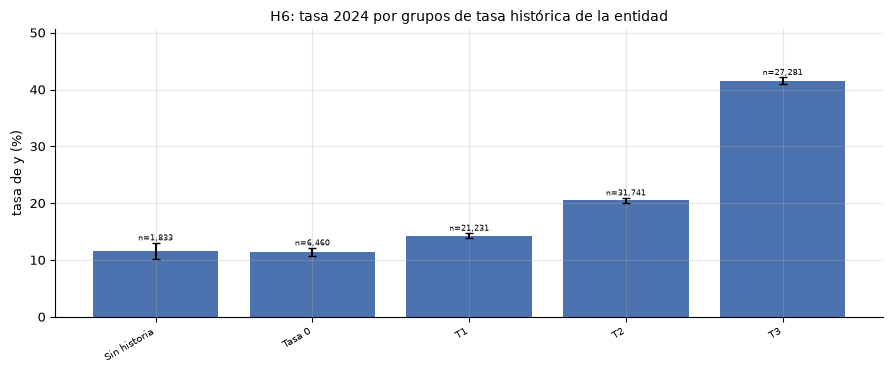

In [34]:
tabla_h6, hist_h6 = eda.tasa_entidad_historica(base, anio_objetivo=2024)
resumen_h6 = (
    hist_h6.groupby("grupo", observed=False)
    .agg(entidades=("tasa", "size"), tasa_min=("tasa", "min"),
         tasa_mediana=("tasa", "median"), tasa_max=("tasa", "max"))
    .reset_index()
)
mostrar_tabla("6.6.1", "Tasa de y en 2024 por grupo de tasa histórica de la entidad", eda.tasas_en_pct(tabla_h6).round(2))
mostrar_tabla("6.6.2", "Resumen por entidad de la tasa histórica", eda.tasas_en_pct(resumen_h6).round(2))
eda.graficar_tasa_por_grupo(
    tabla_h6, col_grupo="grupo_hist",
    titulo="H6: tasa 2024 por grupos de tasa histórica de la entidad",
)
plt.show()

**Resultado: confirmada** para H6 (`docs/01_definicion_problema.md`, sección 3). La tasa histórica de la entidad separa la tasa futura: T3 41,6 %, T2 20,5 %, T1 14,3 %, tasa 0 11,4 %, sin historia 11,5 % en test 2024.

**Decisión:** `nit_entidad` entra como categórica (`features.FEATURES_CAT`) y se codifica con `TargetEncoder(target_type="binary", smooth="auto", cv=StratifiedKFold(5, shuffle=True, random_state=config.SEED))` dentro del Pipeline (`preprocesamiento._target_encoder`, `preprocesamiento.construir_preprocesador`); las entidades no vistas reciben la media global del train (`preprocesamiento._target_encoder`). Los proxies de entidad (`sector`, `orden`, `rama`, `entidad_centralizada`, `departamento`, `ciudad`) entran como categóricas (`features.FEATURES_CAT`) y, como el resto de categóricas, usan `OrdinalEncoder(max_categories=200)` (`preprocesamiento.construir_preprocesador`). No se usa one-hot de entidad ni el nombre.

**Alternativas:**
- One-hot de entidad: inviable por cardinalidad (2.086 entidades en test 2024, Tabla 6.6.1).
- Excluir la entidad.
- Usar la tasa histórica calculada fuera del Pipeline: filtraría información y no se reajustaría con cada fold.
- Codificar `nit_entidad` con `OrdinalEncoder` como el resto: convertiría un código arbitrario en una escala ordinal; el `TargetEncoder` captura la tasa histórica, que es la señal de H6.

**Por qué:** La tasa histórica de la entidad se asocia con la tasa futura, y las entidades sin historia se separan con una tasa baja; el codificador debe aprenderla solo con train para no filtrar 2024. La cardinalidad alta hace inviable el one-hot. El `cv` interno evita fuga dentro del train.

**Evidencia:** Tabla 6.6.1 (test 2024; historia 2019–2023; n=88.546): T3 41,6 %, T2 20,5 %, T1 14,3 %, tasa 0 11,4 %, sin historia 11,5 %. Tabla 6.6.2: 439 entidades en cada tercil y 1.017 en tasa 0. Esta sección usa test 2024, no las tablas `.b` de train.

**Cautela:** La evidencia sale de test 2024, no de train; la tasa histórica se calcula solo con 2019–2023. No se usa 2024 para ajustar el codificador.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.6

### H7. Tipo de objeto

Tasa de `y` por segmento y familia UNSPSC, por tipo de contrato y por longitud del objeto (proxy de complejidad). En segmento, familia y tipo se muestran las 10 categorías más frecuentes; el resto queda en `OTROS`.

**Tabla 6.7.1.** Tasa de y por segmento UNSPSC

,unspsc_segmento,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,80,323045,87160,26.98,26.83,27.13
1,85,26352,10147,38.51,37.92,39.09
2,93,21784,6951,31.91,31.29,32.53
3,81,11535,3249,28.17,27.35,28.99
4,86,9692,2247,23.18,22.35,24.03
5,72,7355,2858,38.86,37.75,39.98
6,84,3811,965,25.32,23.97,26.73
7,Sin dato,3806,1331,34.97,33.47,36.50
8,77,3605,821,22.77,21.43,24.17
9,78,3344,848,25.36,23.91,26.86


**Tabla 6.7.2.** Tasa de y por familia UNSPSC

,unspsc_familia,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,8011,285020,77576,27.22,27.05,27.38
1,8510,19289,8429,43.70,43.00,44.40
2,8016,14181,3469,24.46,23.76,25.18
3,8010,12386,3279,26.47,25.70,27.26
4,9314,11844,3901,32.94,32.10,33.79
5,9315,8337,2680,32.15,31.15,33.16
6,8610,6485,1565,24.13,23.11,25.19
7,8012,5257,1178,22.41,21.30,23.56
8,8512,5081,1271,25.01,23.84,26.22
9,8110,4715,1833,38.88,37.49,40.28


**Tabla 6.7.3.** Tasa de y por tipo de contrato

,tipo_de_contrato,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Prestación de servicios,388023,105320,27.14,27.00,27.28
1,Otro,16849,6387,37.91,37.18,38.64
2,Decreto 092 de 2017,15978,4050,25.35,24.68,26.03
3,Suministros,10780,2292,21.26,20.50,22.04
4,Compraventa,8917,1959,21.97,21.12,22.84
5,Obra,4081,2116,51.85,50.32,53.38
6,Arrendamiento de inmuebles,3494,1178,33.71,32.17,35.30
7,Interventoría,1043,749,71.81,69.01,74.46
8,Comodato,1040,171,16.44,14.31,18.82
9,Consultoría,889,377,42.41,39.20,45.68


**Tabla 6.7.4.** Tasa de y por longitud del objeto

,len_objeto,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=50,5863,3398,57.96,56.69,59.21
1,51-100,17915,6154,34.35,33.66,35.05
2,101-200,142903,36088,25.25,25.03,25.48
3,201-400,239544,67642,28.24,28.06,28.42
4,>400,46269,11766,25.43,25.03,25.83


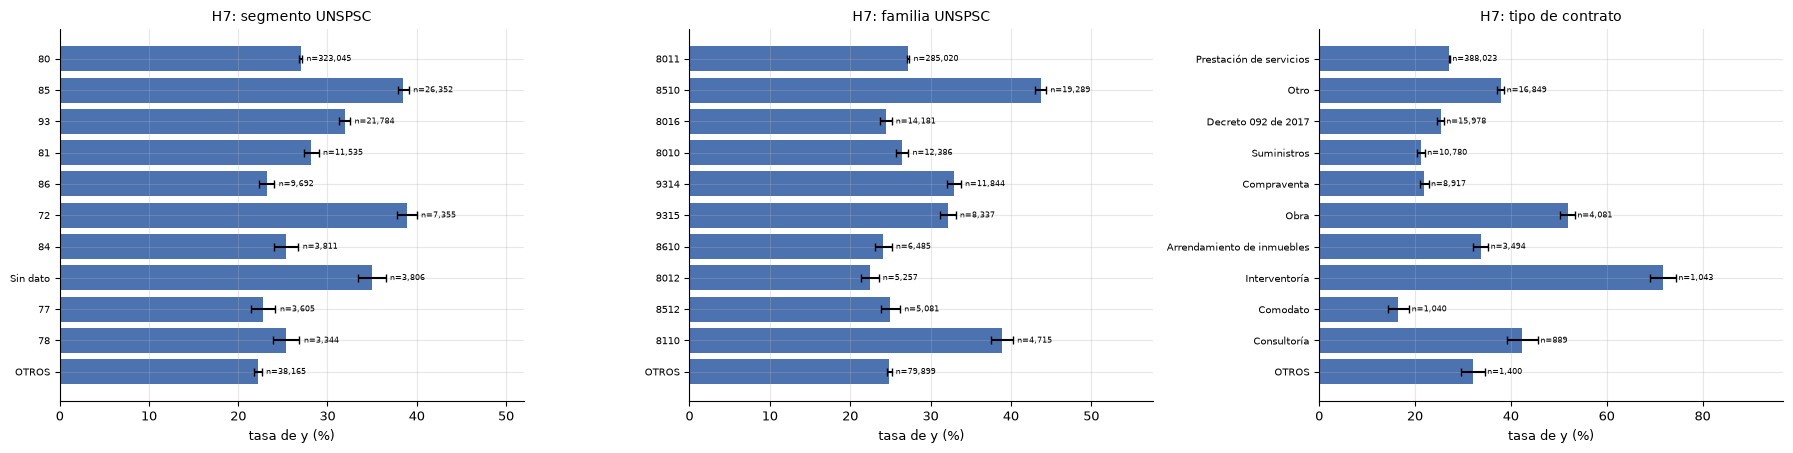

In [35]:
tabla_h7_seg = eda.tasa_top_categorias(Xy, "unspsc_segmento", top=10)
tabla_h7_fam = eda.tasa_top_categorias(Xy, "unspsc_familia", top=10)
tabla_h7_tipo = eda.tasa_top_categorias(Xy, "tipo_de_contrato", top=10)
tabla_h7_len = eda.tasa_por_tramos(
    Xy, "len_objeto",
    bins=[-np.inf, 50, 100, 200, 400, np.inf],
    labels=["<=50", "51-100", "101-200", "201-400", ">400"],
)
mostrar_tabla("6.7.1", "Tasa de y por segmento UNSPSC", eda.tasas_en_pct(tabla_h7_seg).round(2))
mostrar_tabla("6.7.2", "Tasa de y por familia UNSPSC", eda.tasas_en_pct(tabla_h7_fam).round(2))
mostrar_tabla("6.7.3", "Tasa de y por tipo de contrato", eda.tasas_en_pct(tabla_h7_tipo).round(2))
mostrar_tabla("6.7.4", "Tasa de y por longitud del objeto", eda.tasas_en_pct(tabla_h7_len).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
eda.graficar_tasa_por_grupo(
    tabla_h7_seg, col_grupo="unspsc_segmento",
    titulo="H7: segmento UNSPSC", horizontal=True, ax=axes[0],
)
eda.graficar_tasa_por_grupo(
    tabla_h7_fam, col_grupo="unspsc_familia",
    titulo="H7: familia UNSPSC", horizontal=True, ax=axes[1],
)
eda.graficar_tasa_por_grupo(
    tabla_h7_tipo, col_grupo="tipo_de_contrato",
    titulo="H7: tipo de contrato", horizontal=True, ax=axes[2],
)
plt.show()

In [36]:
Xy_tr = Xy[Xy["anio_firma"] <= 2023]
tabla_h7_seg_tr = eda.tasa_top_categorias(Xy_tr, "unspsc_segmento", top=10)
tabla_h7_fam_tr = eda.tasa_top_categorias(Xy_tr, "unspsc_familia", top=10)
tabla_h7_tipo_tr = eda.tasa_top_categorias(Xy_tr, "tipo_de_contrato", top=10)
tabla_h7_len_tr = eda.tasa_por_tramos(
    Xy_tr, "len_objeto",
    bins=[-np.inf, 50, 100, 200, 400, np.inf],
    labels=["<=50", "51-100", "101-200", "201-400", ">400"],
)
mostrar_tabla("6.7.1.b", "Tasa de y por segmento UNSPSC (train 2019-2023)", eda.tasas_en_pct(tabla_h7_seg_tr).round(2))
mostrar_tabla("6.7.2.b", "Tasa de y por familia UNSPSC (train 2019-2023)", eda.tasas_en_pct(tabla_h7_fam_tr).round(2))
mostrar_tabla("6.7.3.b", "Tasa de y por tipo de contrato (train 2019-2023)", eda.tasas_en_pct(tabla_h7_tipo_tr).round(2))
mostrar_tabla("6.7.4.b", "Tasa de y por longitud del objeto (train 2019-2023)", eda.tasas_en_pct(tabla_h7_len_tr).round(2))

**Tabla 6.7.1.b.** Tasa de y por segmento UNSPSC (train 2019-2023)

,unspsc_segmento,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,80,186680,53164,28.48,28.27,28.68
1,85,13544,5457,40.29,39.47,41.12
2,93,12528,4296,34.29,33.46,35.13
3,81,7347,2190,29.81,28.77,30.86
4,86,6077,1561,25.69,24.60,26.80
5,72,4408,1702,38.61,37.18,40.06
6,77,2323,493,21.22,19.61,22.93
7,84,2184,601,27.52,25.69,29.43
8,78,2017,533,26.43,24.55,28.39
9,82,1955,347,17.75,16.12,19.51


**Tabla 6.7.2.b.** Tasa de y por familia UNSPSC (train 2019-2023)

,unspsc_familia,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,8011,162023,46729,28.84,28.62,29.06
1,8510,9672,4432,45.82,44.83,46.82
2,8016,9241,2418,26.17,25.28,27.07
3,8010,8092,2115,26.14,25.19,27.11
4,9314,6946,2268,32.65,31.56,33.76
5,9315,4715,1815,38.49,37.12,39.89
6,8610,4119,1152,27.97,26.62,29.36
7,8012,3471,811,23.37,21.99,24.80
8,8111,2981,645,21.64,20.20,23.15
9,8110,2976,1220,40.99,39.24,42.77


**Tabla 6.7.3.b.** Tasa de y por tipo de contrato (train 2019-2023)

,tipo_de_contrato,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Prestación de servicios,224529,63391,28.23,28.05,28.42
1,Otro,9475,3455,36.46,35.50,37.44
2,Decreto 092 de 2017,8313,2947,35.45,34.43,36.49
3,Suministros,6327,1286,20.33,19.35,21.34
4,Compraventa,5813,1194,20.54,19.52,21.60
5,Obra,2409,1282,53.22,51.22,55.20
6,Arrendamiento de inmuebles,2235,776,34.72,32.77,36.72
7,Interventoría,723,520,71.92,68.54,75.08
8,Comodato,682,127,18.62,15.88,21.72
9,Consultoría,543,246,45.30,41.16,49.51


**Tabla 6.7.4.b.** Tasa de y por longitud del objeto (train 2019-2023)

,len_objeto,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=50,4385,2567,58.54,57.08,59.99
1,51-100,11832,4205,35.54,34.68,36.41
2,101-200,81194,20856,25.69,25.39,25.99
3,201-400,135815,40219,29.61,29.37,29.86
4,>400,28605,7661,26.78,26.27,27.30


**Resultado: confirmada** para H7 (`docs/01_definicion_problema.md`, sección 3). Los segmentos y familias UNSPSC, el tipo de contrato y la longitud del objeto separan tasas: segmento 85 40,3 % frente a 82 17,7 %; interventoría 71,9 % frente a comodato 18,6 %; `len_objeto` <=50 58,5 %.

**Decisión:** `tipo_de_contrato`, `unspsc_segmento`, `unspsc_familia` y `len_objeto` entran en `FEATURES` (`features.FEATURES_CAT`, `features.FEATURES_NUM`); las dos UNSPSC se derivan del código de categoría (`features.construir_features`). Las tres categóricas se codifican con `OrdinalEncoder(max_categories=200)` (`preprocesamiento.construir_preprocesador`); `len_objeto` es numérica cruda (`features.construir_features`) y no se usa el texto crudo del objeto. `len_objeto` se conserva con seguimiento en la evaluación con entidades no vistas: es un indicador indirecto de la entidad (cargos de hospitales), no una fuga (`docs/EDA_INSIGHTS_PREPROCESAMIENTO.md`).

**Alternativas:**
- Excluir `len_objeto` y dejar solo tipo/UNSPSC.
- Usar el texto crudo del objeto.
- Agrupar todos los tipos raros en “Otro” a mano (el `OrdinalEncoder` ya agrupa las categorías infrecuentes en un código).
- Categorías nativas de HGB: descartadas por la explicación SHAP (`resultados/j3_decisiones.md`).

**Por qué:** Tipo y UNSPSC separan tasas muy distintas; `len_objeto` corto se asocia con objetos de personal de hospitales y puede estar capturando la entidad. Es señal disponible al firmar, pero su peso debe revisarse fuera de las entidades vistas.

**Evidencia principal (train 2019–2023):** Tabla 6.7.1.b: segmento 85 40,3 % (n=13.544), 72 38,6 % (n=4.408), 93 34,3 %, 80 28,5 %, 82 17,7 %. Tabla 6.7.2.b: familia 8510 45,8 % (n=9.672), 8110 41,0 %, 9315 38,5 %, 9314 32,7 %, 8011 28,8 %, 8111 21,6 %. Tabla 6.7.3.b: interventoría 71,9 % (n=723), obra 53,2 % (n=2.409), consultoría 45,3 %, prestación de servicios 28,2 % (n=224.529), compraventa 20,5 %, suministros 20,3 %, comodato 18,6 %. Tabla 6.7.4.b: <=50 caracteres 58,5 % (n=4.385), 51–100 35,5 %, 101–200 25,7 %, 201–400 29,6 %, >400 26,8 %.

**Contraste 2019–2025:** Tabla 6.7.1: 72 38,9 %, 85 38,5 %, 80 27,0 %, Otras 22,2 %; **cambia el orden** entre 85 y 72. Tabla 6.7.2: 8510 43,7 %, 8110 38,9 %, 9314 32,9 %, 9315 32,1 %; **cambian de orden 9315 y 9314 y entra 8111 en lugar de 8512**. Tabla 6.7.3: interventoría 71,8 %, obra 51,9 %, prestación de servicios 27,1 %, comodato 16,4 %; **Decreto 092 pasa de -2,3 pp a +6,6 pp** y sube en el orden. Tabla 6.7.4: <=50 58,0 % frente a 201–400 28,2 %; la relación sigue sin ser monótona. La dirección general se mantiene en las cuatro.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 6.7

## 3.3.7 Privacidad del proveedor

**Qué se observa.** El 84,25 % de los contratos tiene proveedor con cédula de ciudadanía, 15,21 % con NIT, 0,16 % "No Definido" y 0,19 % "Otro". La composición cambia fuerte en 2019 (75,55 % cédula / 23,61 % NIT) y se estabiliza desde 2023 (84,56–85,34 % / 14,14–14,98 %). Es decir, más de cuatro de cada cinco contratos tienen un proveedor con cédula, un dato personal.

**Decisión.**
- **Decisión:** excluir la identidad y los datos del proveedor (documento, nombre, `codigo_proveedor`, NIT adjudicado); conservar solo `tipodocproveedor`.
- **Alternativas:** historial de prórrogas del proveedor; identificador cifrado (hash); usar solo personas jurídicas (NIT); excluir.
- **Por qué:** la cédula es dato personal (Ley 1581 de 2012); el hash sigue siendo un dato personal seudonimizado y un puntaje por proveedor se convierte en un ranking de personas. El tipo de documento no identifica.
- **Evidencia:** distribución de `tipodocproveedor` y su evolución por año.
- **Costo:** se pierde una posible señal (historial del proveedor) cuyo tamaño no se midió [NO EVALUADO].


,tipo,n,pct,pct_acumulado
0,Cédula de Ciudadanía,381242,84.25,84.25
1,NIT,68844,15.21,99.47
2,Otro,878,0.19,99.66
3,No Definido,730,0.16,99.82
4,Cédula de Extranjería,607,0.13,99.96
5,Permiso por Protección Temporal,84,0.02,99.98
6,Pasaporte,45,0.01,99.99
7,Tarjeta de Identidad,42,0.01,100.00
8,Permiso especial de permanencia,17,0.00,100.00
9,Registro Civil,5,0.00,100.00


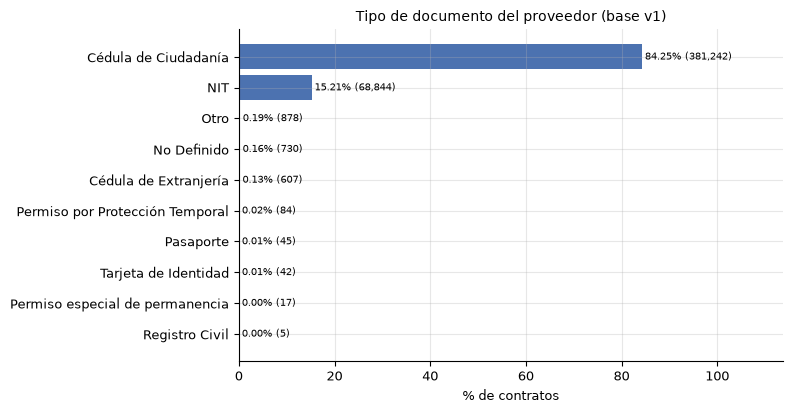

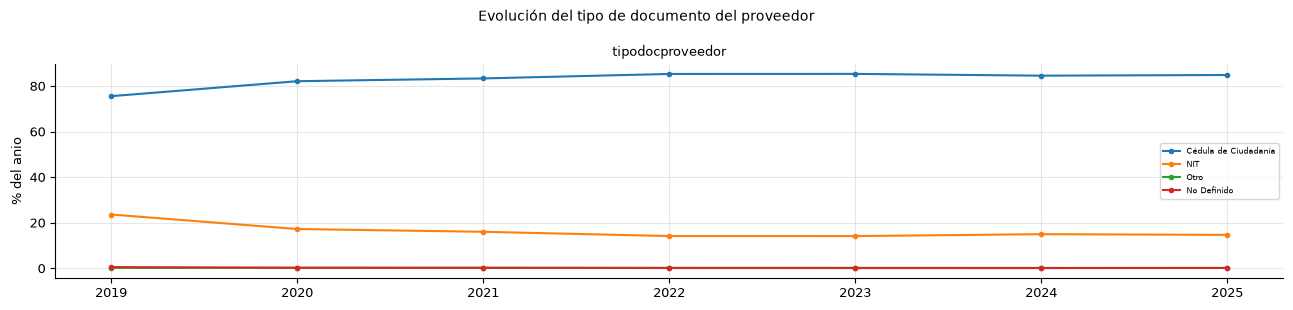

In [37]:
tipo_doc = eda.resumen_tipodocproveedor(base)
display(tipo_doc.round(2))
eda.graficar_tipodocproveedor(tipo_doc, titulo="Tipo de documento del proveedor (base v1)")
plt.show()
eda.graficar_evolucion_categorias(base, ["tipodocproveedor"], top=4, ncols=1,
                                  titulo="Evolución del tipo de documento del proveedor")
plt.show()


### 3.3.7.2 Tasa de y por tipo de documento del proveedor

Se muestra la tasa de `y` por `tipodocproveedor` (Wilson) y su evolución por año. Solo el tipo de documento, nunca la identidad del proveedor.


In [38]:
# 3.3.7.2: solo el tipo de documento; nunca la identidad del proveedor.
tabla_doc = eda.tasas_en_pct(eda.tasa_por_grupo(base, "tipodocproveedor")).round(2)
tabla_doc = tabla_doc.sort_values("n", ascending=False).reset_index(drop=True)
mostrar_tabla("7.2.1", "Tasa de y por tipo de documento", tabla_doc)

evol_doc = (
    base.pivot_table(
        index="tipodocproveedor",
        columns="anio_firma",
        values="y",
        aggfunc="mean",
    ) * 100
).round(2)
evol_doc = evol_doc.loc[tabla_doc["tipodocproveedor"]]
mostrar_tabla("7.2.2", "Tasa de y (%) por tipo de documento y año", evol_doc)


**Tabla 7.2.1.** Tasa de y por tipo de documento

,tipodocproveedor,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Cédula de Ciudadanía,381242,104261,27.35,27.21,27.49
1,NIT,68844,19862,28.85,28.51,29.19
2,Otro,878,270,30.75,27.79,33.88
3,No Definido,730,442,60.55,56.96,64.03
4,Cédula de Extranjería,607,168,27.68,24.27,31.37
5,Permiso por Protección Temporal,84,28,33.33,24.18,43.95
6,Pasaporte,45,6,13.33,6.26,26.18
7,Tarjeta de Identidad,42,6,14.29,6.72,27.84
8,Permiso especial de permanencia,17,4,23.53,9.55,47.26
9,Registro Civil,5,1,20.00,3.62,62.45


**Tabla 7.2.2.** Tasa de y (%) por tipo de documento y año

anio_firma,2019,2020,2021,2022,2023,2024,2025
tipodocproveedor,,,,,,,
Cédula de Ciudadanía,22.85,28.63,27.21,29.31,30.37,23.90,26.67
NIT,18.84,32.23,30.47,29.77,27.52,28.58,29.41
Otro,37.50,35.90,26.67,28.17,29.19,29.73,35.54
No Definido,57.69,60.67,67.24,63.64,54.64,64.89,56.05
Cédula de Extranjería,62.50,24.00,21.95,28.57,29.91,22.58,30.97
Permiso por Protección Temporal,NaN,NaN,0.00,100.00,29.41,40.74,27.03
Pasaporte,0.00,25.00,0.00,7.14,20.00,33.33,50.00
Tarjeta de Identidad,NaN,0.00,28.57,8.33,16.67,0.00,22.22
Permiso especial de permanencia,NaN,NaN,100.00,0.00,16.67,50.00,0.00


In [39]:
# Tabla 7.2.1.b: las categorías con menos de 500 contratos en el train se agrupan en «Otras».
tr = base[base["anio_firma"] <= 2023]
tipodoc = tr["tipodocproveedor"].astype(object)
tipodoc = tipodoc.where(tipodoc.map(tipodoc.value_counts()) >= 500, "Otras")
tabla_doc_tr = (eda.tasas_en_pct(eda.tasa_por_grupo(tr.assign(tipodoc_agrupado=tipodoc), "tipodoc_agrupado")).round(2)
                .rename(columns={"tipodoc_agrupado": "tipodocproveedor"}))
mostrar_tabla("7.2.1.b", "Tasa de y por tipo de documento (train 2019-2023)",
              tabla_doc_tr.sort_values("n", ascending=False).reset_index(drop=True))

**Tabla 7.2.1.b.** Tasa de y por tipo de documento (train 2019-2023)

,tipodocproveedor,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Cédula de Ciudadanía,219724,63263,28.79,28.60,28.98
1,NIT,40593,11663,28.73,28.29,29.17
2,Otras,950,415,43.68,40.56,46.86
3,Otro,564,167,29.61,25.99,33.51


**Decisión:** Conservar solo `tipodocproveedor` como feature categórica (`features.FEATURES_CAT`), codificada con `OrdinalEncoder(max_categories=200)` en la familia `arbol` (`preprocesamiento.construir_preprocesador`); excluir la identidad y los datos del proveedor (documento, nombre, código, NIT adjudicado).

**Alternativas:**
- Incluir el historial de prórrogas del proveedor.
- Usar un identificador cifrado o hash.
- Usar el proveedor solo para personas jurídicas (NIT).

**Por qué:** La cédula de ciudadanía domina la muestra y es un dato personal; un puntaje por proveedor se convertiría en un ranking de personas. El tipo de documento no identifica al proveedor y las diferencias entre cédula y NIT son pequeñas (28,8 % vs 28,7 % en train).

**Evidencia principal (train 2019–2023):** Tabla 7.2.1.b (n = 261.831; y = 28,8 %): cédula de ciudadanía `y` 28,8 % (n=219.724), NIT `y` 28,7 % (n=40.593), Otro `y` 29,6 % (n=564), Otras `y` 43,7 % (n=950).

**Contraste 2019–2025:** Tabla 7.2.1: cédula de ciudadanía 84,3 % (n=381.242) con `y` 27,3 %; NIT 15,2 % (n=68.844) con 28,9 %; No Definido 0,2 % (n=730) con 60,5 %. **Cambia la comparación**: en train NIT y cédula quedan casi iguales (28,7 % vs 28,8 %), mientras que en 2019–2025 el NIT está 1,6 pp por encima; `Otras` mezcla No Definido y Cédula de Extranjería, así que su 43,7 % no es comparable. Tabla 7.2.2: las tasas anuales de las categorías pequeñas son inestables; “Otras” pasa de 0,0 % (n=2) en 2019 a 26,9 % (n=52) en 2025.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 7.2

## 3.3.8 Fuga de información

La lista de columnas de fuga y su estado está en `docs/LISTA_FUGA.md`. La medición con modelo (ROC-AUC con y sin fuga) está en 3.6, en el contraste «con fuga». Aquí solo hay comprobaciones descriptivas: la tasa de `y` por `estado_contrato` (Tabla 8.1) y el ROC-AUC univariado de cada candidato de fuga (Tabla 8.2). Ninguna entra como feature.


In [40]:
# Lectura de solo lectura del crudo de Contratos; no se escribe nada ni entra en la base ni en FEATURES.
RUTA_CONTRATOS = config.DATA_RAW / "f2" / "contratos"
MONTOS = ["presupuesto_general_de_la_nacion_pgn", "sistema_general_de_participaciones", "sistema_general_de_regal_as",
          "recursos_propios_alcald_as_gobernaciones_y_resguardos_ind_genas_", "recursos_de_credito", "recursos_propios"]
COLS_CRUDO = ["id_contrato", "estado_contrato", "valor_del_contrato", "el_contrato_puede_ser_prorrogado", "dias_adicionados",
              "fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato", *MONTOS]
crudo = (pd.concat([pd.read_parquet(f, columns=COLS_CRUDO) for f in sorted(RUTA_CONTRATOS.rglob("*.parquet"))],
                   ignore_index=True)
         .drop_duplicates(subset="id_contrato"))          # 21 copias exactas
for c in ["valor_del_contrato", "dias_adicionados", *MONTOS]:
    crudo[c] = pd.to_numeric(crudo[c], errors="coerce")
for c in ["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato"]:
    crudo[c] = pd.to_datetime(crudo[c], errors="coerce", format="ISO8601").dt.normalize()
crudo["fin_dias"] = (crudo["fecha_de_fin_del_contrato"] - crudo["fecha_de_firma"]).dt.days
crudo["dur_contrato_dias"] = (crudo["fecha_de_fin_del_contrato"] - crudo["fecha_de_inicio_del_contrato"]).dt.days
crudo["recursos_suma"] = crudo[MONTOS].sum(axis=1)

base_estado = base[["id_contrato", "y"]].merge(
    crudo[["id_contrato", "estado_contrato"]], on="id_contrato", how="left", validate="one_to_one"
)
tabla_estado = eda.tasas_en_pct(eda.tasa_por_grupo(base_estado, "estado_contrato")).round(2)
mostrar_tabla("8.1", "Tasa de y por estado actual del contrato",
              tabla_estado.sort_values("n", ascending=False).reset_index(drop=True))
print("Contratos con estado_contrato:", int(base_estado["estado_contrato"].notna().sum()), "de", len(base_estado))

**Tabla 8.1.** Tasa de y por estado actual del contrato

,estado_contrato,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Cerrado,166839,42613,25.54,25.33,25.75
1,En ejecución,118069,353,0.30,0.27,0.33
2,Modificado,81391,62574,76.88,76.59,77.17
3,terminado,73006,18988,26.01,25.69,26.33
4,Aprobado,10997,21,0.19,0.12,0.29
5,cedido,1802,267,14.82,13.25,16.53
6,Suspendido,383,232,60.57,55.60,65.34
7,enviado Proveedor,5,0,0.00,-0.00,43.45
8,En aprobación,2,0,0.00,0.00,65.76


Contratos con estado_contrato: 452494 de 452494


In [41]:
from sklearn.metrics import roc_auc_score

# Modificaciones: se quitan las copias exactas y se agrega por contrato.
mod = (pd.concat([pd.read_parquet(f, columns=["id_contrato", "identificador_modificacion", "dias_extendidos",
                                              "fecha_de_aprobacion", "fecha_fin_contrato"])
                  for f in sorted((config.DATA_RAW / "f2" / "modificaciones").glob("lote_*.parquet"))], ignore_index=True)
       .drop_duplicates())
mod["dias_extendidos"] = pd.to_numeric(mod["dias_extendidos"], errors="coerce")
for c in ["fecha_de_aprobacion", "fecha_fin_contrato"]:
    mod[c] = pd.to_datetime(mod[c], errors="coerce", format="ISO8601").dt.normalize()
firma = base.set_index("id_contrato")["fecha_de_firma"]
mod["aprobacion_dias"] = (mod["fecha_de_aprobacion"] - mod["id_contrato"].map(firma)).dt.days
mod["fin_dias_mod"] = (mod["fecha_fin_contrato"] - mod["id_contrato"].map(firma)).dt.days
agg_mod = mod.groupby("id_contrato").agg(
    mod_n=("identificador_modificacion", "size"), mod_dias_ext_sum=("dias_extendidos", "sum"),
    mod_aprobacion_max_dias=("aprobacion_dias", "max"), mod_fin_max_dias=("fin_dias_mod", "max"),
).reset_index()

# Tabla de trabajo: base v1 + columnas del crudo + agregados de Modificaciones. Solo en memoria.
df_fuga = base[["id_contrato", "y", "y_dias", "anio_firma", "p_precio_base"]].copy()
df_fuga["p_dur_dias"] = X["p_dur_dias"]
df_fuga = df_fuga.merge(
    crudo.drop(columns=["fecha_de_firma", "fecha_de_inicio_del_contrato", "fecha_de_fin_del_contrato"]),
    on="id_contrato", how="left", validate="one_to_one",
).merge(agg_mod, on="id_contrato", how="left")
df_fuga["razon_dur"] = np.where(
    df_fuga["p_dur_dias"].between(1, 3650) & df_fuga["dur_contrato_dias"].between(1, 3650),
    df_fuga["dur_contrato_dias"] / df_fuga["p_dur_dias"], np.nan)
df_fuga["razon_valor"] = np.where(
    df_fuga["p_precio_base"].gt(0), df_fuga["valor_del_contrato"] / df_fuga["p_precio_base"], np.nan)
for c in ["mod_n", "mod_dias_ext_sum", "mod_aprobacion_max_dias"]:
    df_fuga[c] = df_fuga[c].fillna(0)
df_fuga["mod_fin_max_dias"] = df_fuga[["mod_fin_max_dias", "fin_dias"]].max(axis=1)


def auc_num(df, col, y):
    x = df[[col, y]].dropna()
    return (float(roc_auc_score(x[y], x[col])), len(x)) if len(x) and x[col].nunique() > 1 else (np.nan, len(x))


def auc_cat(df, col, y):                       # el puntaje es la tasa de y de cada categoría, en la misma muestra
    x = df[[col, y]].dropna()
    tasas = x.groupby(col)[y].mean()
    return (float(roc_auc_score(x[y], x[col].map(tasas))), len(x)) if len(x) and x[col].nunique() > 1 else (np.nan, len(x))


def fmt_auc(v):
    return "-" if pd.isna(v) else f"{v:.4f}" if abs(v) > 0.999 else f"{v:.3f}"


candidatos = [
    ("estado_contrato", "categórica", auc_cat, "estado actual del contrato"),
    ("fin_dias", "días desde la firma", auc_num, "fecha de fin actual; incluye ampliaciones"),
    ("dur_contrato_dias", "numérica", auc_num, "fin - inicio"),
    ("razon_dur", "cociente", auc_num, "duración real / planeada, ambas entre 1 y 3.650 días"),
    ("valor_del_contrato", "numérica", auc_num, "valor actual; incluye adiciones"),
    ("razon_valor", "cociente", auc_num, "valor actual / precio base, con precio base > 0"),
    ("recursos_suma", "numérica", auc_num, "suma de las 6 fuentes de recursos"),
    ("el_contrato_puede_ser_prorrogado", "categórica", auc_cat, "campo editable después de la firma"),
    ("dias_adicionados", "numérica", auc_num, "componente de y_dias: AUC 1 frente a y_dias por construcción"),
    ("mod_n", "conteo", auc_num, "cuasi-etiqueta: Modificaciones ya viene filtrada a extensiones publicadas"),
    ("mod_dias_ext_sum", "numérica", auc_num, "cuasi-etiqueta"),
    ("mod_aprobacion_max_dias", "días desde la firma", auc_num, "cuasi-etiqueta; 0 si no hay modificación"),
    ("mod_fin_max_dias", "días desde la firma", auc_num, "máximo entre el fin en Modificaciones y el fin actual"),
]
filas = []
for var, tipo, f, nota in candidatos:
    a_y, n = f(df_fuga, var, "y")
    a_d, _ = f(df_fuga, var, "y_dias")
    filas.append({"variable": var, "tipo": tipo, "n": n, "AUC vs y": fmt_auc(a_y), "AUC vs y_dias": fmt_auc(a_d), "nota": nota})
with pd.option_context("display.max_colwidth", 80):
    mostrar_tabla("8.2", "ROC-AUC univariado de cada candidato de fuga", pd.DataFrame(filas))
print("Descriptivo: sin train/test ni modelo, no es una métrica de validación. Las demás columnas de la lista de fuga "
      "(pagos, saldos, liquidación, estados del proceso) no se descargaron; ver docs/LISTA_FUGA.md.")

**Tabla 8.2.** ROC-AUC univariado de cada candidato de fuga

,variable,tipo,n,AUC vs y,AUC vs y_dias,nota
0,estado_contrato,categórica,452494,0.820,0.943,estado actual del contrato
1,fin_dias,días desde la firma,452489,0.744,0.707,fecha de fin actual; incluye ampliaciones
2,dur_contrato_dias,numérica,448436,0.741,0.704,fin - inicio
3,razon_dur,cociente,421304,0.952,0.885,"duración real / planeada, ambas entre 1 y 3.650 días"
4,valor_del_contrato,numérica,452494,0.675,0.652,valor actual; incluye adiciones
5,razon_valor,cociente,448638,0.810,0.748,"valor actual / precio base, con precio base > 0"
6,recursos_suma,numérica,452494,0.657,0.639,suma de las 6 fuentes de recursos
7,el_contrato_puede_ser_prorrogado,categórica,452494,0.563,0.551,campo editable después de la firma
8,dias_adicionados,numérica,452494,0.741,1.0000,componente de y_dias: AUC 1 frente a y_dias por construcción
9,mod_n,conteo,452494,0.9996,0.931,cuasi-etiqueta: Modificaciones ya viene filtrada a extensiones publicadas


Descriptivo: sin train/test ni modelo, no es una métrica de validación. Las demás columnas de la lista de fuga (pagos, saldos, liquidación, estados del proceso) no se descargaron; ver docs/LISTA_FUGA.md.


**Decisión:** Excluir de `FEATURES` las columnas de fuga confirmada y los agregados de Modificaciones (`features.COLUMNAS_FUGA`); `estado_contrato` se usa solo para EDA, no como feature ni como respaldo. `el_contrato_puede_ser_prorrogado` sigue fuera de `FEATURES` por la decisión de `docs/PLAN.md` (`features.FEATURES_EXCLUIDAS`); la ablación de 3.6 la respalda (agregarla mueve el PR-AUC 2024 en −0,0010, dentro del ruido; `resultados/j3_decisiones.md`).

**Alternativas:**
- Incluir `estado_contrato` con regularización.
- Usar las columnas solo para evaluación o para definir la etiqueta.
- Incluir los agregados de Modificaciones como features.

**Por qué:** Esas columnas contienen hechos posteriores a la firma; su AUC alto es consistente con fuga, no con señal utilizable al firmar. El AUC baja de 0,943 con `y_dias` a 0,820 con `y` porque cambió la etiqueta, no porque deje de ser fuga: “Modificado” tiene 76,9 % de positivos frente a 0,3 % de “En ejecución”, es decir, el estado se actualiza con el desenlace.

**Evidencia:** Tabla 8.1 (2019–2025): “Modificado” 76,9 % de `y` (n=81.391) frente a “En ejecución” 0,3 % (n=118.069) y “Aprobado” 0,2 % (n=10.997). Tabla 8.2: `estado_contrato` AUC 0,820 vs `y` y 0,943 vs `y_dias`; `razon_dur` 0,952; `mod_n` 0,9996; `dias_adicionados` 1,0000 vs `y_dias`.

**Cadena de fuga del modelo:** con el HGB limpio, ROC-AUC 0,781 → 0,917 → 0,984 y PR-AUC 0,584 → 0,851 → 0,967: el primer salto agrega los 6 montos del crudo de Contratos y el segundo la fuga evidente (estado, valor y fecha de fin). Cifras en `resultados/j3_extra_fuga_montos.csv` (filas `final_limpio`, `final_con_6_montos`, `final_con_fuga_evidente`) y en `resultados/j3_decisiones.md`.

**Cautela:** Los AUC de la Tabla 8.2 son descriptivos, no una métrica de validación; no hay train/test ni modelo en esa sección. La cadena de fuga es un contraste sobre la base v1_A con el crudo de Contratos unido por `id_contrato` solo para medir; esas columnas no entran en la base ni en `FEATURES`.

Detalle y trazabilidad al código: docs/eda_interpretaciones.md, sección 8

## 3.3.9 Resumen de decisiones

| ID | Decisión | Alternativas | Por qué | Qué quedó en v1 | Evidencia |
| --- | --- | --- | --- | --- | --- |
| D2.1 | Imputar en el Pipeline con mediana/moda + indicadores de bloque | Borrar filas; imputar con 0 | Faltantes bajos y en bloque; borrar sesga | Aplicada solo en distancia: el HGB deja los NaN y los maneja de forma nativa | 349 sin proceso, 4.059 sin inicio, 799 sin duración, 3.806 sin UNSPSC |
| D2.2 | Duración ≤0 → faltante y recorte [1, 3.650]; precio negativo → flag | Dejar crudo; borrar outliers | 5,43 % de duraciones no positivas y colas de 4.078,9 M | Cambió: ≤0 → NaN + indicador `p_dur_dias_cero`; recorte al p99,9 del train (1.259 días), no 3.650; el precio negativo se recorta a 0 con `clip(lower=0)` en `log_precio_base`, sin indicador (no se distingue de un precio base 0 real) | 24.566 ≤0, 125 >3.650, 10 precios negativos |
| D2.3 | Agrupar raras <1 % en `OTROS`; HGB nativo/tope; `nit_entidad` con TargetEncoder | One-hot completo; dejar texto | Cardinalidad alta y 76,59 % de filas en entidades con <1 % | Cambió: `OrdinalEncoder` (top 200) sin categorías nativas, por SHAP; `nit_entidad` con `TargetEncoder`; `OTROS` <1 % solo en distancia | 3.034 entidades, 735 ciudades |
| D2.4 | Eliminar constantes/redundantes | Mantener las 18 numéricas | Duplican la misma señal | Aplicada: la constante se descarta; los redundantes se quitan solo en distancia | 1 constante (`p_proveedores_que_manifestaron`), 99,74 %/99,56 % iguales (filas con proceso), r 0,994/0,992 |
| D3.1 | `log1p` en conteos + `RobustScaler` para kNN/SVM; crudo para HGB | Estandarizar sin log | Zero-inflación y colas largas | Aplicada | 90,4–99,8 % ceros en competencia |
| D3.2 | No usar el año como feature; ajustar solo con train | Usar año; mezclar train/test | Deriva fuerte 2019→2025 | Aplicada | Composición y competencia cambian |
| D3.3 | Quitar redundantes para kNN/SVM; mantener para HGB | PCA | Colinealidad duplica peso | Aplicada | r 0,994 y 0,992 |
| D3.4 | Calendario: flag de trimestre + mes cíclico o uno solo para distancia | Mes ordinal | `mes_firma` y el flag correlacionan 0,695–0,722 | Cambió: `mes_firma` y el flag de trimestre se conservan en ambas familias (HGB: mes entero 1–12; distancia: mes cíclico) | r = 0,695/0,722 |
| D4.1 | Entrenar/evaluar solo maduros; `eval_*` nunca como feature | Usar todos | 99,2 % maduro; 3.455 inmaduros | Aplicada | Madurez 97,64–99,99 % por año |
| D7.1 | Excluir identidad del proveedor; conservar solo el tipo de documento | Hash; historial; solo NIT | 84,25 % de los contratos tiene proveedor con cédula | Aplicada | Distribución `tipodocproveedor` |

**Hipótesis (3.3.6):** H3, H6 y H7 confirmadas; H1 parcial; H2, H4 y H5 en sentido contrario al planteado.

Las decisiones de 3.3.4.3, 3.3.5, 3.3.6 (H1–H7), 3.3.7.2 y 3.3.8 están en cada sección y en `docs/eda_interpretaciones.md`. El detalle para el preprocesamiento está en `docs/EDA_INSIGHTS_PREPROCESAMIENTO.md`.

In [42]:
# Fin de 3.3: se restauran el estilo de las gráficas y el formato de los decimales.
plt.rcParams.update(RC_PREVIO)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# 3.4 Paradigma y 3.5 Metodología y selección del modelo


**Paradigma (3.4):** aprendizaje supervisado, clasificación binaria. Al momento de la firma se estima la probabilidad de que el contrato termine con el plazo ampliado (`y`). Hay etiqueta histórica para 2019-2025 y la decisión del usuario es ordenar contratos para revisarlos, así que un modelo que puntúa y ordena es lo que se necesita.

**Metodología (3.5):**
- Split temporal: train 2019-2023, test 2024 y 2025 como deriva. Solo contratos maduros.
- Dentro del train, folds temporales de ventana creciente: se entrena con los años anteriores y se valida en 2021, 2022 y 2023.
- Cinco modelos del curso, con búsqueda aleatoria de hiperparámetros sobre esos folds y un tope de 15 minutos por modelo. kNN y SVM sobre una submuestra de 20.000 contratos.
- Métrica de selección: PR-AUC medio de los folds. El test 2024 no se usa para elegir.

In [43]:
busq = json.loads((RES / "j3_busqueda_resumen.json").read_text(encoding="utf-8"))
j3 = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))

## Folds temporales

**Decisión:** validación con ventana creciente y no `KFold` aleatorio.
- **Por qué:** el modelo se va a usar con contratos futuros, y el SECOP II cambió mucho entre años (más contratación directa, más personas naturales). Un fold aleatorio mezclaría años y daría una estimación optimista.
- **Evidencia:** la tasa de positivos sube de 0,273 en el train del primer fold a 0,300 en la validación de 2023, y en el test 2024 baja a 0,247.

In [44]:
an, y = base.loc[idx_tr, "anio_firma"].to_numpy(), base.loc[idx_tr, "y"].to_numpy()
pd.DataFrame([{"validación": int(an[v][0]), "años de train": f"{an[t].min()}-{an[t].max()}", "n train": len(t),
               "tasa train": y[t].mean(), "n validación": len(v), "tasa validación": y[v].mean()}
              for t, v in E.folds_temporales(an)])

,validación,años de train,n train,tasa train,n validación,tasa validación
0,2021,2019-2020,50482,0.273,56370,0.278
1,2022,2019-2021,106852,0.276,70899,0.295
2,2023,2019-2022,177751,0.283,83498,0.300


## Las reglas simples que hay que superar

- **Tasa base:** el mismo puntaje para todos.
- **Tasa histórica por entidad:** (positivos + m · p0) / (contratos + m); las entidades nuevas reciben p0. El suavizado `m` se elige con los mismos folds temporales: entre los `m` a menos de 0,005 del mejor ROC-AUC, gana el de mejor precisión en el top-k. Con m = 0 el top 1 % se llena de entidades con 1 de 1 positivos.

In [45]:
tm = pd.read_csv(RES / "j1_v1_elegir_m.csv")
display(tm.style.format(precision=4).apply(lambda r: ["background-color: #dbe9f6" if r["elegida"] else "" for _ in r], axis=1))

,m,roc_auc,pr_auc,p@1%,p@5%,p@10%,p_topk_media,elegida
0,0,0.6642,0.4838,0.7366,0.7310,0.6115,0.6931,False
1,1,0.6637,0.4868,0.7769,0.7375,0.6153,0.7099,False
2,2,0.6631,0.4877,0.7798,0.7536,0.6159,0.7164,False
3,5,0.6617,0.4885,0.7798,0.7608,0.6307,0.7238,False
4,10,0.6604,0.4883,0.7798,0.7643,0.6340,0.7260,True
5,20,0.6589,0.4882,0.7798,0.7658,0.6403,0.7287,False
6,50,0.6558,0.4873,0.7798,0.7675,0.6425,0.7299,False
7,100,0.6531,0.4862,0.7798,0.7701,0.6475,0.7325,False


## Búsqueda de hiperparámetros

,n_train,n_iter,segundos,pr_auc_cv,pr_auc_cv_std,roc_auc_cv
rf,"261,249",12,300,0.5781,0.0130,0.7567
hgb,"261,249",25,287,0.5765,0.0046,0.7620
arbol,"261,249",30,51,0.5318,0.0104,0.7321
svm,"20,000",10,45,0.5225,0.0407,0.6904
knn,"20,000",15,17,0.5169,0.0471,0.6925


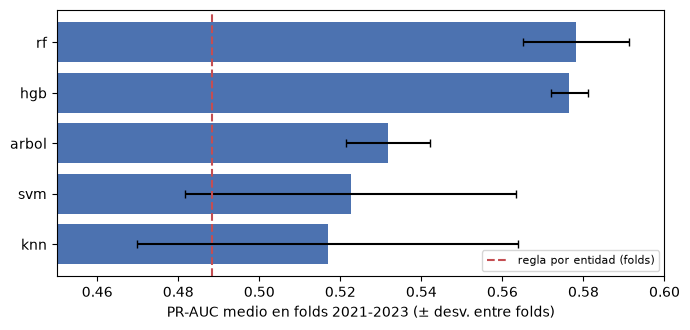

hgb    {'l2_regularization': 0.002259279742015696, 'learning_rate': 0.034003508264422166, 'max_features': 0.5, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}
arbol  {'min_samples_leaf': 200, 'max_depth': 12, 'criterion': 'entropy', 'class_weight': None}
rf     {'n_estimators': 400, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': None}
knn    {'weights': 'distance', 'p': 1, 'n_neighbors': 100}
svm    {'C': 1.5751320499779735, 'gamma': 0.01}


In [46]:
t = pd.DataFrame(busq).T[["n_train", "n_iter", "segundos", "pr_auc_cv", "pr_auc_cv_std", "roc_auc_cv"]].astype(float)
t = t.sort_values("pr_auc_cv", ascending=False)
display(t.style.format({"n_train": "{:,.0f}", "n_iter": "{:.0f}", "segundos": "{:.0f}", "pr_auc_cv": "{:.4f}",
                        "pr_auc_cv_std": "{:.4f}", "roc_auc_cv": "{:.4f}"}))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(t.index[::-1], t["pr_auc_cv"][::-1], xerr=t["pr_auc_cv_std"][::-1], color="#4C72B0", capsize=3)
ax.axvline(tm.loc[tm["elegida"], "pr_auc"].iloc[0], color="#C44E52", ls="--", label="regla por entidad (folds)")
ax.set_xlim(0.45, 0.6); ax.set_xlabel("PR-AUC medio en folds 2021-2023 (± desv. entre folds)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
for k, v in busq.items():
    print(f"{k:6s} {v['mejores_parametros']}")

**Interpretación:** los dos ensambles de árboles (HGB y RF) quedan arriba y prácticamente empatados (0,5765 y 0,5781). El árbol solo, kNN y SVM quedan claramente por debajo; kNN y SVM además se entrenaron con 20.000 contratos y varían mucho entre folds. Todas las búsquedas terminaron dentro del tope de 15 minutos.

**Decisión: el modelo final es el HGB.**
- **Alternativas:** Random Forest, que tiene un PR-AUC medio un poco mayor.
- **Por qué:** la diferencia (0,0016) es menor que la desviación entre folds del RF (0,013), así que están empatados. El HGB es más estable entre folds (desviación de 0,0046), pesa unos 3 MB y tiene `decision_function`, que la app usa para verificar que los valores SHAP suman la salida del modelo.
- **Evidencia:** tabla y gráfica de arriba. Early stopping desactivado (regla 4).

## Categorías nativas frente a códigos ordinales (HGB, mismos hiperparámetros)

In [47]:
nat = pd.DataFrame({k: {"PR-AUC cv": v["pr_auc_cv"], "ROC-AUC cv": v["roc_auc_cv"], "PR-AUC por fold (2021, 2022, 2023)": v["pr_auc_por_fold"]}
                    for k, v in j3["nativas_vs_ordinal"].items()}).T
display(nat)

,PR-AUC cv,ROC-AUC cv,"PR-AUC por fold (2021, 2022, 2023)"
ordinal,0.576,0.762,"[0.5809, 0.5783, 0.5702]"
nativas,0.580,0.765,"[0.586, 0.5772, 0.5762]"


**Decisión:** códigos ordinales (opción b de `docs/PLAN.md`, sección 0, punto 7).
- **Por qué:** las nativas ganan +0,003 de PR-AUC medio y no en todos los folds (pierden en 2022); con ellas SHAP no es confiable y la app no explicaría. Se gana explicabilidad exacta a cambio de una diferencia que está dentro del ruido.
- **Evidencia:** tabla de arriba; error de aditividad de SHAP de 7e-13 con los códigos (sección 3.6).

## El modelo final

`src/modelo.py: construir_pipeline()` devuelve el `Pipeline` del modelo v1 sin ajustar (lo usa también el monitoreo de la sección 3.9). Se entrena con 2019-2023 y se guarda en `models/modelo_prorroga_v1.joblib` con su `.json`.

In [48]:
from src import modelo_io
pipe, meta = modelo_io.cargar_modelo(config.MODELS / "modelo_prorroga_v1.joblib")
print(meta["version"], "|", meta["modelo"]["clase"], "| categorías nativas:", meta["modelo"]["categorias_nativas"])
print("Hiperparámetros:", meta["modelo"]["hiperparametros"])
print("Train:", meta["datos"]["anios_train"], f"{meta['datos']['n_train']:,} contratos, tasa {meta['datos']['tasa_base_train']}")
pipe

v1.0 | HistGradientBoostingClassifier | categorías nativas: False
Hiperparámetros: {'early_stopping': False, 'l2_regularization': 0.002259279742015696, 'learning_rate': 0.034003508264422166, 'max_features': 0.5, 'max_iter': 200, 'max_leaf_nodes': 127, 'min_samples_leaf': 20}
Train: [2019, 2023] 261,249 contratos, tasa 0.2887


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](39,)","['tipo_de_contrato','modalidad_de_contratacion', 'justificacion_modalidad_de',...,'p_respuestas_externas', 'p_conteo_de_respuestas_a_ofertas','p_proveedores_unicos_con']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,39
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('dur', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature nam

### Entrenamiento paso a paso y verificación contra el artefacto

**Decisión:** entrenar el modelo final en el notebook, en memoria, y comparar sus predicciones de 2024 con las del artefacto `models/modelo_prorroga_v1.joblib`.
- **Alternativas:** cargar el artefacto sin entrenar; reentrenar y sobrescribirlo.
- **Por qué:** el artefacto es lo que usa la app. Si el entrenamiento del notebook reproduce sus predicciones, queda demostrado que sale de este código, de esta base y de la semilla 42, y no de algo que no se ve aquí. No se sobrescribe `models/`: está congelado y las cifras de 3.6 a 3.9 dependen de él.
- **Evidencia:** la celda siguiente.

In [49]:
pipe_nuevo = MO.construir_pipeline().fit(Xtr, ytr)          # 2019-2023 (maduros), solo en memoria
p_nuevo = pipe_nuevo.predict_proba(X.loc[idx_te])[:, 1]
p_artefacto = pipe.predict_proba(X.loc[idx_te])[:, 1]
print(f"Entrenado con {len(Xtr):,} contratos de 2019-2023; predice {len(idx_te):,} de 2024")
print("Predicciones iguales a las del artefacto (np.allclose):", np.allclose(p_nuevo, p_artefacto))
print(f"Diferencia máxima: {np.abs(p_nuevo - p_artefacto).max():.1e}")

Entrenado con 261,249 contratos de 2019-2023; predice 88,088 de 2024
Predicciones iguales a las del artefacto (np.allclose): True
Diferencia máxima: 0.0e+00


**Interpretación:** el modelo entrenado aquí da las mismas predicciones que el artefacto (diferencia máxima 0). El artefacto se puede regenerar con `python -m src.modelo`, que sí lo sobrescribe y por eso el notebook no lo ejecuta.

# 3.6 Generalización


**Qué pide el enunciado:** mostrar que el modelo funciona con datos que no vio, sin sobreajuste ni fuga.

**Cómo:** test 2024 (los hiperparámetros ya estaban elegidos con los folds), deriva 2025, entidades que no estaban en el train, ablación de las features con riesgo de fuga y SHAP global enlazado a las hipótesis H1-H7. Los intervalos son IC 95 % con bootstrap **por entidad** (200 repeticiones): los contratos de una misma entidad están correlacionados y remuestrear contratos daría intervalos demasiado estrechos.

> Nota honesta: durante el desarrollo se miró 2024 como control de cordura (reproducir las cifras de la exploración inicial y probar el `Pipeline`). Ninguna elección de hiperparámetros, features o modelo se hizo con esas cifras.

In [50]:
j3 = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))
modelos = pd.read_csv(RES / "j3_test2024_modelos.csv")

def tabla(t, metricas, nombres=None):
    t = t[t["metrica"].isin(metricas)].copy()
    t["valor [IC]"] = [f"{a:.3f} [{b:.3f}, {c:.3f}]" for a, b, c in zip(t["valor"], t["ic_inf"], t["ic_sup"])]
    t["dif. vs regla [IC]"] = [f"{a:+.3f} [{b:+.3f}, {c:+.3f}]" for a, b, c in zip(t["dif"], t["dif_ic_inf"], t["dif_ic_sup"])]
    out = t.pivot(index="modelo", columns="metrica", values=["valor [IC]", "dif. vs regla [IC]"])
    return out.reindex(nombres) if nombres else out

## Test 2024

In [51]:
orden = ["regla_base", "regla_entidad", "hgb", "rf", "arbol", "svm", "knn"]
display(tabla(modelos, ["pr_auc", "roc_auc"], orden))
print("Criterio de aceptación (IC de la diferencia de PR-AUC contra la regla excluye 0):", j3["criterio_aceptacion_final"])

valor [IC]                             dif. vs regla [IC]                         
metrica                      pr_auc               roc_auc                   pr_auc                  roc_auc
modelo                                                                                                     
regla_base     0.247 [0.215, 0.285]  0.500 [0.500, 0.500]  -0.223 [-0.292, -0.129]  -0.182 [-0.226, -0.128]
regla_entidad  0.470 [0.355, 0.562]  0.682 [0.628, 0.726]  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]
hgb            0.584 [0.488, 0.659]  0.781 [0.752, 0.807]  +0.114 [+0.082, +0.158]  +0.099 [+0.067, +0.130]
rf             0.580 [0.481, 0.657]  0.779 [0.748, 0.806]  +0.110 [+0.081, +0.148]  +0.097 [+0.067, +0.125]
arbol          0.537 [0.441, 0.616]  0.751 [0.721, 0.782]  +0.067 [+0.036, +0.113]  +0.070 [+0.039, +0.100]
svm            0.523 [0.404, 0.613]  0.730 [0.689, 0.766]  +0.053 [+0.030, +0.085]  +0.048 [+0.033, +0.070]
knn            0.509 [0.392, 0.604]  0.719 [0.678, 0.754]  +0.039 [+0.015, +0.065]  +0.037 [+0.014, +0.060]

Criterio de aceptación (IC de la diferencia de PR-AUC contra la regla excluye 0): True


**Interpretación:** el HGB llega a 0,584 de PR-AUC frente a 0,470 de la regla por entidad (+0,114, IC [+0,082; +0,158]) y 0,247 de la tasa base, así que cumple el criterio de aceptación del plan. Las cifras de 2024 son parecidas a las de los folds (0,577), señal de que la búsqueda no sobreajustó la validación. Los cinco modelos le ganan a la regla, pero solo los ensambles lo hacen por un margen amplio.

## Deriva 2025

- (i) El **mismo modelo** entrenado con 2019-2023, evaluado en 2025.
- (ii) El modelo **reentrenado** con 2019-2024, evaluado en 2025.

In [52]:
der = pd.read_csv(RES / "j3_deriva_2025.csv")
print(f"2025: {j3['deriva_2025']['n']:,} contratos maduros, tasa base {j3['deriva_2025']['tasa_base']:.3f}")
display(tabla(der, ["pr_auc", "roc_auc"], ["regla_base", "regla_entidad", "final_2019_2023", "regla_entidad_2019_2024", "final_2019_2024"]))

2025: 99,702 contratos maduros, tasa base 0.271


valor [IC]                             dif. vs regla [IC]                         
metrica                                pr_auc               roc_auc                   pr_auc                  roc_auc
modelo                                                                                                               
regla_base               0.271 [0.243, 0.305]  0.500 [0.500, 0.500]  -0.194 [-0.253, -0.131]  -0.156 [-0.191, -0.124]
regla_entidad            0.465 [0.385, 0.540]  0.656 [0.624, 0.691]  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]
final_2019_2023          0.550 [0.472, 0.642]  0.773 [0.747, 0.797]  +0.084 [+0.033, +0.157]  +0.116 [+0.090, +0.143]
regla_entidad_2019_2024  0.467 [0.380, 0.543]  0.664 [0.629, 0.698]  +0.002 [-0.006, +0.008]  +0.008 [-0.000, +0.015]
final_2019_2024          0.550 [0.469, 0.664]  0.785 [0.759, 0.811]  +0.085 [+0.029, +0.173]  +0.129 [+0.103, +0.156]

**Interpretación:** en 2025 el modelo congelado baja de 0,584 a 0,550 de PR-AUC, pero le sigue ganando a la regla (+0,084, IC [+0,033; +0,157]) y el ROC-AUC casi no cambia (0,781 → 0,773). Reentrenar con 2024 no mejora el PR-AUC (0,550 en los dos casos), aunque sube un poco el ROC-AUC. Por eso el artefacto v1 se queda con 2019-2023 y el reentrenamiento se decide con la regla campeón-retador de la sección 3.9.

Recordatorio: `y_dias` salta a 20 % en 2025 por cómo se registra `dias_adicionados`, no por un cambio de comportamiento; con la etiqueta aprobada `y` la tasa de 2025 (0,271) está dentro del rango de los otros años.

## Entidades no vistas en el train

La regla por entidad no sabe nada de una entidad nueva (le da a todos sus contratos la tasa base). El modelo sí puede usar el resto de variables.

In [53]:
nv = j3["no_vistas"]
print(f"Contratos de 2024 de entidades no vistas: {nv['n']:,} ({nv['positivos']} positivos)")
for m in ("pr_auc", "roc_auc"):
    f = nv["final"][m]
    print(f"  {m}: {f['valor']:.3f} [{f['ic_inf']:.3f}, {f['ic_sup']:.3f}] | dif. vs regla {f['dif']:+.3f} [{f['dif_ic_inf']:+.3f}, {f['dif_ic_sup']:+.3f}]")
g = pd.read_csv(RES / "j3_por_grupo_2024.csv")
display(g[g["tipo"] == "entidad"][["modelo", "grupo", "n", "tasa_base", "pr_auc", "roc_auc"]])

Contratos de 2024 de entidades no vistas: 1,834 (211 positivos)
  pr_auc: 0.279 [0.170, 0.449] | dif. vs regla +0.164 [+0.069, +0.307]
  roc_auc: 0.721 [0.655, 0.791] | dif. vs regla +0.221 [+0.155, +0.291]


,modelo,grupo,n,tasa_base,pr_auc,roc_auc
0,final,no vista,1834,0.115,0.279,0.721
1,final,vista,86254,0.250,0.587,0.781
7,regla_entidad,no vista,1834,0.115,0.115,0.500
8,regla_entidad,vista,86254,0.250,0.474,0.685


**Interpretación:** en las entidades nuevas el modelo tiene ROC-AUC 0,721 y le gana a la regla por +0,221 (IC [+0,155; +0,291]). Es la parte más clara del aporte del modelo: sirve justo donde no hay historia. Son solo 211 positivos, por eso el intervalo del PR-AUC es ancho.

## Ablación: ¿la ventaja depende de las features con riesgo de fuga?

- `FEATURES_ABLACION_J3` = `dias_firma_a_inicio` y `fin_planeado_cruza_anio` (usan la fecha de inicio, "segura con limitación" en `docs/LISTA_FUGA.md`). Es la ablación obligatoria.
- `FEATURES_POR_VERIFICAR` = las 8 que se asumen fijas tras la firma pero no están comprobadas.

In [54]:
print("Ablación obligatoria:", F.FEATURES_ABLACION_J3)
print(f"Por verificar ({len(F.FEATURES_POR_VERIFICAR)}):", F.FEATURES_POR_VERIFICAR)
abl = pd.read_csv(RES / "j3_ablacion_2024.csv")
display(tabla(abl, ["pr_auc", "roc_auc_intra_pares"], ["regla_entidad", "final", "sin_ablacion_j3", "sin_por_verificar"]))

# el_contrato_puede_ser_prorrogado (excluida de FEATURES): efecto de AGREGARLA al HGB final
ext = json.loads((RES / "j3_extra_resumen.json").read_text(encoding="utf-8"))["prorrogable"]
prr = pd.read_csv(RES / "j3_extra_prorrogable_2024.csv")
display(tabla(prr, ["pr_auc", "roc_auc_intra_pares"], ["regla_entidad", "final", "final_mas_prorrogable"]))
print(f"Delta al agregar el_contrato_puede_ser_prorrogado: "
      f"PR-AUC {ext['delta_pr_auc_por_agregar_prorrogable']:+.4f}, "
      f"ROC-AUC {ext['delta_roc_auc_por_agregar_prorrogable']:+.4f}, "
      f"ROC-AUC intra {ext['delta_roc_auc_intra_pares_por_agregar_prorrogable']:+.4f}")

Ablación obligatoria: ['dias_firma_a_inicio', 'fin_planeado_cruza_anio']
Por verificar (8): ['log_pago_adelantado', 'p_proveedores_invitados', 'p_proveedores_con_invitacion', 'p_proveedores_que_manifestaron', 'p_respuestas_al_procedimiento', 'p_respuestas_externas', 'p_conteo_de_respuestas_a_ofertas', 'p_proveedores_unicos_con']


valor [IC]                             dif. vs regla [IC]                         
metrica                          pr_auc   roc_auc_intra_pares                   pr_auc      roc_auc_intra_pares
modelo                                                                                                         
regla_entidad      0.470 [0.355, 0.562]  0.500 [0.500, 0.500]  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]
final              0.584 [0.488, 0.659]  0.701 [0.597, 0.757]  +0.114 [+0.082, +0.158]  +0.201 [+0.097, +0.257]
sin_ablacion_j3    0.580 [0.488, 0.655]  0.698 [0.597, 0.754]  +0.110 [+0.079, +0.153]  +0.198 [+0.097, +0.254]
sin_por_verificar  0.584 [0.489, 0.661]  0.701 [0.597, 0.757]  +0.114 [+0.083, +0.157]  +0.201 [+0.097, +0.257]

valor [IC]                             dif. vs regla [IC]                         
metrica                              pr_auc   roc_auc_intra_pares                   pr_auc      roc_auc_intra_pares
modelo                                                                                                             
regla_entidad          0.470 [0.355, 0.562]  0.500 [0.500, 0.500]  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]
final                  0.584 [0.488, 0.659]  0.701 [0.597, 0.757]  +0.114 [+0.082, +0.158]  +0.201 [+0.097, +0.257]
final_mas_prorrogable  0.583 [0.487, 0.658]  0.702 [0.600, 0.757]  +0.113 [+0.083, +0.155]  +0.202 [+0.100, +0.257]

Delta al agregar el_contrato_puede_ser_prorrogado: PR-AUC -0.0010, ROC-AUC +0.0005, ROC-AUC intra +0.0006


**Interpretación:** sin las dos features de la fecha de inicio la ventaja sobre la regla casi no cambia (PR-AUC de +0,114 a +0,110; ROC-AUC dentro de entidad de +0,201 a +0,198) y los intervalos siguen lejos de 0. Quitar las 8 por verificar tampoco cambia nada. **La conclusión no depende de las variables con riesgo de fuga.**

`el_contrato_puede_ser_prorrogado` (excluida de `FEATURES` por ser sospechosa de editarse tras la firma, `docs/PLAN.md`, sección 0, punto 10): **agregarla** al HGB final mueve el PR-AUC 2024 en −0,0010 y el ROC-AUC en +0,0005, dentro del ruido entre folds. Confirma la decisión de dejarla fuera: no aporta señal útil y sí riesgo de fuga. [VERIFICADO: `src/evaluar_j3_extra.py`]

**Decisión:** se mantienen las 39 `FEATURES` y `el_contrato_puede_ser_prorrogado` queda fuera.
- **Alternativas:** quitar las dos de la ablación o las 8 por verificar por precaución; o incluir `el_contrato_puede_ser_prorrogado`.
- **Por qué:** ninguna de esas variantes cambia la conclusión; la limitación de la fecha de inicio (no ve cambios anteriores a la primera modificación) se cita como limitación.
- **Evidencia:** las dos tablas de arriba.

## Contraste "con fuga": los 6 montos de fuentes de recursos

El enunciado pide mostrar que el modelo no tiene fuga. Para dimensionar cuánto *inflaría* el resultado una fuga, se mide cuánto sube el HGB si se le meten los **6 montos por fuente de recursos** (`presupuesto_general_de_la_nacion_pgn`, `sistema_general_de_participaciones`, `sistema_general_de_regal_as`, recursos propios de alcaldías/gobernaciones, `recursos_de_credito`, `recursos_propios`). Son **fuga confirmada**: su suma es igual a `valor_del_contrato` en el 80,6 % de los contratos, y ese valor ya incluye las adiciones (`docs/LISTA_FUGA.md`, 'Solo EDA').

In [55]:
fuga = json.loads((RES / "j3_extra_fuga_montos.json").read_text(encoding="utf-8"))
i = fuga["fuente_datos_fuga"]
print(f"Fuga leída de {i['ruta']}: {i['archivos']} archivos, {i['filas_leidas']:,} filas, "
      f"{i['filas_duplicadas_eliminadas']} duplicados por id_contrato eliminados "
      f"({i['ids_duplicados']} ids, copias exactas) y {i['sin_match_en_crudo']} contratos de v1 sin match.")
print("La unión vive solo en memoria: no se guarda en la base ni entra en FEATURES.")
print(f"Train {fuga['n_train']:,} contratos, test {fuga['n_test']:,} (tasa base {fuga['tasa_base_test']:.3f}); "
      f"regla por entidad con m = {fuga['m_regla']:g}.")

t = fuga["tabla"]
variantes = ["final_limpio", "final_con_6_montos", "final_con_fuga_evidente"]
nombres = ["HGB limpio (v1)", "+ 6 montos", "+ fuga evidente"]
filas = []
for k in variantes:
    r = t[k]
    filas.append({
        "ROC-AUC [IC 95 %]": f"{r['roc_auc']['valor']:.3f} [{r['roc_auc']['ic_inf']:.3f}; {r['roc_auc']['ic_sup']:.3f}]",
        "PR-AUC [IC 95 %]": f"{r['pr_auc']['valor']:.3f} [{r['pr_auc']['ic_inf']:.3f}; {r['pr_auc']['ic_sup']:.3f}]",
    })
display(pd.DataFrame(filas, index=nombres))
s = fuga["subida_al_agregar_montos"]
e = fuga["subida_al_agregar_fuga_evidente"]
print(f"Al agregar los 6 montos: ROC-AUC {s['roc_auc']:+.3f}, PR-AUC {s['pr_auc']:+.3f}")
print(f"Al agregar fuga evidente: ROC-AUC {e['roc_auc']:+.3f}, PR-AUC {e['pr_auc']:+.3f}")

Fuga leída de data/raw/f2/contratos: 84 archivos, 452,515 filas, 21 duplicados por id_contrato eliminados (21 ids, copias exactas) y 0 contratos de v1 sin match.
La unión vive solo en memoria: no se guarda en la base ni entra en FEATURES.
Train 261,249 contratos, test 88,088 (tasa base 0.247); regla por entidad con m = 10.


,ROC-AUC [IC 95 %],PR-AUC [IC 95 %]
HGB limpio (v1),0.781 [0.752; 0.807],0.584 [0.488; 0.659]
+ 6 montos,0.917 [0.901; 0.929],0.851 [0.810; 0.884]
+ fuga evidente,0.984 [0.980; 0.988],0.967 [0.957; 0.976]


Al agregar los 6 montos: ROC-AUC +0.136, PR-AUC +0.267
Al agregar fuga evidente: ROC-AUC +0.204, PR-AUC +0.383


**Interpretación:** en la base v1, al meterle los 6 montos al HGB limpio el ROC-AUC sube de 0,781 a 0,917 (+0,136) y el PR-AUC de 0,584 a 0,851 (+0,267). La fuga evidente (estado_contrato one-hot, log1p de valor_del_contrato y días de firma a fin) lleva el ROC-AUC a 0,984 y el PR-AUC a 0,967. Junto con el precio base, los montos delatan las adiciones de valor, que son exactamente lo que no se puede conocer al firmar. **Por eso los 6 montos quedan fuera de `FEATURES` y el modelo limpio reporta las cifras de 3.6.**

> Contraste medido sobre la base v1_A (train 2019-2023, test 2024, IC 95 % por bootstrap de entidad) con el crudo de Contratos (`data/raw/f2/contratos`), unido solo para este contraste. [VERIFICADO: `src/evaluar_j3_extra.py`; `resultados/j3_extra_resumen.md`]

## SHAP global y las hipótesis H1-H7

`TreeExplainer` sobre el HGB con 3.000 contratos de 2024. Las columnas transformadas se suman por feature original.

Error de aditividad máximo: 7.4e-13 (la suma de SHAP reproduce la salida del modelo)


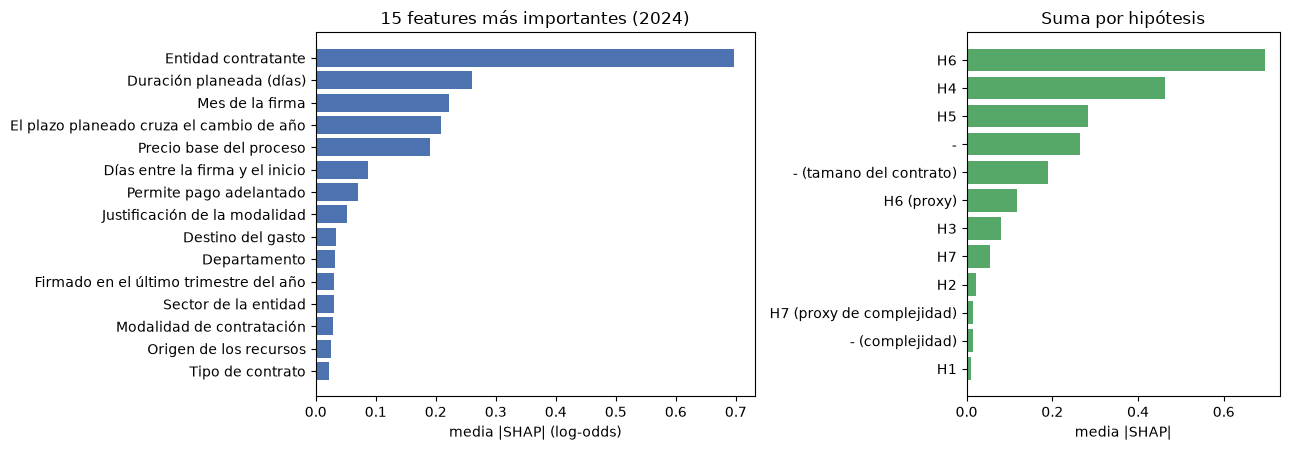

In [56]:
sh = pd.read_csv(RES / "j3_shap_global_2024.csv", index_col=0)
print(f"Error de aditividad máximo: {j3['shap']['error_aditividad_max']:.1e} (la suma de SHAP reproduce la salida del modelo)")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
top = sh.head(15)[::-1]
ax[0].barh([F.NOMBRES_LEGIBLES[f] for f in top.index], top["media_abs_shap"], color="#4C72B0")
ax[0].set_xlabel("media |SHAP| (log-odds)"); ax[0].set_title("15 features más importantes (2024)")
h = sh.groupby("hipotesis")["media_abs_shap"].sum().sort_values()
ax[1].barh(h.index, h.values, color="#55A868"); ax[1].set_title("Suma por hipótesis"); ax[1].set_xlabel("media |SHAP|")
plt.tight_layout(); plt.show()

**Interpretación:**
- **H6 (historia de la entidad)** es la señal dominante: `nit_entidad`, vía el `TargetEncoder`, suma más que cualquier otro grupo. Es coherente con que la regla por entidad sola ya llegue a 0,470 de PR-AUC.
- **H4 (calendario)**: el mes de la firma y si el fin planeado cruza el año son la segunda familia. Coincide con el EDA: enero 34 % de positivos frente a noviembre 16 %.
- **H5 (duración planeada)** y el **tamaño del contrato** (precio base) vienen después.
- **H2 (competencia)** y **H1 (tiempo entre publicación y firma)** aportan muy poco; la ablación de las 8 por verificar (casi todas de H2) lo confirma.
- Una advertencia: SHAP muestra en qué se apoya el modelo, no causalidad.

# 3.7 Métricas


**Para qué se usa el modelo:** una veeduría u oficina de control interno no puede revisar todos los contratos; revisa una lista corta. Lo que importa es **ordenar bien** y que los primeros de la lista sean de verdad contratos que terminan prorrogados.

| Métrica | Por qué |
|---|---|
| **PR-AUC** (principal) | resume la precisión en todos los cortes de la lista; con 25 % de positivos el ROC-AUC puede verse bien aunque los primeros puestos estén llenos de falsos positivos |
| **Precisión y recall en el top 1, 5 y 10 %** | es la decisión real: "si reviso el 5 % de mayor riesgo, ¿qué fracción estaba bien elegida y qué fracción de las prórrogas capturé?" |
| **ROC-AUC** | capacidad de ordenar, independiente de la tasa base; sirve para comparar años con tasas distintas |
| **ROC-AUC dentro de entidad** | lo que ve quien vigila una sola entidad: la regla por entidad da 0,5 ahí por construcción |
| **Tasa base** | siempre al lado: un PR-AUC de 0,58 solo se entiende frente a 0,25 |

No se usan exactitud ni F1 con un umbral fijo: el modelo entrega un orden, y la probabilidad cruda queda descalibrada cuando cambia la tasa (train 0,289, test 2024 0,247).

In [57]:
from sklearn.metrics import precision_recall_curve

pipe, meta = modelo_io.cargar_modelo(config.MODELS / "modelo_prorroga_v1.joblib")
y_te = base.loc[idx_te, "y"].to_numpy()
ent_tr, ent_te = base.loc[idx_tr, "nit_entidad"], base.loc[idx_te, "nit_entidad"]
m = json.loads((RES / "j3_resumen.json").read_text(encoding="utf-8"))["m_regla"]
s = {"modelo v1": pipe.predict_proba(X.loc[idx_te])[:, 1],
     "regla por entidad": E.regla_tasa_entidad(ent_tr, base.loc[idx_tr, "y"], ent_te, m)}
print(f"Test 2024: {len(y_te):,} contratos, tasa base {y_te.mean():.3f}")

Test 2024: 88,088 contratos, tasa base 0.247


## Curva precisión-recall y precisión en los primeros k

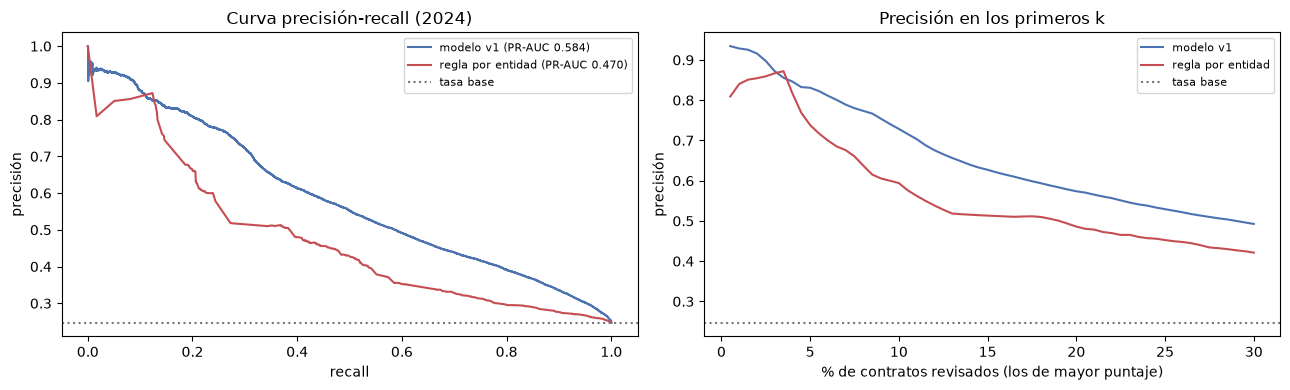

,p@1%,p@5%,p@10%,r@1%,r@5%,r@10%
modelo v1,0.928,0.831,0.729,0.038,0.168,0.295
regla por entidad,0.840,0.738,0.594,0.034,0.149,0.240


In [58]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for (nombre, sc), color in zip(s.items(), ["#4C72B0", "#C44E52"]):
    p, r, _ = precision_recall_curve(y_te, sc)
    ax[0].plot(r, p, color=color, label=f"{nombre} (PR-AUC {E.metricas(y_te, sc)['pr_auc']:.3f})")
    fr = np.linspace(0.005, 0.3, 60)
    ax[1].plot(fr * 100, [E.metricas(y_te, sc, (f,))[f"p@{f:.0%}"] for f in fr], color=color, label=nombre)
for a in ax:
    a.axhline(y_te.mean(), color="#777", ls=":", label="tasa base")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precisión"); ax[0].set_title("Curva precisión-recall (2024)"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("% de contratos revisados (los de mayor puntaje)"); ax[1].set_ylabel("precisión"); ax[1].set_title("Precisión en los primeros k"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
pd.DataFrame({k: {c: E.metricas(y_te, v)[c] for c in ["p@1%", "p@5%", "p@10%", "r@1%", "r@5%", "r@10%"]} for k, v in s.items()}).T

**Interpretación:** si la veeduría revisa el 5 % de mayor riesgo de 2024 (unos 4.400 contratos), con el modelo el 83 % termina con el plazo ampliado, frente al 74 % con la regla por entidad y al 25 % al azar. En el 10 % la diferencia es mayor (73 % frente a 59 %). Ojo: entre el 2 % y el 4 % las dos curvas casi se tocan; la ventaja del modelo en la parte más alta de la lista es pequeña y crece a partir del 5 %. El recall en esos cortes es bajo (17 % en el top 5 %) porque hay muchos más positivos que contratos revisables: la lista sirve para priorizar, no para encontrar todas las prórrogas.

## ROC-AUC dentro de entidad

In [59]:
r = E.roc_auc_intra_entidad(y_te, s["modelo v1"], ent_te, n_boot=200)
print(f"Modelo v1: por pares {r['pares']:.3f} [{r['pares_ic'][0]:.3f}, {r['pares_ic'][1]:.3f}] | "
      f"promedio por entidad {r['por_entidad']:.3f} [{r['por_entidad_ic'][0]:.3f}, {r['por_entidad_ic'][1]:.3f}]")
print(f"Calculado sobre {r['n_entidades']:,} entidades con ambas clases y {r['n_pares']:,} pares. La regla da 0,500 por construcción.")

Modelo v1: por pares 0.701 [0.604, 0.753] | promedio por entidad 0.703 [0.691, 0.716]
Calculado sobre 1,199 entidades con ambas clases y 11,953,889 pares. La regla da 0,500 por construcción.


**Interpretación:** dentro de una misma entidad, el modelo pone más arriba al contrato que se prorroga en el 70 % de los pares. La regla no puede ordenar nada ahí (todos los contratos de la entidad tienen el mismo puntaje). Es lo que necesita una oficina de control interno que solo vigila su propia entidad.

## Desempeño por tramo de duración planeada

**Decisión:** reportar también las métricas por tramo de `p_dur_dias`: hasta 3 meses (≤ 90 días), 3 a 6, 6 a 12 y más de 12 meses, y un grupo «sin dato» para la duración 0 o faltante.
- **Alternativas:** una sola cifra global; tramos por tamaño del contrato.
- **Por qué:** el desenlace se observa meses después de la firma. Hay que verificar que el modelo también funciona cuando el plazo es largo, y no solo cuando el contrato es corto y el resultado llega pronto (`docs/01_definicion_problema.md`, «Sobre el horizonte»). La duración 0 es un dato sin diligenciar (3.2), así que va aparte y no con los contratos de menos de 3 meses.
- **Evidencia:** la tabla siguiente, con las predicciones del modelo v1 sobre el test 2024 (maduros) y la regla por entidad como comparación.

In [60]:
dur = X.loc[idx_te, "p_dur_dias"]
tramo = E.tramo_duracion(dur.where(dur > 0))          # duración 0 o faltante -> «sin dato» (decisión de 3.2)
por_tramo = {k: E.evaluar_por_grupo(y_te, v, tramo).set_index("grupo") for k, v in s.items()}
v1, regla = por_tramo["modelo v1"], por_tramo["regla por entidad"]
t = pd.DataFrame({"n": v1["n"], "% positivos": (100 * v1["tasa_base"]).map("{:.1f} %".format),
                  "PR-AUC v1": v1["pr_auc"], "ROC-AUC v1": v1["roc_auc"],
                  "PR-AUC regla": regla["pr_auc"], "ROC-AUC regla": regla["roc_auc"]})
t = t.reindex(["<=3 meses", "3-6 meses", "6-12 meses", ">12 meses", "sin dato"])
total = {k: E.metricas(y_te, v) for k, v in s.items()}
t.loc["todos"] = [len(y_te), f"{100 * y_te.mean():.1f} %", total["modelo v1"]["pr_auc"], total["modelo v1"]["roc_auc"],
                  total["regla por entidad"]["pr_auc"], total["regla por entidad"]["roc_auc"]]
t

,n,% positivos,PR-AUC v1,ROC-AUC v1,PR-AUC regla,ROC-AUC regla
grupo,,,,,,
<=3 meses,33598,22.2 %,0.668,0.824,0.585,0.756
3-6 meses,29819,25.6 %,0.435,0.699,0.332,0.610
6-12 meses,18635,27.0 %,0.594,0.801,0.438,0.677
>12 meses,448,76.3 %,0.908,0.758,0.822,0.602
sin dato,5588,23.6 %,0.441,0.715,0.339,0.628
todos,88088,24.7 %,0.584,0.781,0.470,0.682


**Interpretación:** el modelo le gana a la regla por entidad en los cinco tramos, tanto en PR-AUC como en ROC-AUC. Rinde mejor en los contratos de hasta 3 meses (ROC-AUC 0,82) y en los de 6 a 12 meses (0,80), y es más débil en los de 3 a 6 meses (ROC-AUC 0,70; PR-AUC 0,435 frente a una tasa de positivos de 25,6 %). Cuando el plazo es largo no pierde capacidad de ordenar: en 6 a 12 meses el ROC-AUC es 0,80 y en más de 12 meses 0,76. Este último tramo tiene solo 448 contratos y 76 % de positivos, así que su PR-AUC alto (0,91) se debe sobre todo a la tasa base y su estimación es inestable. El grupo «sin dato» (5.588 contratos) queda a media altura (ROC-AUC 0,72). Son cifras por tramo, sin intervalo por entidad: los tramos con pocos contratos se leen como indicativos.

## Lo que muestra la app: nivel de riesgo y percentil

La app no muestra la probabilidad cruda. Muestra el percentil del puntaje frente a los contratos de 2024 y un nivel (bajo, medio, alto) con los umbrales del `.json` del modelo. Los umbrales son definitivos: los percentiles 70 y 90 del puntaje en 2024.

In [61]:
u = meta["umbrales_riesgo"]
sc = s["modelo v1"]
nivel = np.where(sc >= u["alto"], "alto", np.where(sc >= u["medio"], "medio", "bajo"))
print("El artefacto conserva la etiqueta 'provisional' de cuando se generó; los umbrales se fijaron en p70/p90 sin cambios.")
t = pd.DataFrame({"y": y_te, "nivel": nivel}).groupby("nivel")["y"].agg(contratos="size", tasa_de_prorroga="mean").reindex(["bajo", "medio", "alto"])
t["% de los contratos"] = t["contratos"] / t["contratos"].sum() * 100
print(f"Umbrales: medio >= {u['medio']:.3f}, alto >= {u['alto']:.3f} ({u['metodo'].split(';')[0]})")
t

El artefacto conserva la etiqueta 'provisional' de cuando se generó; los umbrales se fijaron en p70/p90 sin cambios.
Umbrales: medio >= 0.334, alto >= 0.588 (percentiles 70 y 90 del puntaje en el test 2024 (maduros))


,contratos,tasa_de_prorroga,% de los contratos
nivel,,,
bajo,61661,0.142,69.999
medio,17618,0.375,20.000
alto,8809,0.729,10.000


**Interpretación:** en 2024 el nivel alto (10 % de los contratos) tiene 73 % de prórrogas, el medio 38 % y el bajo 14 %. Los niveles separan bien el riesgo y son fáciles de explicar a una persona sin formación técnica: "de cada 10 contratos en nivel alto, unos 7 terminaron con el plazo ampliado".

# 3.8 Despliegue e interfaz

[URL y capturas: se agregan al desplegar]

**Qué pide el enunciado:** el modelo debe desplegarse con una interfaz que una persona sin conocimientos técnicos pueda usar.

**Qué hicimos:** una app de Streamlit en la que se pega el número de un contrato de SECOP II. Consulta datos.gov.co, arma las mismas variables del entrenamiento y muestra el nivel de riesgo, el percentil y los factores que más pesan, con avisos.

Datos: [datos.gov.co](https://www.datos.gov.co), Colombia Compra Eficiente (SECOP II), licencia CC BY-SA 4.0.

In [62]:
from src import api_secop as A, explicacion as EX

RUTA_BASE = config.BASE_V1
print("Base local disponible:", RUTA_BASE.exists())

Base local disponible: True


## Qué ingresa el usuario

**Decisión:** el usuario solo pega el número del contrato (`CO1.PCCNTR.n`) o el enlace de su página. La app hace el resto.

**Alternativas consideradas:**
- Un formulario con las variables del contrato.
- Pegar la referencia del contrato.
- Pegar el número del proceso.

**Por qué:**
- Un formulario obliga a conocer variables como el código UNSPSC o los conteos de proponentes. Quien vigila un contrato no las tiene a la mano.
- Según los metadatos del dataset, `id_contrato` es "el identificador del contrato firmado, generado por la plataforma". La referencia la genera cada entidad y no es única, y `CO1.BDOS.n` identifica el proceso, no el contrato. Si el usuario pega un número de proceso, la app se lo explica.

**Evidencia:** la tabla siguiente sale del código de la app y del entrenamiento, no está escrita a mano.

In [63]:
familias = F.tabla_features().groupby("familia")["feature"].count()
tabla_usuario = pd.DataFrame({
    "1. Lo que pega el usuario": ["El número del contrato (CO1.PCCNTR.n) o el enlace de su página de SECOP II"],
    "2. Lo que consulta la app": [
        f"Contratos (jbjy-vk9h): {len(A.COLS_CONTRATO_API)} columnas. "
        f"Procesos (p6dx-8zbt): {len(A.COLS_PROCESO_API)} columnas. Una petición por segundo."],
    "3. Las variables que construye": [
        f"{len(F.FEATURES)} features, las mismas del entrenamiento y todas disponibles al firmar: "
        + ", ".join(f"{k} ({v})" for k, v in familias.items())],
    "4. Lo que descarta y por qué": [
        f"{len(F.COLUMNAS_FUGA)} columnas de fuga (estado, fecha de fin, valor, pagos, liquidación...): no se piden "
        f"aunque la API las devuelva actualizadas. {len(config.PII)} columnas con datos personales: nunca se piden. "
        f"Identidad del proveedor: excluida por privacidad (Ley 1581 de 2012)."],
}).T
tabla_usuario.columns = [""]
with pd.option_context("display.max_colwidth", None):
    display(tabla_usuario)

,
1. Lo que pega el usuario,El número del contrato (CO1.PCCNTR.n) o el enlace de su página de SECOP II
2. Lo que consulta la app,Contratos (jbjy-vk9h): 27 columnas. Procesos (p6dx-8zbt): 17 columnas. Una petición por segundo.
3. Las variables que construye,"39 features, las mismas del entrenamiento y todas disponibles al firmar: Calendario (4), Contrato (17), Entidad (5), Geografia (2), Proceso (12)"
4. Lo que descarta y por qué,"66 columnas de fuga (estado, fecha de fin, valor, pagos, liquidación...): no se piden aunque la API las devuelva actualizadas. 29 columnas con datos personales: nunca se piden. Identidad del proveedor: excluida por privacidad (Ley 1581 de 2012)."


In [64]:
# Lo que se le pide a la API: solo columnas de entrada. Si alguna fuera de fuga o de datos personales, esto falla.
pedidas = set(A.COLS_CONTRATO_API) | set(A.COLS_PROCESO_API)
assert not pedidas & F.COLUMNAS_FUGA, "se estaria pidiendo una columna de fuga"
assert not pedidas & config.PII, "se estaria pidiendo una columna con datos personales"
print(f"Columnas pedidas a la API: {len(pedidas)} | de fuga: {len(pedidas & F.COLUMNAS_FUGA)} | personales: {len(pedidas & config.PII)}")

Columnas pedidas a la API: 44 | de fuga: 0 | personales: 0


## Cómo fluye una consulta

```
Usuario ──número o enlace──> app (Streamlit) ──> src/api_secop.py: extrae CO1.PCCNTR.n
                                                       │
                datos.gov.co: Contratos + Procesos (1 petición/s, solo columnas de entrada)
                                                       │
        elegir_proceso → unir_contrato_proceso → construir_features   (las mismas funciones del entrenamiento)
                                                       │
                   modelo guardado (models/) → puntaje → nivel de riesgo y percentil
                                                       │
            SHAP → 5 factores en lenguaje claro  +  avisos  +  aclaración de alcance
```

**Decisión:** la app no tiene su propia copia de la lógica de variables: llama a `construir_features`, la misma función que usó el entrenamiento.

**Por qué:** si la app y el entrenamiento calcularan las variables por separado, el modelo recibiría en producción datos distintos de los que vio al entrenar, y nada fallaría a la vista. **Evidencia:** la prueba de paridad de más abajo.

## Qué muestra la app

**Decisión:** mostrar el **nivel de riesgo** (bajo, medio, alto) y el **percentil**, no la probabilidad cruda.

**Alternativas consideradas:** mostrar la probabilidad (por ejemplo, "23 %").

**Por qué:** con la deriva de los datos (ver 3.9) la probabilidad queda descalibrada, y una cifra exacta sugiere una precisión que el modelo no tiene. El percentil dice algo que sí se sostiene: dónde queda este contrato frente a los de referencia. Para quien prioriza qué vigilar primero, el orden importa más que el valor.

**Evidencia:** los tres ejemplos de la pantalla de la app (los de `app/app.py`), calculados con el modelo v1 y el mismo código de la app (desde la copia local, sin red):

In [65]:
import re

# Los tres ejemplos de la pantalla de la app (app/app.py), elegidos con el modelo v1.
EJEMPLOS = dict(re.findall(r'"Riesgo (alto|medio|bajo)": "(CO1\.PCCNTR\.\d+)"', (RAIZ / "app" / "app.py").read_text(encoding="utf-8")))
explicador = EX.Explicador(pipe)              # TreeExplainer sobre el estimador final del artefacto v1 (3.5)
print("Modelo:", meta["version"], "| modelo_prorroga_v1.joblib")

if RUTA_BASE.exists():
    filas, explicaciones = [], {}
    for etiqueta, idc in EJEMPLOS.items():
        c = A.consulta_desde_respaldo(RUTA_BASE, idc)
        e = explicador.explicar(c.features, c.contrato)
        nivel, pct = EX.nivel_y_percentil(e.puntaje, meta)
        explicaciones[etiqueta] = e
        top = e.aportes.iloc[0]
        filas.append({"ejemplo": etiqueta, "entidad": c.contrato["nombre_entidad"], "firma": c.contrato["fecha_de_firma"],
                      "nivel": nivel, "percentil": round(pct), "factor principal": f"{top['nombre']}: {top['valor']}",
                      "avisos": ", ".join(c.avisos) or "-"})
    display(pd.DataFrame(filas))
else:
    print("No hay base local: este ejemplo se ejecuta con data/processed/v1_A/base_contratos.parquet")

Modelo: v1.0 | modelo_prorroga_v1.joblib


,ejemplo,entidad,firma,nivel,percentil,factor principal,avisos
0,alto,ALCALDIA LOCAL DE TUNJUELITO,2024-12-20,alto,95,Entidad contratante: ALCALDIA LOCAL DE TUNJUELITO,-
1,medio,MUNICIPIO DE YARUMAL,2024-01-30,medio,80,"Precio base del proceso: $ 2,2 mil millones",-
2,bajo,MUNICIPIO DE MANIZALES,2024-01-05,bajo,30,Entidad contratante: MUNICIPIO DE MANIZALES,-


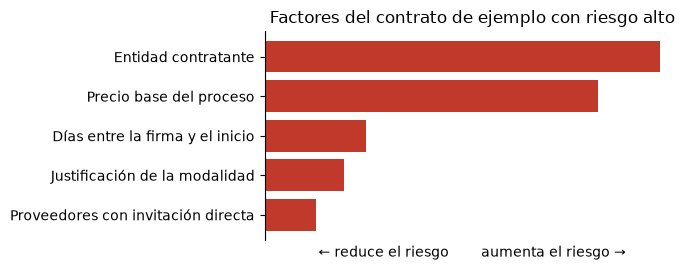

In [66]:
if RUTA_BASE.exists():
    e = explicaciones["alto"]
    datos = e.aportes.head(5).iloc[::-1]
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(datos["nombre"], datos["aporte"], color=["#c0392b" if a > 0 else "#2e86c1" for a in datos["aporte"]])
    ax.axvline(0, color="#555", linewidth=0.8)
    ax.set_xticks([])
    ax.set_xlabel("← reduce el riesgo        aumenta el riesgo →")
    ax.set_title("Factores del contrato de ejemplo con riesgo alto")
    for lado in ("top", "right", "bottom"):
        ax.spines[lado].set_visible(False)
    plt.tight_layout()
    plt.show()

**Interpretación:** el gráfico muestra la dirección de cada factor, no su valor, porque los valores están en log-odds y no le dicen nada a un usuario sin conocimientos técnicos. Cada factor se lee frente a un contrato típico: "sube" o "baja" el riesgo respecto al promedio del modelo.

## Explicación con SHAP: se verifica que sea correcta antes de mostrarla

**Decisión:** explicar con `TreeExplainer` sobre el estimador final y **verificar la aditividad en cada consulta**: la suma de los valores SHAP más el valor base debe reproducir la salida del modelo (error máximo menor que 1e-3). Si no se cumple, la app oculta los factores y muestra solo el nivel.

**Alternativas consideradas:**
- Un explicador genérico sobre `predict_proba` (más lento).
- No mostrar factores.

**Por qué:** `TreeExplainer` sobre un `HistGradientBoostingClassifier` con categorías nativas no lanza error pero da atribuciones incorrectas (error de hasta 13,6 log-odds en una prueba sintética). Una explicación equivocada que parece correcta es peor que ninguna. Por eso el explicador se niega a crearse si el modelo usa categorías nativas.

**Evidencia:** aditividad sobre 300 contratos de 2024 con el modelo cargado:

In [67]:
if RUTA_BASE.exists():
    base24 = pd.read_parquet(RUTA_BASE, columns=A.COLS_RESPALDO + ["anio_firma"], filters=[("anio_firma", "==", 2024)])
    muestra = base24.sample(300, random_state=config.SEED)
    errores = []
    for i in range(len(muestra)):
        fila = muestra.iloc[[i]]
        errores.append(explicador.explicar(F.construir_features(fila)).error_aditividad)
    errores = np.array(errores)
    display(pd.DataFrame({"contratos": [len(errores)], "error máximo": [f"{errores.max():.1e}"], "error mediano": [f"{np.median(errores):.1e}"],
                          "criterio": [EX.TOLERANCIA_ADITIVIDAD], "cumple": [bool((errores < EX.TOLERANCIA_ADITIVIDAD).all())]}))

,contratos,error máximo,error mediano,criterio,cumple
0,300,7.5e-14,6.2e-15,0.001,True


**Interpretación:** con el modelo final (v1) el error máximo es del orden de 1e-13 (7,6e-14 en 300 contratos), diez órdenes de magnitud por debajo del criterio, así que la app muestra los factores. El v1 no usa categorías nativas (3.5), que es la condición para que `TreeExplainer` sea exacto.

## La app y el entrenamiento ven los mismos datos

**Evidencia:** prueba de paridad (`python -m src.paridad_api`). Toma 21 contratos de la base (3 por año de firma, 2019-2025), los pide a datos.gov.co y compara, variable por variable, lo que arma la app contra lo que tiene la base de entrenamiento.

**Por qué importa:** la API devuelve las fechas con hora y la base las tiene truncadas al día. Si la app no las truncara, `dias_firma_a_inicio` saldría corrido un día. `construir_features` las trunca, y la prueba lo confirma:

In [68]:
paridad = RAIZ / "resultados" / "paridad_api_base.md"
display(Markdown(paridad.read_text(encoding="utf-8")) if paridad.exists() else "Falta resultados/paridad_api_base.md")

# Paridad API frente a base

- Fecha de la prueba: 2026-10-26 11:36
- Contratos comparados: 21 (3 por anio de firma, 2019-2025, semilla 42)
- Celdas comparadas (contratos x 39 features): 819
- Celdas distintas: 0
- Peticiones a datos.gov.co: 2

Compara `construir_features` aplicada a lo que devuelve la API contra la aplicada a las filas de la base v1.


**Interpretación:** 819 celdas comparadas y ninguna diferencia. Como el modelo solo recibe esas 39 variables, el puntaje es el mismo con los datos de la API que con los de la base (la prueba también lo comprobó con el modelo de prueba; con el v1 se deduce de lo anterior y no se repitió con la API). La consulta en vivo no introduce una diferencia entre entrenamiento y uso. El resultado guardado se regenera con `python -m src.paridad_api`, que consulta la API.

## Aviso de «entidad sin historial»

**Decisión:** si la entidad del contrato no tiene contratos en el entrenamiento, la app lo avisa: el modelo no conoce sus hábitos (H6) y solo se apoya en el contrato.
- **Por qué:** la entidad es la señal más fuerte (3.6). En entidades no vistas el modelo sigue ordenando (ROC-AUC 0,721 en 2024), pero con menos información.
- **Evidencia:** un contrato de 2024 de una entidad que el modelo no vio y otro de una que sí. El `.json` del v1 guarda la lista de entidades vistas.

In [69]:
vistas = {str(v) for v in meta["entidades_vistas"]}
base24 = base[base["anio_firma"] == 2024]
nit = base24["nit_entidad"].astype(str)
print(f"El .json del modelo trae {len(vistas):,} entidades vistas")
for etiqueta, idc in (("entidad no vista", base24.loc[~nit.isin(vistas), "id_contrato"].iloc[0]),
                      ("entidad vista", base24.loc[nit.isin(vistas), "id_contrato"].iloc[0])):
    c = A.consulta_desde_respaldo(RUTA_BASE, idc)
    print(f"{etiqueta}: {idc} ({c.contrato['nombre_entidad']}) -> avisos del modelo: {A.avisos_del_modelo(c.features, meta) or 'ninguno'}")

El .json del modelo trae 2,330 entidades vistas
entidad no vista: CO1.PCCNTR.5707694 (CENTRO DE SALUD FUNES ESE) -> avisos del modelo: ['entidad_sin_historial']


entidad vista: CO1.PCCNTR.5687204 (HOSPITAL DEPARTAMENTAL UNIVERSITARIO SANTA SOFIA DE CALDAS) -> avisos del modelo: ninguno


## Dónde se publica y qué se midió

**Decisión:** Streamlit Community Cloud, con el modelo y la app en el mismo repositorio público.

**Alternativas consideradas:** Hugging Face Spaces y Render.

**Por qué:** despliega desde el mismo repositorio y se actualiza en cada `push`; la RAM de la app cabe con holgura en el mínimo de la plataforma. Hugging Face exige un repositorio aparte y Render gratuito ofrece unos 512 MB, demasiado justo para `shap` y `scikit-learn` [SUPUESTO, no verificado].

**Evidencia:**

| Dato | Valor |
|---|---|
| RAM de la app en local con el modelo v1 (modelo, explicador y 3 consultas con su gráfico) | 242 MB [VERIFICADO en local: Python 3.12, Windows, proceso limpio]; en la nube [NO EVALUADO] hasta desplegar |
| Mínimo de RAM por app en Community Cloud | 690 MB (máximo 2,7 GB), aproximado a febrero de 2024 |
| Apps sin tráfico | se duermen a las 12 horas |
| Si se cargara la base completa como respaldo | 1.019 MB: por eso el respaldo busca el contrato por lotes y no carga la base |

El detalle y los pasos están en `docs/DESPLIEGUE.md`.

## Limitaciones

- La app usa el **modelo v1** (`models/modelo_prorroga_v1.joblib`); si ese archivo falta, usa un modelo de prueba y lo avisa en pantalla.
- La explicación dice qué pesó en el puntaje del modelo, **no** por qué se amplía un contrato: no es una relación causal.
- En los tres ejemplos, el factor principal es la entidad o el precio base del proceso, como en el SHAP global de 3.6. La fecha de inicio (`dias_firma_a_inicio`) es la variable con riesgo de fuga que quedó con limitación: sin ella y sin `fin_planeado_cruza_anio`, el PR-AUC de 2024 baja solo 0,004 (3.6).
- La RAM en la nube y la URL pública se completan al desplegar [NO EVALUADO].
- La app estima riesgo de **ampliación del plazo**, no detecta irregularidades ni corrupción, y es una herramienta de priorización: la decisión de revisar un contrato es de una persona.


# 3.9 Estrategia de reajuste del modelo

**Qué pide el enunciado:** diseñar cómo se detectaría que el modelo se degradó o que los datos cambiaron, con qué criterio y frecuencia se reentrenaría, y cómo se validaría y pondría en producción la versión nueva.

**Qué hicimos:** definimos qué se mide y cuándo salta cada alarma, y lo probamos con una simulación de 2024-2025: un modelo congelado, entrenado con 2019-2023, se recorre mes a mes y trimestre a trimestre con la base v1.

> Las cifras salen de `python -m src.monitoreo` con el **modelo v1**. Para recalcularlas se pone `RECALCULAR = True` en la celda de configuración del inicio (este script tarda unos 70 s).

**Base medida en 3.6 (deriva 2025).** El modelo congelado 2019-2023 baja de 0,584 a 0,550 de PR-AUC en 2025 pero le sigue ganando a la regla; reentrenar con 2019-2024 no mejora el PR-AUC (0,550 en los dos casos). Por eso el artefacto v1 se queda en 2019-2023 y el reentrenamiento se decide con el protocolo campeón-retador que se describe más abajo. `src/modelo.py: construir_pipeline()` es el que usa el monitoreo para reentrenar.


In [70]:
from src import monitoreo as M

mensual = pd.read_csv(RES / "monitoreo_mensual.csv")
trimestral = pd.read_csv(RES / "monitoreo_trimestral.csv")
historico = pd.read_csv(RES / "monitoreo_psi_historico.csv")
cr = json.loads((RES / "monitoreo_campeon_retador.json").read_text(encoding="utf-8"))
print(f"Meses simulados: {len(mensual)} | trimestres: {len(trimestral)} | contratos de la evaluación campeón/retador: {cr['n_evaluacion']:,}")

Meses simulados: 24 | trimestres: 8 | contratos de la evaluación campeón/retador: 80,652


## Qué puede cambiar

Un modelo de este problema se enfrenta a cinco tipos de cambio, y todos aparecen en estos datos:

| Tipo | Ejemplo en los datos |
|---|---|
| Cambian las **entradas** | `dias_firma_a_inicio`: antes de 2021 muchos contratos tenían el inicio anterior a la firma |
| Cambia el **comportamiento** | el 1 % de mayor puntaje de 2025-T3 era casi todo de una entidad que no amplió sus plazos |
| Cambia el **registro de la etiqueta** | `y_dias` salta en 2025 por cómo se guarda `dias_adicionados` |
| **Estacionalidad** | la tasa de positivos va de 34 % en enero a 16 % en octubre |
| Etiquetas **tardías** | el resultado se conoce meses después de firmar |

Lo comprobamos con los datos:

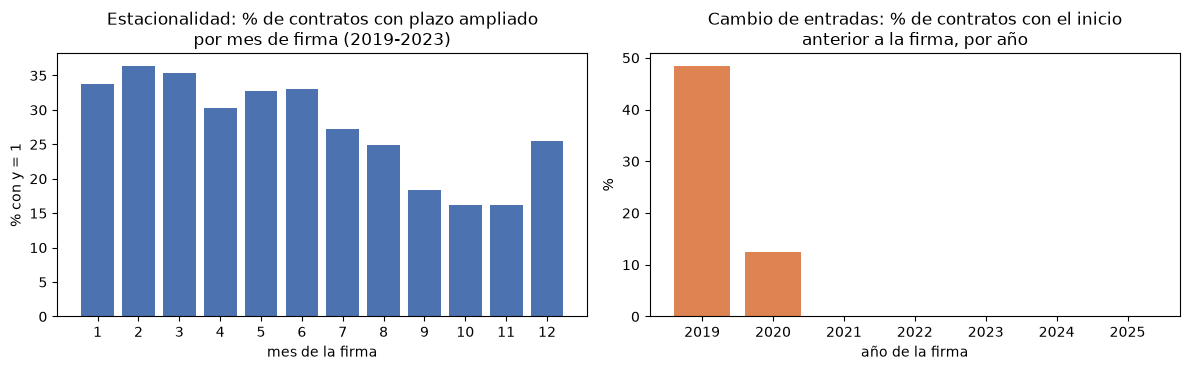

In [71]:
BASE = config.BASE_V1
if BASE.exists():
    b = pd.read_parquet(BASE, columns=["fecha_de_firma", "fecha_de_inicio_del_contrato", "anio_firma", "y", "eval_madura"])
    firma, inicio = b["fecha_de_firma"].dt.normalize(), pd.to_datetime(b["fecha_de_inicio_del_contrato"]).dt.normalize()
    b["inicio_antes_de_firma"] = (inicio - firma).dt.days < 0

    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
    por_mes = b[(b["anio_firma"] <= 2023) & b["eval_madura"]].groupby(b["fecha_de_firma"].dt.month)["y"].mean()
    ejes[0].bar(por_mes.index, 100 * por_mes.values, color="#4C72B0")
    ejes[0].set_title("Estacionalidad: % de contratos con plazo ampliado\npor mes de firma (2019-2023)")
    ejes[0].set_xlabel("mes de la firma"); ejes[0].set_ylabel("% con y = 1"); ejes[0].set_xticks(range(1, 13))
    cambio = 100 * b.groupby("anio_firma")["inicio_antes_de_firma"].mean()
    ejes[1].bar(cambio.index, cambio.values, color="#DD8452")
    ejes[1].set_title("Cambio de entradas: % de contratos con el inicio\nanterior a la firma, por año")
    ejes[1].set_xlabel("año de la firma"); ejes[1].set_ylabel("%")
    plt.tight_layout(); plt.show()
else:
    print("Esta celda usa data/processed/v1_A/base_contratos.parquet")

**Interpretación:**
- **Estacionalidad.** La tasa de positivos cambia más de 2 veces según el mes. Si el monitor comparara un mes contra un promedio anual, saltaría una alarma cada enero sin que nada hubiera cambiado. Por eso todas las comparaciones son contra **el mismo mes o trimestre del año anterior**.
- **Cambio de régimen.** En 2019 el 48 % de los contratos tenía la fecha de inicio anterior a la firma, en 2020 el 12 %, y desde 2021 casi ninguno. Por eso la referencia del monitor son los años 2022-2023 y no todo el entrenamiento: con 2019-2023 una variable que ya no cambia saldría siempre como "distinta".

## Qué se mide, con qué frecuencia y cuándo salta cada alarma

**Decisión:** tres capas con frecuencias distintas.

| Capa | Frecuencia | Por qué esa frecuencia |
|---|---|---|
| **Entradas y puntaje** (PSI) | Mensual | No necesita etiquetas: las entradas se conocen al firmar |
| **Desempeño** (ROC-AUC, PR-AUC, precisión en el top 1 %) | Trimestral | Necesita etiquetas, que llegan con retraso, y el ROC-AUC mensual oscila de 0,71 a 0,87 solo por la composición de cada mes |
| **Etiqueta** (tasa de positivos) | Trimestral | Detecta cambios de comportamiento y de registro |

**Alternativas consideradas:** un solo indicador mensual de desempeño; comparar contra el promedio histórico.

**Por qué no:** el desempeño mensual es ruido, y el promedio histórico no separa la estacionalidad de un cambio real.

**Evidencia:** las reglas, tal como están en el código (`src/monitoreo.py`):

In [72]:
reglas = pd.DataFrame([
    ("PSI de 10 entradas, cada mes", f"{M.MIN_VARIABLES_REVISAR} o más variables con PSI ≥ {M.PSI_AVISO}, o una ≥ {M.PSI_ALARMA}", "revisar; nunca reentrena por sí solo"),
    ("PSI del puntaje, cada mes", f"≥ {M.PSI_AVISO} (aviso), ≥ {M.PSI_ALARMA} (alarma)", "frente al mismo mes del año anterior"),
    ("Tasa de positivos, cada trimestre", f"cambio ≥ {M.DELTA_TASA_BASE:.0%} frente al mismo trimestre", "investigar: ¿comportamiento o registro?"),
    ("ROC-AUC, cada trimestre", f"cae ≥ {M.DELTA_ROC} y el IC 95 % por entidad excluye 0", f"alarma si se repite {M.PERSISTENCIA} trimestres seguidos"),
    ("Precisión del 1 % de mayor puntaje", "menor que la tasa base del trimestre", f"alarma si se repite {M.PERSISTENCIA} trimestres seguidos"),
    ("Cohorte con etiquetas", f"solo si ≥ {M.MADUREZ_MIN:.0%} de sus contratos ya maduró", "si no, se espera"),
], columns=["Señal", "Aviso", "Acción"])
pd.set_option("display.max_colwidth", None)
display(reglas)

,Señal,Aviso,Acción
0,"PSI de 10 entradas, cada mes","2 o más variables con PSI ≥ 0.1, o una ≥ 0.25",revisar; nunca reentrena por sí solo
1,"PSI del puntaje, cada mes","≥ 0.1 (aviso), ≥ 0.25 (alarma)",frente al mismo mes del año anterior
2,"Tasa de positivos, cada trimestre",cambio ≥ 5% frente al mismo trimestre,investigar: ¿comportamiento o registro?
3,"ROC-AUC, cada trimestre",cae ≥ 0.03 y el IC 95 % por entidad excluye 0,alarma si se repite 2 trimestres seguidos
4,Precisión del 1 % de mayor puntaje,menor que la tasa base del trimestre,alarma si se repite 2 trimestres seguidos
5,Cohorte con etiquetas,solo si ≥ 95% de sus contratos ya maduró,"si no, se espera"


## Simulación 2024-2025

El modelo se entrenó con 2019-2023 y no se vuelve a entrenar. A continuación, lo que el monitor habría mostrado.

### Entradas y puntaje (mensual)

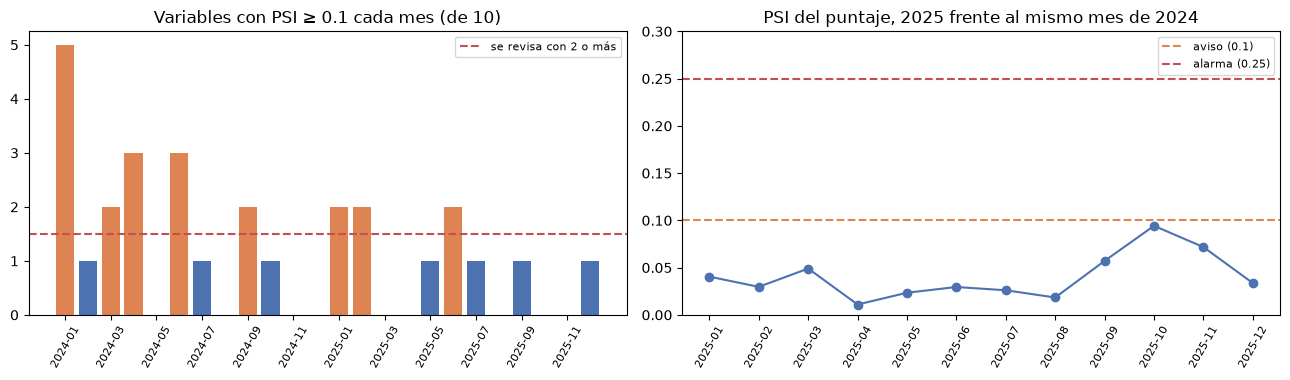

,PSI de las entradas,mediana,% de valores ≥ 0.25
0,entre años consecutivos del entrenamiento (2021-2023),0.090,28.750
1,producción 2024-2025,0.032,0.833


In [73]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 3.9))
x = np.arange(len(mensual))
color = np.where(mensual["estado_entradas"] == "revisar", "#DD8452", "#4C72B0")
ejes[0].bar(x, mensual["n_variables_psi_alto"], color=color)
ejes[0].axhline(M.MIN_VARIABLES_REVISAR - 0.5, color="#C44E52", linestyle="--", label=f"se revisa con {M.MIN_VARIABLES_REVISAR} o más")
ejes[0].set_xticks(x[::2]); ejes[0].set_xticklabels(mensual["mes"][::2], rotation=60, fontsize=8)
ejes[0].set_title(f"Variables con PSI ≥ {M.PSI_AVISO} cada mes (de 10)"); ejes[0].legend(fontsize=8)

p = mensual.dropna(subset=["psi_score_vs_anio_anterior"])
ejes[1].plot(p["mes"], p["psi_score_vs_anio_anterior"], marker="o", color="#4C72B0")
ejes[1].axhline(M.PSI_AVISO, color="#DD8452", linestyle="--", label=f"aviso ({M.PSI_AVISO})")
ejes[1].axhline(M.PSI_ALARMA, color="#C44E52", linestyle="--", label=f"alarma ({M.PSI_ALARMA})")
ejes[1].set_ylim(0, 0.3); ejes[1].tick_params(axis="x", rotation=60, labelsize=8)
ejes[1].set_title("PSI del puntaje, 2025 frente al mismo mes de 2024"); ejes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

cols = M.FEATURES_PSI["num"] + M.FEATURES_PSI["cat"]
hist, prod = historico[cols].stack(), mensual[["psi_" + c for c in cols]].stack()
display(pd.DataFrame({"PSI de las entradas": ["entre años consecutivos del entrenamiento (2021-2023)", "producción 2024-2025"],
                      "mediana": [hist.median(), prod.median()],
                      f"% de valores ≥ {M.PSI_ALARMA}": [100 * (hist >= M.PSI_ALARMA).mean(), 100 * (prod >= M.PSI_ALARMA).mean()]}).round(3))

**Interpretación:**
- **Entradas.** En 8 de 24 meses el monitor pide revisar (2 o más variables con PSI alto). Las que más pesan son la duración planeada y el sector.
- **Puntaje.** Los 12 meses de 2025 quedan normales frente al mismo mes de 2024 (PSI máximo 0,094): el modelo reparte los puntajes como el año anterior.
- **El PSI avisa, pero no decide.** Entre años consecutivos del propio entrenamiento el PSI ya era mucho mayor que el de 2024-2025, porque el SECOP II creció y cambió rápido. Un PSI alto, por sí solo, no significa que el modelo falle. Por eso las entradas **nunca** disparan el reentrenamiento: sirven para investigar, y el desempeño con etiquetas decide.

### Etiqueta y desempeño (trimestral, solo cohortes completas)

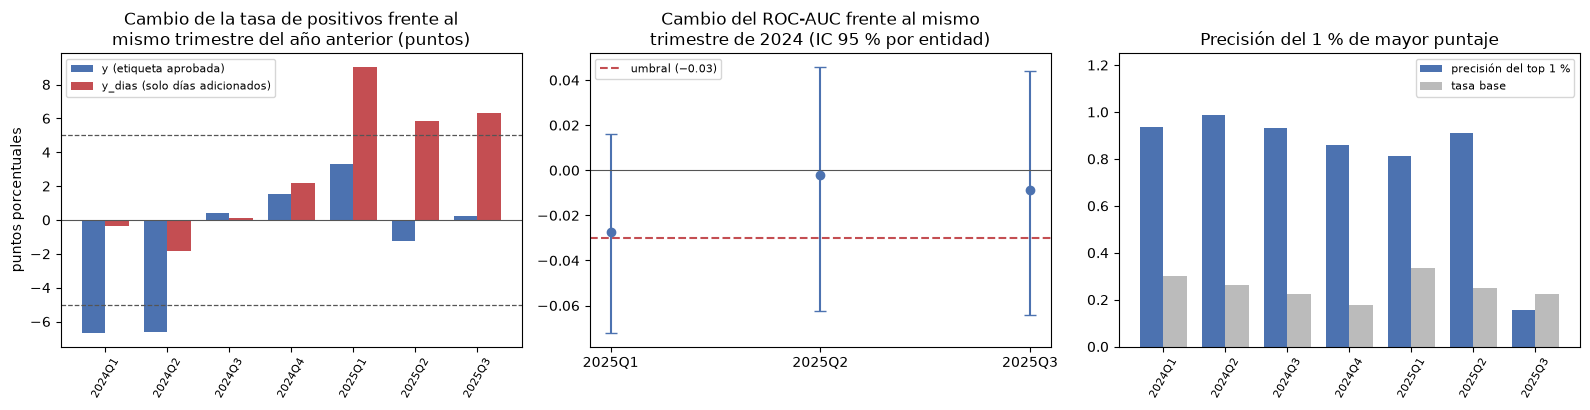

,trimestre,madurez,tasa_y,tasa_y_dias,delta_tasa_y_dias,roc_auc,precision_top,concentracion_top
0,2024Q1,0.999,0.301,0.130,-0.004,0.771,0.935,0.354
1,2024Q2,0.995,0.262,0.130,-0.018,0.737,0.989,0.870
2,2024Q3,0.993,0.223,0.109,0.001,0.752,0.931,0.313
3,2024Q4,0.991,0.178,0.112,0.022,0.847,0.860,0.532
4,2025Q1,0.998,0.334,0.220,0.091,0.743,0.812,0.373
5,2025Q2,0.992,0.249,0.188,0.058,0.735,0.911,0.464
6,2025Q3,0.984,0.225,0.172,0.063,0.743,0.154,0.819
7,2025Q4,0.914,NaN,NaN,NaN,NaN,NaN,NaN


In [74]:
t = trimestral.copy()
completos = t[t["completo"]]

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))
dt = completos.dropna(subset=["delta_tasa_y"])
i0 = np.arange(len(dt)); ancho0 = 0.38
ejes[0].bar(i0 - ancho0 / 2, 100 * dt["delta_tasa_y"], ancho0, label="y (etiqueta aprobada)", color="#4C72B0")
ejes[0].bar(i0 + ancho0 / 2, 100 * dt["delta_tasa_y_dias"], ancho0, label="y_dias (solo días adicionados)", color="#C44E52")
for umbral in (-M.DELTA_TASA_BASE, M.DELTA_TASA_BASE):
    ejes[0].axhline(100 * umbral, color="#555", linestyle="--", linewidth=0.9)
ejes[0].axhline(0, color="#555", linewidth=0.8)
ejes[0].set_xticks(i0); ejes[0].set_xticklabels(dt["trimestre"], rotation=60, fontsize=8)
ejes[0].set_title("Cambio de la tasa de positivos frente al\nmismo trimestre del año anterior (puntos)")
ejes[0].set_ylabel("puntos porcentuales"); ejes[0].legend(fontsize=8, loc="upper left")

d = completos.dropna(subset=["delta_roc_auc"])
ejes[1].errorbar(d["trimestre"], d["delta_roc_auc"], yerr=[d["delta_roc_auc"] - d["ic_inf_roc_auc"], d["ic_sup_roc_auc"] - d["delta_roc_auc"]],
                 fmt="o", color="#4C72B0", capsize=4)
ejes[1].axhline(0, color="#555", linewidth=0.8)
ejes[1].axhline(-M.DELTA_ROC, color="#C44E52", linestyle="--", label=f"umbral (−{M.DELTA_ROC})")
ejes[1].set_title("Cambio del ROC-AUC frente al mismo\ntrimestre de 2024 (IC 95 % por entidad)"); ejes[1].legend(fontsize=8)

ancho = 0.38; i = np.arange(len(completos))
ejes[2].bar(i - ancho / 2, completos["precision_top"], ancho, label="precisión del top 1 %", color="#4C72B0")
ejes[2].bar(i + ancho / 2, completos["tasa_y"], ancho, label="tasa base", color="#BBBBBB")
ejes[2].set_xticks(i); ejes[2].set_xticklabels(completos["trimestre"], rotation=60, fontsize=8)
ejes[2].set_ylim(0, 1.25); ejes[2].set_title("Precisión del 1 % de mayor puntaje"); ejes[2].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

cols = ["trimestre", "madurez", "tasa_y", "tasa_y_dias", "delta_tasa_y_dias", "roc_auc", "precision_top", "concentracion_top"]
display(t[cols].round(3))

**Interpretación:**
- **`y_dias` sube y `y` no (izquierda).** Se compara cada trimestre con el mismo trimestre del año anterior para quitar la estacionalidad. En los tres trimestres completos de 2025 `y_dias` sube entre 6 y 9 puntos y `y` cambia menos de 4. El monitor salta, pero la causa es el registro de `dias_adicionados`, no un cambio de comportamiento: si se hubiera usado `y_dias` como etiqueta, **reentrenar habría sido un error**. Es la razón por la que se diagnostica antes de reentrenar. Aparte, `y` baja unos 6,7 puntos en 2024-T1 y T2 frente a 2023: es un aviso cuya causa no se evaluó [NO EVALUADO], y el ROC-AUC de esos trimestres no se degradó.
- **El ROC-AUC se mantiene (centro).** Frente al mismo trimestre de 2024 cambia −0,027, −0,002 y −0,009, con intervalos que incluyen 0: no hay degradación. El −0,027 de 2025-T1 queda cerca del umbral de 0,03, pero su intervalo [−0,072, +0,016] incluye 0 y no genera aviso. Los intervalos son anchos (±0,04 a ±0,05), así que un monitor trimestral solo detecta caídas de unos 0,05 o más.
- **El top 1 % de 2025-T3 falla (derecha).** Su precisión (0,15) queda por debajo de la tasa base (0,22) aunque el ROC-AUC global casi no cambió: el 82 % de esos contratos son de una sola entidad que no amplió sus plazos. Es un cambio de comportamiento que las métricas globales esconden, y por eso existe esta regla.
- **2025-T4 no se evalúa:** solo el 91 % de sus contratos ha madurado. Una cohorte incompleta solo tiene los contratos de plazo corto y daría una conclusión sesgada.

## Cuándo se reentrena

**Decisión:** se reentrena en cuatro casos, y nunca por un PSI alto por sí solo.

1. **Alarma de desempeño:** el ROC-AUC cae dos trimestres seguidos, o el top 1 % queda peor que el azar dos trimestres seguidos.
2. **Cambio confirmado de la etiqueta o de su registro:** primero se corrige la etiqueta y luego se reentrena.
3. **Revisión programada una vez al año**, cuando maduran los contratos del año anterior: se prueba un retador y se promueve solo si gana según la regla de abajo.
4. **Cambio estructural conocido** (una norma, una migración de plataforma) respaldado por un PSI sostenido.

**Alternativas consideradas:** reentrenar cada mes o cada trimestre sin condición.

**Por qué no:** reentrenar sin diagnosticar puede empeorar el modelo, como habría pasado con `y_dias`; y las etiquetas tardan meses en llegar, así que un reentrenamiento muy frecuente entrenaría con cohortes incompletas.

## Cómo se valida y se promueve una versión nueva

**Decisión:** campeón/retador sobre los **mismos contratos**, con intervalos por entidad.

**Regla de promoción:** el IC 95 % de la mejora en PR-AUC debe excluir 0 y el ROC-AUC no debe empeorar claramente más de 0,01.

**Alternativas consideradas:** promover al retador si su métrica es más alta; probar sobre un único trimestre.

**Por qué no:** una diferencia de milésimas puede ser ruido, y los contratos de una misma entidad están correlacionados, así que remuestrear contratos daría intervalos demasiado optimistas.

**Evidencia:** campeón (entrenado con 2019-2023) frente a retador (2019-2024), evaluados en los trimestres completos de 2025, que ninguno de los dos vio:

In [75]:
resumen = pd.DataFrame({
    "métrica": ["PR-AUC", "ROC-AUC"],
    "campeón": [cr["pr_auc_campeon"], cr["roc_auc_campeon"]],
    "retador": [cr["pr_auc_retador"], cr["roc_auc_retador"]],
    "diferencia": [cr["delta_pr_auc"]["delta"], cr["delta_roc_auc"]["delta"]],
    "IC 95 % inferior": [cr["delta_pr_auc"]["ic_inf"], cr["delta_roc_auc"]["ic_inf"]],
    "IC 95 % superior": [cr["delta_pr_auc"]["ic_sup"], cr["delta_roc_auc"]["ic_sup"]],
}).set_index("métrica")
display(resumen.round(3))
print(f"Contratos de evaluación: {cr['n_evaluacion']:,} ({', '.join(cr['trimestres'])})")
print("Decisión de la regla de promoción:", cr["decision"])
assert cr["decision"] == M.decision_promocion(cr["delta_pr_auc"], cr["delta_roc_auc"])

,campeón,retador,diferencia,IC 95 % inferior,IC 95 % superior
métrica,,,,,
PR-AUC,0.544,0.542,-0.002,-0.020,0.032
ROC-AUC,0.746,0.764,0.018,0.008,0.028


Contratos de evaluación: 80,652 (2025Q1, 2025Q2, 2025Q3)
Decisión de la regla de promoción: no promover: sin evidencia suficiente de mejora


**Interpretación:** reentrenar con un año más (2024) no mejora al modelo en 2025 según la regla: el PR-AUC del retador es 0,002 menor y su IC [−0,020, +0,032] incluye 0. El ROC-AUC sí sube (+0,018, IC [+0,008, +0,028]), pero la regla promueve según el PR-AUC, la métrica principal, y usa el ROC-AUC solo para que no empeore. La regla dice **no promover**. Tiene sentido: el modelo no se degradó (sección anterior), así que no había nada que corregir. La misma regla habría promovido a un retador que mejorara con claridad.

**Poner en producción una versión nueva:**
1. Reconstruir la base con el corte nuevo, pasar `calidad.py` y revisar la lista de fuga.
2. Entrenar el retador con la ventana que crece y buscar hiperparámetros con los folds temporales.
3. Comparar con el campeón con la regla de arriba, y revisar también las entidades no vistas y el top 1 %.
4. Guardar `modelo_prorroga_v<N>.joblib` y su `.json` (versiones del entorno, features, sha256, percentiles y umbrales, entidades vistas); `cargar_modelo` rechaza un artefacto incompatible.
5. Abrir un PR revisado por otro integrante: la app usa el modelo de mayor versión y la plataforma se redespliega con el `push`. Se verifica la paridad entre API y base, la aditividad de SHAP y los ejemplos de la app.
6. Conservar el campeón anterior un trimestre: volver atrás es revertir el commit.

## Limitaciones

- La simulación entrena con las **etiquetas finales** de 2019-2023 [SUPUESTO]; en producción real el modelo solo habría visto las disponibles el día de la puesta en marcha.
- Los umbrales se fijaron conociendo el comportamiento de 2024-2025: no hay un periodo aparte para validar las reglas del monitor [NO EVALUADO].
- En la demostración campeón-retador, el retador usa los mismos hiperparámetros del modelo v1: no se repite la búsqueda.
- Un monitor trimestral solo detecta caídas grandes del ROC-AUC (unos 0,05 o más).
- Solo está **diseñado**, no automatizado: correría como una tarea programada que consulte la API, calcule estas tablas y avise.
- Una degradación se detecta con el retraso con que llegan las etiquetas (de 6 a 12 meses).

El detalle de las reglas y su justificación está en `docs/REAJUSTE.md`.